# 🔎📚 Lab 04: RAG Evaluation Pipeline

## Module 04: Evaluating Retrieval-Augmented Systems 📚

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04-rag-evaluation-lab.ipynb)

> 🕵️ **The case.** An internal policy assistant answers employee questions about PTO, expenses, benefits and stock. Every answer is fluent and confident, and most pass the automated checks you'll build. Before the lab ends you'll find an answer that passes **every** check, retrieval *and* faithfulness, and is still wrong. You'll also catch the system answering questions it should have declined. **Would you ship it?**

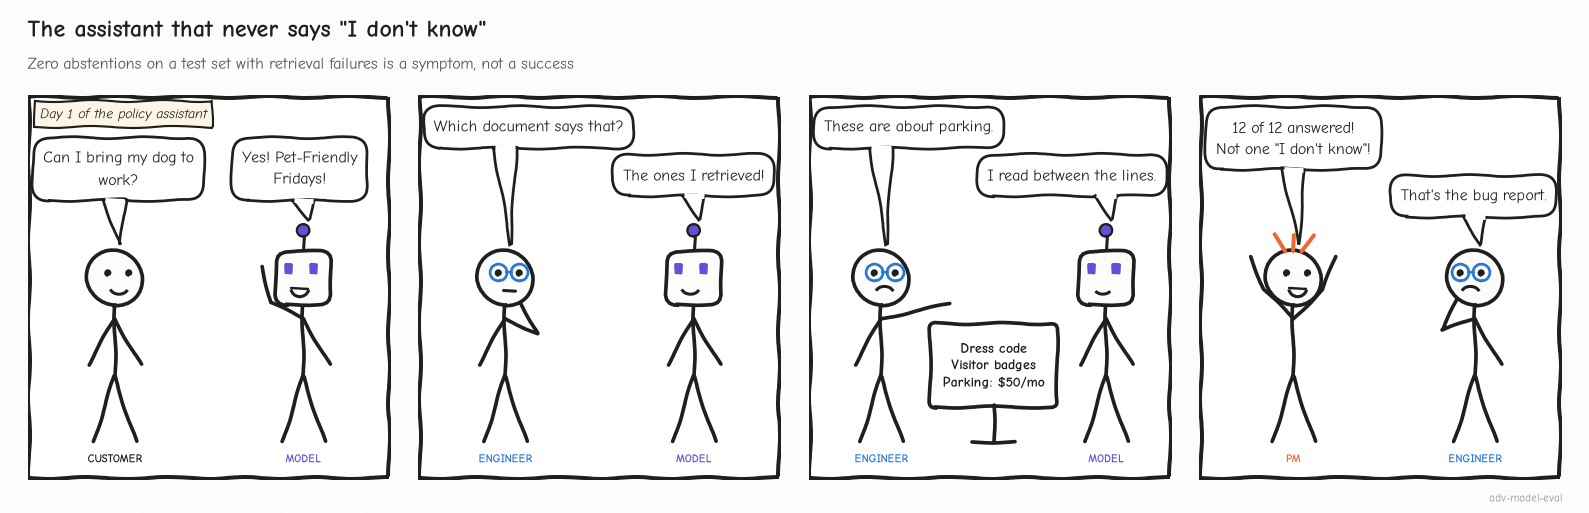

<sub>🖼️ *The assistant answers everything. By the end of Task 2 you'll know why that's the first red flag.*</sub>

| | |
|---|---|
| ⏱️ **Time** | 40–45 min hands-on (Tasks 10–11 can shrink to 5 min each) |
| 🎚️ **Level** | Intermediate |
| 🔑 **Keys needed** | None. Runs offline after a one-time ~90 MB NLI model download |
| 🧰 **Tools** | `sentence-transformers` (NLI cross-encoder) · `pandas` · `numpy` · `matplotlib` |
| ✍️ **You'll write** | Grounding criteria (Task 5), stress tests (Task 10), failure analysis (Task 11) |
| 🏁 **You'll leave with** | Retrieval, faithfulness and **context-sufficiency** scores, a selective-answer metric (coverage vs. accuracy), a root cause for every query, and a ship/block verdict |
| ➡️ **Next** | Lab 04b builds a *real* RAG pipeline (chunking, hybrid search, reranking) and evaluates it |

---

## 🧭 Overview

A **Retrieval-Augmented Generation (RAG)** system answers in two steps: a **retriever** fetches the K passages most similar to the question, then a **generator** (an LLM) writes an answer from them. Either step can fail, and so can the decision to answer at all. You'll measure each one separately on a company-policy assistant:

| Question | Stage | Measured by |
|---|---|---|
| Did we fetch the right documents? | Retrieval | Recall@K, Precision@K, nDCG, MRR (Task 4) |
| Does the answer stick to what was fetched? | Generation | **Faithfulness** (Tasks 5–6) |
| Is the answer true? | End to end | **Correctness** against the current handbook (Task 8) |
| Could *anyone* answer from this context, and should the system have declined? | Both | **Context sufficiency** and abstention (Task 9) |

<details>
<summary>📖 <b>Jargon decoder: 35 terms this lab uses (click to open)</b></summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **RAG** (retrieval-augmented generation) | Look up passages first, then have an LLM write the answer from them | Everywhere |
| **Retriever / generator** | The search step that picks passages / the LLM that writes from them | Overview, Task 7 |
| **Chunk** (here: doc) | A passage cut from a document and stored for search; each doc here is one short policy | Task 2 |
| **Corpus / index** | Every document you *could* retrieve / the searchable store built from it | Tasks 4, 8 |
| **Top-K** | The K highest-scoring chunks handed to the LLM (K = 5 here) | Task 4 |
| **Relevance label** | A person's 1/0 call: is this doc on-topic for the question? On-topic ≠ contains the answer | Tasks 2, 4, 9 |
| **Recall@K / hit rate** | Share of the relevant docs that made the top K / share of queries with at least one | Task 4 |
| **Precision@K** | Share of the top K that are relevant (how much noise came along) | Task 4 |
| **nDCG@K** | A 0–1 ranking score that gives more credit for relevant docs near the top | Task 4 |
| **MRR** (mean reciprocal rank) | Average of 1 ÷ (rank of the first relevant doc) | Task 4 |
| **Grounding / faithfulness** | Every claim in the answer is supported by the retrieved docs (not "is true") | Tasks 5–6 |
| **Distortion / fabrication / hallucination** | A changed fact / a claim with no source at all / the umbrella term for confident unsupported output | Tasks 5, 7 |
| **Stop words** | Very common words a word-counting scorer throws away before comparing texts | Task 6 |
| **Claim / claim-level scoring** | One checkable statement in an answer (here, one sentence) / scoring each claim on its own, then keeping the weakest | Task 6, Challenge 5 |
| **NLI** (natural language inference) | A model that reads a **premise** and a **hypothesis** and says *entailment* (supports), *contradiction* or *neutral* | Task 6 |
| **Cross-encoder vs. embedding** | Reads both texts together in one pass / turns each text into a vector separately and compares the vectors | Task 6 |
| **Logits / softmax** | A model's raw scores / the step that turns them into probabilities summing to 1 | Task 6 |
| **Miss rate / false-alarm rate** | Bad answers a scorer passes / good answers it flags | Task 6 |
| **TPR / TNR** | True-positive rate (1 − miss rate) / true-negative rate (1 − false-alarm rate) | Tasks 6, 9 |
| **Trace / span** | The record of one request through the pipeline / one step inside it | Task 7 |
| **OpenTelemetry (OTel)** | The open standard for recording traces; its GenAI conventions name LLM spans | Task 7 |
| **Root cause** | The earliest pipeline stage that went wrong | Task 7 |
| **Ground truth / correctness** | The trusted right answer (here: the current handbook) / whether the answer matches it | Task 8 |
| **SME** | Subject-matter expert; here a benefits specialist who grades answers | Task 8 |
| **Doc-derived (synthetic) set vs. production sample** | Questions written while reading the docs / questions real users typed | Task 8 |
| **95% CI / Wilson interval** | The range of true rates consistent with your score / a CI formula that behaves at small n | Task 8 |
| **Index hygiene / freshness metadata** | Removing outdated versions from search / tagging each chunk with its effective date | Tasks 8, 11 |
| **Abstention / over-refusal** | Declining to answer / declining when the answer *was* in the docs | Tasks 2, 9 |
| **Context sufficiency / key facts** | Whether the retrieved text contains everything needed to answer / the facts an answer must include | Task 9 |
| **Coverage / selective accuracy** | Share of questions answered / share of *answered* questions that are correct | Task 9 |
| **Autorater (LLM judge)** | An LLM prompted to grade something, here sufficiency | Task 9 |
| **Stress test / probe** | A question written to make the system fail in a specific way | Task 10 |
| **CI pipeline** (continuous integration) | The automated tests that run on every change; not the confidence interval | Task 11 |
| **PTO · stipend · per diem** | Paid time off · a fixed allowance for a purpose · a fixed daily travel allowance | Queries 1, 9, 13, 15 |
| **401(k) · match · vesting · stock options** | US workplace retirement account · employer money added when you contribute · employer money becoming yours over time · the right to buy shares at a set price, which vest, can be *exercised* (bought), or are *forfeited* | Queries 5, 12, 14 |

</details>

## 🏗️ What You'll Build: the roadmap

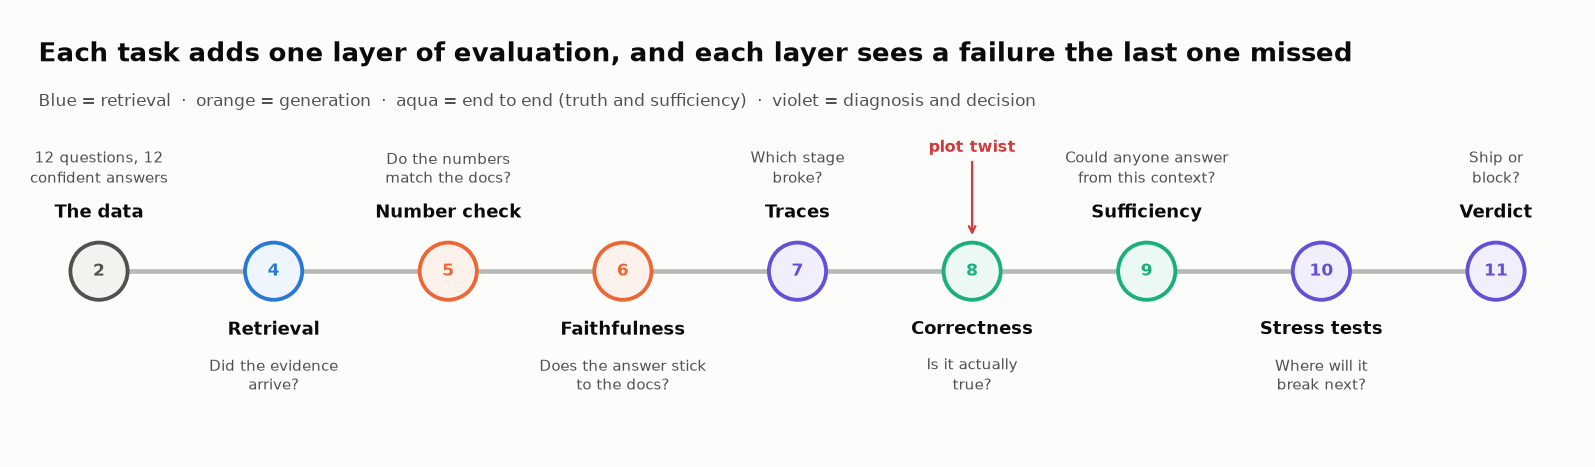

<sub>🖼️ *Nine stops, one question each. Every layer catches a failure the previous ones waved through.*</sub>

## 🗺️ The RAG Evaluation Pipeline

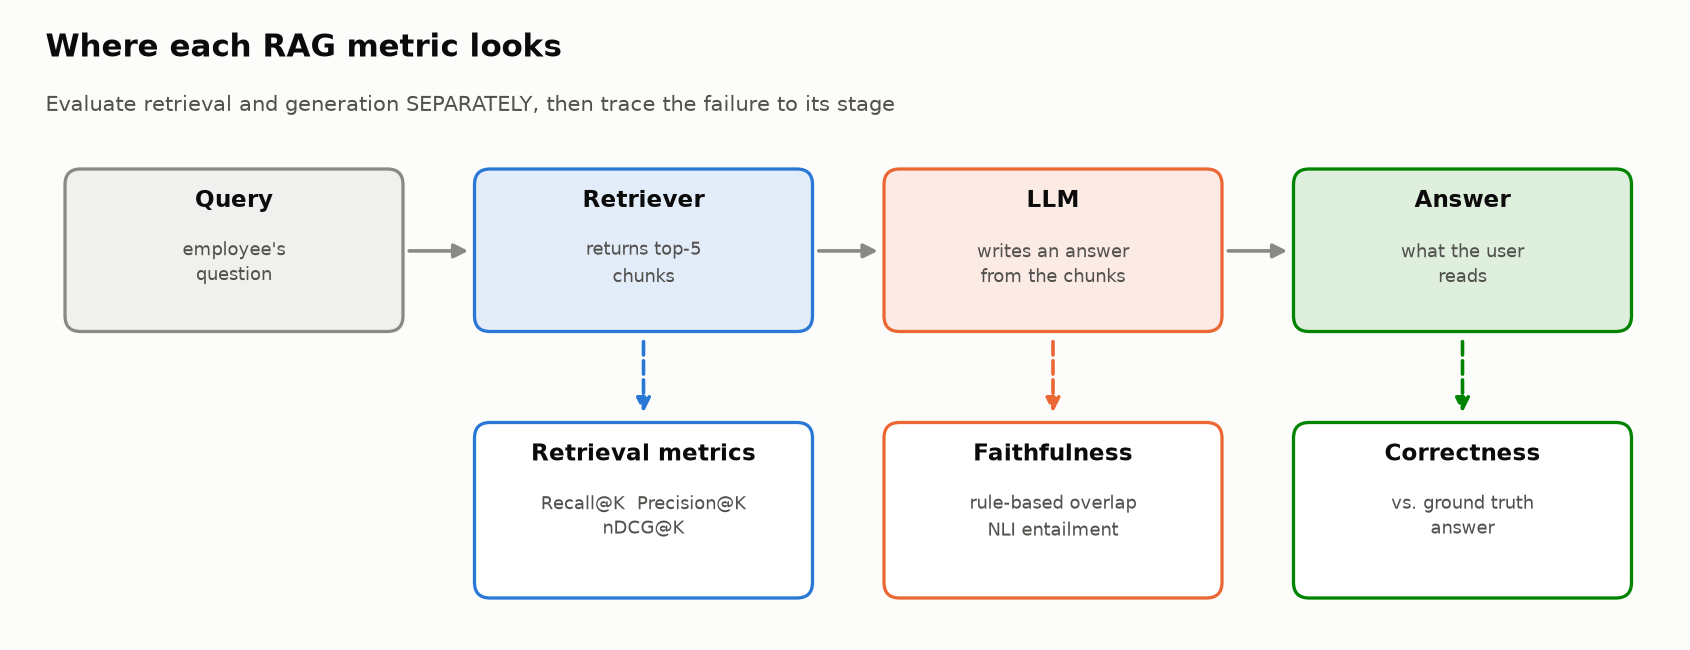

<sub>🖼️ *Where each evaluation technique in this lab plugs into the RAG pipeline*</sub>

## 🎯 Learning Objectives

1. Compute and interpret retrieval metrics (Recall@K, Precision@K, nDCG, MRR), and choose which one to headline
2. Score faithfulness with a deterministic check and with entailment (NLI), and measure each scorer's misses and false alarms
3. Explain why **faithful ≠ correct** and find a faithful-but-wrong answer
4. Label **context sufficiency** and score abstention in both directions (should answer / should decline)
5. Report a **selective-answer metric**: accuracy when answering, together with coverage
6. Trace failures to a root cause and turn the evidence into a ship/block decision

## 📋 Prerequisites

- Module 01 (Modern AI Evaluation Foundations) and Module 02 (Failure Mode Analysis)
- The basic RAG flow: query → retrieval → generation
- Python (pandas, numpy)

## ⏱️ Estimated Time

**40–45 minutes.** Tasks 1–9 are the core path (~35 min); Tasks 10–11 are write-up tasks you can shorten.

## ⚙️ Environment and Setup

- Google Colab or any Python 3.10+ Jupyter kernel. CPU is fine.
- **No API keys.** Every answer is pre-generated, so results are reproducible.
- Task 1 installs `sentence-transformers` and loads the course **lab kit** (insight cards, stat tiles, chart theme).
- Cells titled **🧰** are collapsed plumbing: fixtures, chart helpers, reference checkers. They run under **Run all**; expand one only if you're curious.

## 🎬 Scenario

You're the ML engineer signing off on the policy assistant's company-wide rollout. Management has seen answers that "sound right but aren't," and answers built on clearly wrong documents. You decide whether it ships.

---

## 🛠️ Task 1: Environment Setup and Dependencies

**Stakes:** none yet, by design: every answer in this lab is pre-generated, so your numbers will match your neighbour's and every checkpoint.

🧭 **Where you are:** Act I of IV, *The case* (Tasks 1–3): load the assistant's 12 answers and decide what "trustworthy" should mean before any metric does.

### Goal
Install and import the packages, then load the course lab kit.

### Why This Step?
`sentence-transformers` provides the NLI cross-encoder behind Task 6's faithfulness scorer. The **lab kit** gives you `insight()`, `tiles()` and `verdict()`, which render results as cards instead of walls of prints.

### Steps
1. Run the install cell (1–2 minutes on first run).
2. Run the imports cell.
3. Run the 🎨 Lab kit cell (collapsed in Colab; you don't need to read it).

In [ ]:
%%capture
# Install required packages:
#   sentence-transformers → the NLI cross-encoder for faithfulness scoring (Task 6)
#   pandas / numpy        → tables and numerical operations
#   matplotlib            → one chart per task
!pip install -q sentence-transformers pandas numpy matplotlib

In [ ]:
# Core libraries for data handling and analysis
import re                         # tokenizing answers and extracting numbers
import math                       # Wilson confidence intervals (Task 8)
import json                       # JSON handling (if loading external datasets)
from collections import defaultdict, Counter

import numpy as np                # nDCG log calculations
import pandas as pd               # tables of per-query metrics
import matplotlib.pyplot as plt   # charts

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["axes.axisbelow"] = True   # draw gridlines behind bars
print("✅ All imports successful.")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v1 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()")

### Checkpoint ✅
If you see a `ModuleNotFoundError`, re-run the install cell and restart the kernel.

### Expected Output
```
✅ All imports successful.
🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()
```

➡️ **Bridge:** tools ready. Next, meet the 12 questions and notice what the system *never* says.

---

## 📂 Task 2: Load the RAG Evaluation Dataset

**Stakes:** the first number anyone asks for is accuracy; the first number that predicts an incident is how often the system says "I don't know".

### Goal
Load the team's **offline test set**: 12 policy questions, each with the 5 retrieved documents, a relevance label per document, and the answer the system generated.

### 🎯 Why This Matters
Each entry records one complete trip through the pipeline, so you can score each stage on its own.

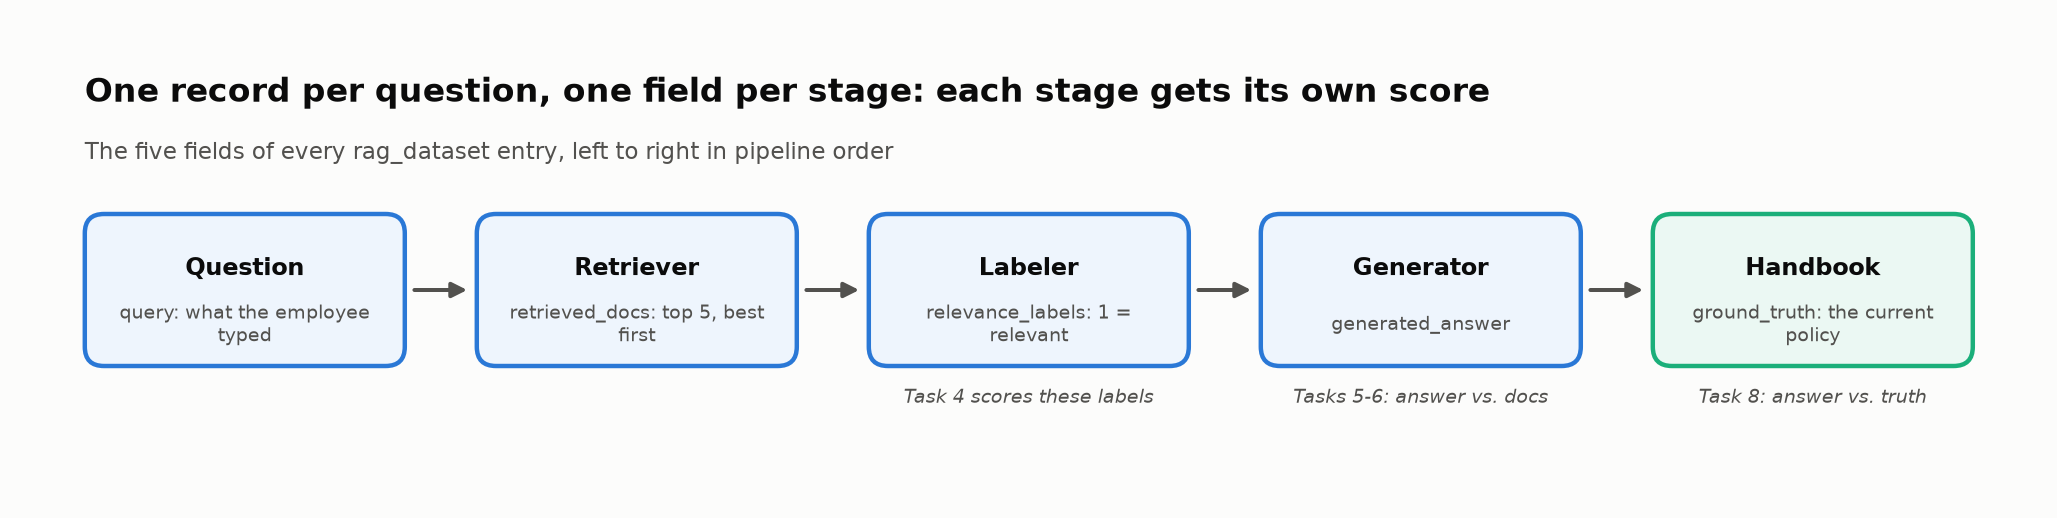
<sub>🖼️ *Read each record left to right. Task 4 scores the labels, Tasks 5–6 the answer against the docs, Task 8 the answer against the handbook.*</sub>

### Dataset Schema
- **query**: the employee's question. The team wrote all 12 while reading the policy docs (this matters in Task 8)
- **retrieved_docs**: the 5 passages the retriever returned, best first. RAG systems retrieve **chunks** (pieces of documents); each chunk here is one short policy, so the lab calls them docs
- **relevance_labels**: a person's judgment per doc: 1 = **relevant** (on-topic for the question), 0 = not. Relevant doesn't guarantee the doc contains the answer; Task 9 checks that separately
- **generated_answer**: the system's response
- **ground_truth**: the correct answer from the current policy handbook

> 🔮 **Predict:** how many of the 12 answers **abstain**, i.e. decline to answer ("I don't know")? (A) 0 · (B) 2, the ones with no relevant docs · (C) 4 or more

### Steps
Run the cells below: the collapsed 🧰 fixture cell builds the 12 records, the next cell lists them, and the last two detect abstentions and summarize.

In [ ]:
# @title 🧰 Fixtures: the 12 offline questions, each with 5 retrieved docs, a relevance label per doc, the system's answer and the handbook truth (hidden · 183 lines · expand to read any record)
# Synthetic RAG evaluation dataset — company policy Q&A system
# Each entry represents one COMPLETE query through the RAG pipeline:
#   query → retriever returns 5 docs → LLM generates answer
#
# Key fields to watch:
#   - relevance_labels: [1,0,0,0,0] means only the 1st doc is relevant
#   - Some queries have 0 relevant docs (retrieval failure!)
#   - Some generated answers contain fabricated information (generation failure!)

rag_dataset = [
    {
        "id": 1,
        "query": "How many PTO days do new employees get?",
        "retrieved_docs": [
            "New full-time employees receive 15 PTO days per year, accrued monthly starting from their hire date.",
            "PTO requests must be submitted at least 2 weeks in advance through the HR portal.",
            "After 5 years of service, employees receive an additional 5 PTO days per year.",
            "Company holidays include New Year's Day, Memorial Day, Independence Day, Labor Day, Thanksgiving, and Christmas.",
            "Part-time employees receive prorated PTO based on their scheduled hours."
        ],
        "relevance_labels": [1, 0, 0, 0, 0],  # Only doc 1 directly answers the question
        "generated_answer": "New full-time employees receive 15 PTO days per year, which accrue monthly starting from their hire date.",
        "ground_truth": "New full-time employees receive 15 PTO days per year, accrued monthly from hire date."
    },
    {
        "id": 2,
        "query": "What is the expense reimbursement limit for client dinners?",
        "retrieved_docs": [
            "Travel expenses must be submitted within 30 days of the trip using the expense management system.",
            "Office supply purchases under $50 do not require pre-approval.",
            "Client entertainment expenses are capped at $150 per person per meal and require a receipt and attendee list.",
            "Employees may expense co-working space fees up to $200/month when traveling.",
            "Annual team-building budgets are allocated at $500 per team member."
        ],
        "relevance_labels": [0, 0, 1, 0, 0],  # Relevant doc is at position 3 (not ideal ranking)
        "generated_answer": "Client dinner expenses are capped at $150 per person per meal. You'll need to submit a receipt and a list of attendees.",
        "ground_truth": "Client entertainment expenses are capped at $150 per person per meal, requiring a receipt and attendee list."
    },
    {
        "id": 3,
        "query": "Can I work remotely from another country?",
        "retrieved_docs": [
            "Remote work is available for all full-time employees with manager approval.",
            "Employees working remotely must maintain core hours of 10am-3pm in their local time zone.",
            "International remote work requires approval from both your manager and the Legal department due to tax and compliance implications. Requests must be submitted 30 days in advance.",
            "Home office equipment stipends of up to $1,000 are available for new remote workers.",
            "VPN access is required for all remote work to ensure secure connections to company systems."
        ],
        "relevance_labels": [0, 0, 1, 0, 0],  # Relevant doc buried at position 3
        "generated_answer": "Yes, you can work remotely from another country, but it requires approval from your manager and the Legal department. You need to submit the request 30 days in advance due to tax and compliance considerations.",
        "ground_truth": "International remote work requires manager and Legal approval, submitted 30 days in advance, due to tax and compliance implications."
    },
    {
        "id": 4,
        "query": "What happens if I exceed my PTO balance?",
        # ⚠️ RETRIEVAL FAILURE: None of these 5 docs are relevant to the question!
        "retrieved_docs": [
            "Company holidays include New Year's Day, Memorial Day, Independence Day, Labor Day, Thanksgiving, and Christmas.",
            "The employee assistance program provides free counseling sessions for stress management.",
            "Parking passes are available at a subsidized rate of $50/month in the company garage.",
            "The cafeteria offers a meal plan at $8/day for employees.",
            "Gym membership reimbursements are available up to $75/month."
        ],
        "relevance_labels": [0, 0, 0, 0, 0],  # ZERO relevant docs — complete retrieval failure
        "generated_answer": "If you exceed your PTO balance, additional days off will be unpaid. You should discuss extended leave options with HR, who can help you explore short-term disability or unpaid leave of absence.",
        "ground_truth": "Days taken beyond the PTO balance are unpaid. Employees must get manager approval for unpaid leave, and HR should be notified for payroll adjustment."
    },
    {
        "id": 5,
        "query": "How does the 401k match work?",
        "retrieved_docs": [
            "The company matches 401(k) contributions dollar-for-dollar up to 4% of base salary. Matching contributions vest over 3 years: 33% after year 1, 66% after year 2, 100% after year 3.",
            "Health insurance enrollment occurs during the annual open enrollment period in November.",
            "Employees can adjust their 401(k) contribution percentage at any time through the benefits portal.",
            "The company offers both traditional and Roth 401(k) options.",
            "Financial planning consultations are available quarterly at no cost to employees."
        ],
        "relevance_labels": [1, 0, 1, 1, 0],  # 3 relevant docs — strong retrieval
        "generated_answer": "The company provides a dollar-for-dollar 401(k) match up to 4% of your base salary. The match vests over 3 years at 33%, 66%, and 100%. You can choose between traditional and Roth 401(k) options and adjust contributions anytime via the benefits portal.",
        "ground_truth": "Dollar-for-dollar match up to 4% of base salary. 3-year vesting schedule (33/66/100%). Both traditional and Roth options available."
    },
    {
        "id": 6,
        "query": "What is the policy on bringing pets to the office?",
        # ⚠️ RETRIEVAL FAILURE + HALLUCINATION: No relevant docs, but the answer sounds confident!
        "retrieved_docs": [
            "The dress code is business casual Monday through Thursday and casual on Fridays.",
            "Visitors must sign in at the front desk and wear a visitor badge at all times.",
            "Food delivery orders should be picked up at the main lobby reception area.",
            "Conference rooms must be booked through the scheduling system at least 1 hour in advance.",
            "The building is non-smoking. Designated smoking areas are located in the parking structure."
        ],
        "relevance_labels": [0, 0, 0, 0, 0],  # ZERO relevant docs — another complete retrieval failure
        "generated_answer": "Pets are welcome in the office on designated Pet-Friendly Fridays. Dogs must be leashed in common areas and owners are responsible for cleanup. Please notify your floor manager in advance.",
        "ground_truth": "The company does not currently have a pet policy. Pets are not permitted in the office unless they are registered service animals."
    },
    {
        "id": 7,
        "query": "How do I report a workplace safety concern?",
        "retrieved_docs": [
            "Workplace safety concerns should be reported immediately to your manager or the Safety Committee via the anonymous reporting hotline at ext. 2222 or through the online safety portal.",
            "All employees must complete annual safety training by December 31st.",
            "Fire extinguishers are located at each stairwell entrance and in the kitchen areas.",
            "First aid kits are available in each break room and at the front desk.",
            "Emergency evacuation routes are posted by each elevator and stairwell."
        ],
        "relevance_labels": [1, 0, 0, 0, 0],  # Only doc 1 is relevant
        "generated_answer": "You can report safety concerns to your manager or use the anonymous Safety Committee hotline at extension 2222. There's also an online safety portal available for reporting.",
        "ground_truth": "Report to manager or Safety Committee via anonymous hotline (ext. 2222) or online safety portal."
    },
    {
        "id": 8,
        "query": "What are the rules for using company credit cards?",
        # ✅ PERFECT RETRIEVAL: All 5 docs are relevant!
        "retrieved_docs": [
            "Company credit cards are issued to employees at the director level and above. All charges must have a business justification and receipt.",
            "Personal charges on company credit cards are strictly prohibited and may result in disciplinary action.",
            "Monthly credit card statements must be reconciled and approved by the cardholder's manager within 15 business days.",
            "Lost or stolen company credit cards must be reported to Finance and the card issuer within 24 hours.",
            "Credit card limits are set based on role: Directors $5,000, VPs $10,000, C-suite $25,000."
        ],
        "relevance_labels": [1, 1, 1, 1, 1],  # ALL 5 docs relevant — best-case retrieval
        "generated_answer": "Company credit cards are available for directors and above. All charges need a business justification and receipt. Personal use is prohibited. Monthly statements must be reconciled within 15 business days with manager approval. Report lost cards to Finance within 24 hours.",
        "ground_truth": "Issued to directors+. Business justification and receipts required. No personal use. Monthly reconciliation within 15 business days. Report lost/stolen within 24 hours."
    },
    {
        "id": 9,
        "query": "Can I use my education stipend for an online bootcamp?",
        "retrieved_docs": [
            "The annual education stipend of $3,000 covers tuition, books, and course materials for job-related education. Eligible programs include accredited degrees, professional certifications, and approved online courses.",
            "Employees must receive manager approval before enrolling and submit receipts for reimbursement within 60 days of course completion.",
            "The mentorship program pairs junior employees with senior leaders for quarterly development conversations.",
            "Internal lunch-and-learn sessions are held every other Friday and count toward professional development hours.",
            "Conference attendance requires VP-level approval and is budgeted separately from the education stipend."
        ],
        "relevance_labels": [1, 1, 0, 0, 0],  # 2 relevant docs
        "generated_answer": "Yes, online bootcamps can be covered under the $3,000 annual education stipend as long as they are job-related. You'll need manager approval before enrolling. After completing the program, submit your receipts within 60 days for reimbursement.",
        "ground_truth": "The $3,000 education stipend covers job-related education including approved online courses. Manager approval required before enrollment, receipts due within 60 days."
    },
    {
        "id": 10,
        "query": "What is the parental leave policy?",
        # ⚠️ GENERATION FAILURE: Retrieval is great, but the answer changes "12 weeks" to "16 weeks"!
        "retrieved_docs": [
            "Full-time employees are eligible for 12 weeks of paid parental leave for the birth, adoption, or foster placement of a child. Leave must begin within 12 months of the qualifying event.",
            "Parental leave can be taken consecutively or split into two blocks with manager approval.",
            "During parental leave, all benefits including health insurance and 401(k) matching continue.",
            "Employees returning from parental leave are guaranteed the same or equivalent position.",
            "Short-term disability insurance covers 60% of salary for up to 26 weeks for medical conditions including pregnancy complications."
        ],
        "relevance_labels": [1, 1, 1, 1, 0],  # 4/5 relevant — very strong retrieval
        "generated_answer": "The company offers 16 weeks of fully paid parental leave for all new parents. You can take it all at once or split it into blocks. Your health insurance and retirement benefits continue during leave.",
        "ground_truth": "12 weeks paid parental leave for birth, adoption, or foster placement. Can be consecutive or split into two blocks. Benefits continue. Same/equivalent position guaranteed on return."
    },
    {
        "id": 11,
        "query": "How do I request a standing desk?",
        "retrieved_docs": [
            "Ergonomic equipment requests including standing desks, monitor arms, and keyboard trays can be submitted through the Facilities portal. Standard processing time is 5-7 business days.",
            "All new employees receive a standard desk setup including a monitor, keyboard, and mouse.",
            "The IT help desk handles requests for additional monitors, docking stations, and peripherals.",
            "Office furniture changes require approval from your floor coordinator to ensure space planning compliance.",
            "Height-adjustable desks are available in two models: manual crank ($400) and electric ($650). Both are covered by the company."
        ],
        "relevance_labels": [1, 0, 0, 1, 1],  # 3 relevant docs
        "generated_answer": "Submit a request through the Facilities portal for a standing desk. Processing takes 5-7 business days. You'll need your floor coordinator's approval. The company covers the cost — choose between a manual crank model or an electric one.",
        "ground_truth": "Request via Facilities portal (5-7 business days). Floor coordinator approval needed. Two models available: manual ($400) and electric ($650), both company-covered."
    },
    {
        "id": 12,
        "query": "What happens to my unvested stock options if I leave?",
        "retrieved_docs": [
            "Stock options vest over a 4-year schedule with a 1-year cliff. After the cliff, options vest monthly.",
            "Upon voluntary termination, employees have 90 days to exercise vested stock options. Unvested options are forfeited.",
            "In the event of involuntary termination without cause, the company may accelerate vesting at its discretion.",
            "Stock option grants are determined annually based on performance review and level.",
            "Tax implications of stock option exercise should be discussed with a personal financial advisor. The company provides access to a tax consultation service."
        ],
        "relevance_labels": [1, 1, 1, 0, 0],  # 3 relevant docs
        "generated_answer": "If you leave the company, your unvested stock options are forfeited. You have 90 days after departure to exercise any vested options. If you were terminated without cause, the company may choose to accelerate vesting, though this is discretionary.",
        "ground_truth": "Unvested options are forfeited on departure. 90 days to exercise vested options. Involuntary termination without cause may trigger discretionary accelerated vesting."
    },
]

In [ ]:
# 📂 The 12 records come from the 🧰 fixture cell above. Tag them, then list each query with its relevant-doc count.
for item in rag_dataset:
    item["source"] = "offline"   # written by the team from the docs (Task 8 adds a production sample)

# Display dataset summary — note how retrieval quality varies across queries
print(f"Loaded {len(rag_dataset)} RAG evaluation examples.\n")

for item in rag_dataset:
    n_relevant = sum(item["relevance_labels"])
    # Flag extreme cases to draw attention
    flag = "⚠️" if n_relevant == 0 else ("🟢" if n_relevant >= 3 else "  ")
    print(f"  {flag} Query {item['id']:2d}: \"{item['query'][:60]}...\"  "
          f"[{n_relevant}/5 relevant docs]")

In [ ]:
# 🙊 Did the system ever decline? A refusal detector you'll reuse all lab long.
ABSTAIN_MARKERS = ("don't have enough information", "couldn't find", "could not find",
                   "not able to find", "i don't know", "no information")

def is_abstention(answer):
    """True if the answer declines to answer instead of making a claim."""
    a = answer.lower()
    # 👀 Look at: a phrase match, not a model; it only has to recognise "I don't know" in its usual wordings
    return any(marker in a for marker in ABSTAIN_MARKERS)

df = pd.DataFrame([{
    "id": item["id"],
    "query": item["query"],
    "n_relevant": sum(item["relevance_labels"]),          # how many of the 5 retrieved docs are relevant?
    "has_relevant": sum(item["relevance_labels"]) > 0,     # did retrieval find ANY relevant doc?
    "abstained": is_abstention(item["generated_answer"]),  # did the system decline to answer?
} for item in rag_dataset])

zero_ids = df.loc[~df["has_relevant"], "id"].tolist()
n_abstain = int(df["abstained"].sum())

In [ ]:
# 📊 The overview: how much evidence each query got, and how often the system declined
tiles([
    ("Queries", len(df), "offline test set", None),
    ("Relevant docs / query", f"{df['n_relevant'].mean():.1f}", "out of 5 retrieved", None),
    ("Zero relevant docs", len(zero_ids), f"queries {zero_ids}", "critical" if zero_ids else "good"),
    ("Answers that abstain", n_abstain, "said \"I don't know\"", "warning" if n_abstain == 0 else "good"),
])
insight(
    f"{len(df) - n_abstain} of {len(df)} answers are confident, including the {len(zero_ids)} with zero evidence",
    f"Queries {zero_ids} retrieved nothing relevant, yet the system still produced fluent, specific answers. "
    "A system that never says \"I don't know\" is telling you about its prompt, not its knowledge.\n"
    "**Rule of thumb:** count abstentions on day one. Zero abstentions on a test set that contains retrieval "
    "failures is a red flag, not a success.",
    kind="warning")
df

### Checkpoint ✅
You should see `Loaded 12 RAG evaluation examples.`, four stat tiles, a ⚠️ *Watch out* card, and a 12-row table. Some queries have 3–5 relevant docs (5, 8, 10); two have none (4, 6).

### Expected Output
```
Loaded 12 RAG evaluation examples.

     Query  1: "How many PTO days do new employees get?..."  [1/5 relevant docs]
     Query  2: "What is the expense reimbursement limit for client dinners..."  [1/5 relevant docs]
  ...
  ⚠️ Query  4: "What happens if I exceed my PTO balance?..."  [0/5 relevant docs]
  ...
```
Tiles: **12** queries · **2.0** relevant docs/query · **2** with zero relevant docs (queries [4, 6]) · **0** answers that abstain.
Card: *"12 of 12 answers are confident, including the 2 with zero evidence."*

**What just happened:** `is_abstention` searched all 12 answers for a refusal phrase and found none, while the relevance labels ran from 0 to 5 relevant docs per query. Queries 4 and 6 got five off-topic docs and answered as fluently as Query 8, which got five on-topic ones: the generator's tone doesn't depend on what it was given.

🗣️ **Say it to a colleague:** "Zero abstentions on a test set with retrieval failures isn't a success metric. It's the first bug report."

➡️ **Bridge:** before computing any metric, decide what "trustworthy" should mean for a RAG answer.

---

## Task 3: 🔍 Think First — What Makes a RAG Response Trustworthy?

**Stakes:** decide what "trustworthy" means before a metric does, or you'll end up optimizing whatever the first metric happened to measure.

### Goal
Write down, before any metric tells you, what makes a RAG answer **trustworthy** and what makes it **dangerous**. Your answers shape every evaluation choice that follows.

### Context
Two responses from the dataset:

**Query 4:** "What happens if I exceed my PTO balance?"
> **Generated answer:** "If you exceed your PTO balance, additional days off will be unpaid. You should discuss extended leave options with HR, who can help you explore short-term disability or unpaid leave of absence."

**Query 6:** "What is the policy on bringing pets to the office?"
> **Generated answer:** "Pets are welcome in the office on designated Pet-Friendly Fridays. Dogs must be leashed in common areas and owners are responsible for cleanup."

Both sound confident and professional. For both, the retriever found **zero relevant documents**, and one of the two answers is invented outright.

### Questions to Reason About

Spend **3–4 minutes**; write your answers in the cell below. No answers are provided.

1. **Trustworthiness signals:** which observable properties of a response, especially its relation to the retrieved documents, would make you trust it?
2. **Danger signals:** what would make you *distrust* a fluent, confident response?
3. **Retrieval vs generation:** can a system retrieve perfect documents and still answer badly? Retrieve irrelevant ones and still answer well? What does each case tell you?
4. **Evaluation priority:** if you could measure only ONE thing, what would it be, and why?
5. **Should it have answered at all?** What was the ideal response to Query 4? How would you score a correct "I don't know" versus one given when the answer *was* in the documents?

### ✍️ Your Reflections

**Write your answers here** (double-click to edit this cell):

1. **Trustworthiness signals:**

   *Your answer...*

2. **Danger signals:**

   *Your answer...*

3. **Retrieval vs Generation:**

   *Your answer...*

4. **Evaluation priority:**

   *Your answer...*

5. **Should it have answered at all?**

   *Your answer...*

### 🔍 Reveal: one of these two answers is right

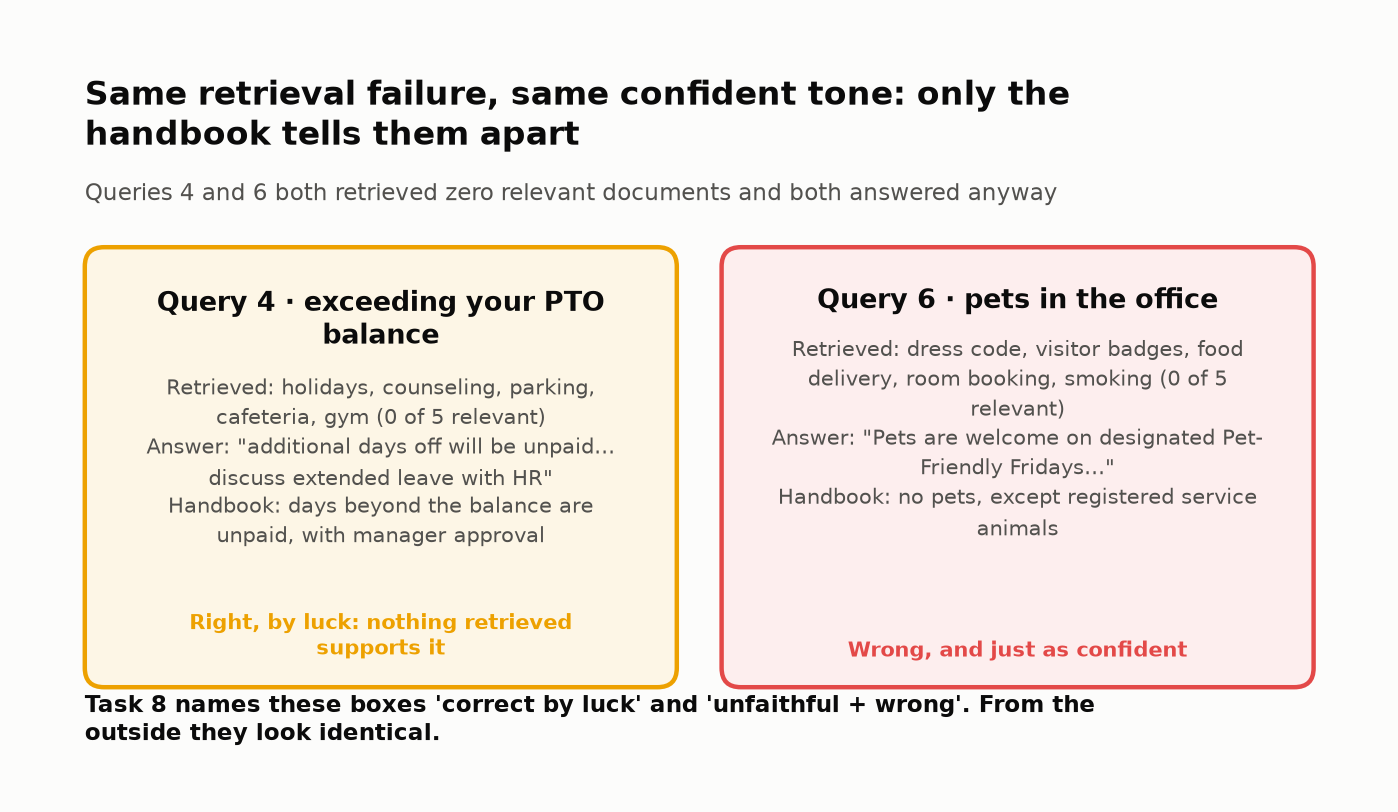
<sub>🖼️ *Same failure, same tone, opposite truth. Nothing in either answer tells you which one to trust.*</sub>

**What just happened:** both answers came from five off-topic docs, so neither is supported by anything retrieved. Query 4's matches the handbook because "extra days off are unpaid" is a common rule, most likely absorbed in training; Query 6's "Pet-Friendly Fridays" is invented. The text can't tell you which is which, so the rest of the lab measures the evidence, not the tone.

🗣️ **Say it to a colleague:** "An answer with no evidence behind it is a guess that sounds like policy, even on the days the guess is right."

➡️ **Bridge:** keep your answer to question 3 in mind. Task 4 scores the retrieval half on its own, so you can see which failures started before the LLM wrote a word.

---

## Task 4: 📏 Compute Retrieval Metrics (Recall@K, Precision@K, nDCG, MRR)

**Stakes:** headline the wrong retrieval metric and the team spends a quarter tuning rank order for a model that reads all five chunks anyway.

🧭 **Where you are:** Act II of IV, *Score each stage* (Tasks 4–7): retrieval first, then faithfulness, then a root cause for every query.

### Goal
Compute four retrieval metrics for every query and decide which one deserves the headline.

### 🎯 Why Evaluate Retrieval Separately?
If the retriever serves the wrong documents, no generator can repair the answer, and a bad answer looks the same whichever stage caused it. All four metrics read the relevance labels of the top K documents (here K = 5):

| Metric | Question it answers | Formula | 1.0 means |
|---|---|---|---|
| **Recall@K** | Did we **find** the relevant docs? | relevant in top K / all relevant | every relevant doc is in the top K |
| **Precision@K** | How much **noise** came with them? | relevant in top K / K | all K docs are relevant |
| **nDCG@K** (normalized discounted cumulative gain) | Are the relevant docs **ranked first**? | DCG / ideal DCG, with DCG = Σ rel / log₂(rank + 1) | the relevant docs fill the top ranks |
| **MRR** | How far down is the **first** relevant doc? | mean over queries of 1 / rank of the first relevant doc (0 if none) | the first doc is relevant, for every query |

The log discount gives a relevant doc full credit at rank 1, 63% at rank 2 and 50% at rank 3. Worked example for `[0, 1, 0, 1, 0]`: DCG = 1/log₂3 + 1/log₂5 = 0.63 + 0.43 = 1.06; the ideal order `[1, 1, 0, 0, 0]` scores 1 + 0.63 = 1.63; nDCG = 1.06 / 1.63 = **0.65**.

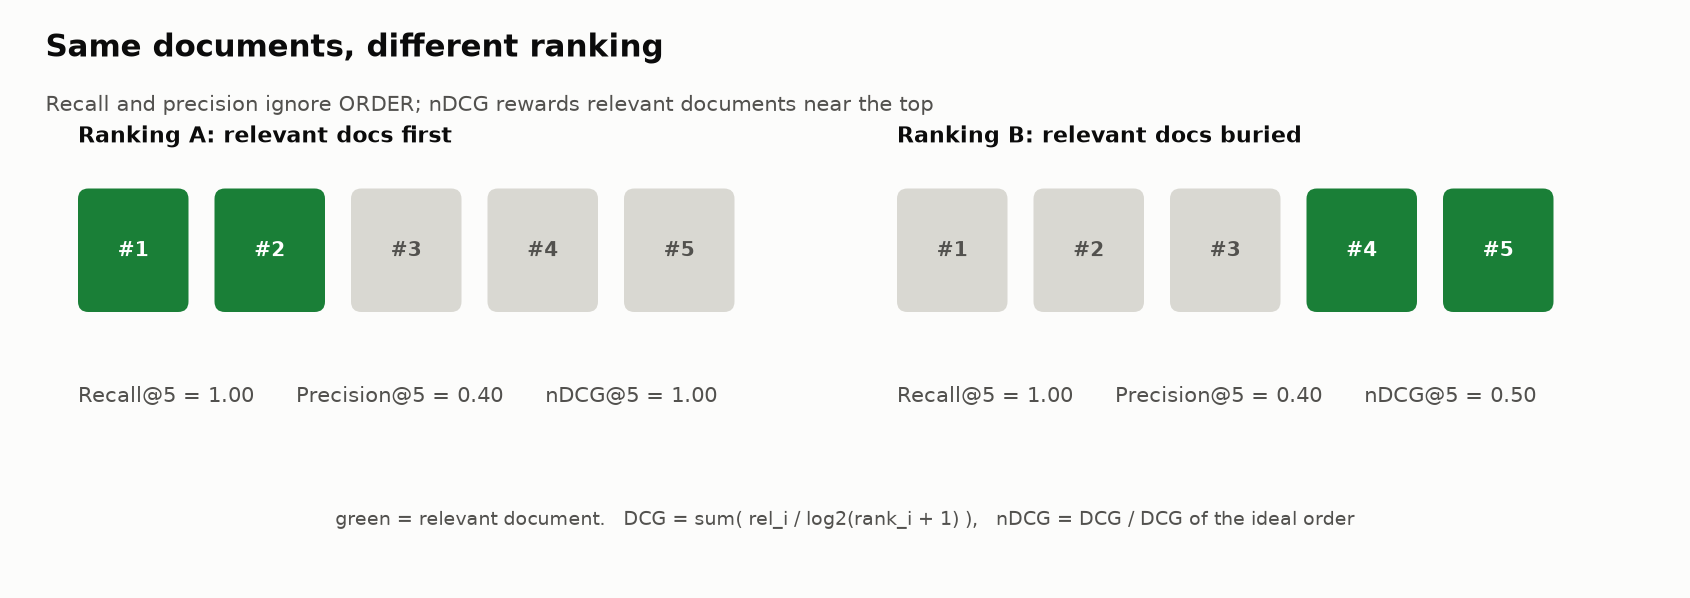

<sub>🖼️ *Same two relevant documents, different positions: only the rank-aware metrics (nDCG, MRR) notice*</sub>

> 📘 **Concept · Recall@K (here, a hit rate)**
>
> **What it is:** of the documents that *should* be retrieved, the fraction that appear in the top K. Only the 5 returned docs were labelled here, so "all relevant" means "relevant among those 5": Recall@5 is 1 if any came back and 0 if none did, and its mean over queries is the **hit rate**.
>
> **What it can't tell you:** whether the retrieved docs contain the answer (Task 9) or where they ranked. True recall needs labels across the whole **corpus** (every doc that could be retrieved), which Lab 04b has (`relevant_doc_ids`).
>
> **Anchor:** Query 4 retrieves holiday, counseling, parking, cafeteria and gym docs for a PTO question: Recall@5 = 0. Query 1 has one relevant doc in five and Query 8 has five in five; both score Recall@5 = 1.

> 🔮 **Predict:** mean Precision@5 will be well below 0.5. Which single number belongs on the dashboard? (A) Precision@5 · (B) nDCG@5 · (C) MRR · (D) Recall@5, the hit rate

### Steps
1. Define the four metric functions, then check them on `[0, 1, 0, 1, 0]`
2. Compute the metrics for all 12 queries
3. List the worst and best queries, then read the chart and the card

In [ ]:
# 📏 Four retrieval metrics. Each reads only the 0/1 relevance labels of the top K docs (K = 5 here).
def recall_at_k(relevance_labels, k=5):
    """Relevant docs in the top K ÷ all relevant docs (0 if there are none)."""
    total_relevant = sum(relevance_labels)
    return sum(relevance_labels[:k]) / total_relevant if total_relevant else 0.0

def precision_at_k(relevance_labels, k=5):
    """Relevant docs in the top K ÷ K."""
    return sum(relevance_labels[:k]) / k

def ndcg_at_k(relevance_labels, k=5):
    """DCG of this ranking ÷ DCG of the ideal ranking (all relevant docs first)."""
    # 👀 Look at: a relevant doc earns 1 / log2(rank + 1): full credit at rank 1, 0.63 at rank 2, 0.5 at rank 3
    dcg = sum(rel / np.log2(rank + 1) for rank, rel in enumerate(relevance_labels[:k], start=1))
    ideal = sorted(relevance_labels, reverse=True)[:k]
    idcg = sum(rel / np.log2(rank + 1) for rank, rel in enumerate(ideal, start=1))
    return dcg / idcg if idcg else 0.0

def mrr_at_k(relevance_labels, k=5):
    """1 ÷ rank of the first relevant doc in the top K (0 if none). Averaged over queries: MRR."""
    return next((1.0 / rank for rank, rel in enumerate(relevance_labels[:k], start=1) if rel), 0.0)

In [ ]:
# ✅ Check the math on a case you can do by hand: relevant docs at ranks 2 and 4
test_labels = [0, 1, 0, 1, 0]
print("Verification with test labels [0, 1, 0, 1, 0]:")
print(f"  Recall@5:    {recall_at_k(test_labels, 5):.3f}  (2 relevant retrieved / 2 total = 1.0)")
print(f"  Precision@5: {precision_at_k(test_labels, 5):.3f}  (2 relevant / 5 retrieved = 0.4)")
print(f"  nDCG@5:      {ndcg_at_k(test_labels, 5):.3f}  (< 1.0 because relevant docs are at rank 2 and 4, not 1 and 2)")
print(f"  MRR@5:       {mrr_at_k(test_labels, 5):.3f}  (first relevant doc is at rank 2 → 1/2)")
print("\n✅ Metric functions defined.")

In [ ]:
# ── Compute retrieval metrics for ALL 12 queries ──
results = []
for item in rag_dataset:
    labels = item["relevance_labels"]
    results.append({
        "id": item["id"],
        "query": item["query"][:50],
        "n_relevant": sum(labels),                 # how many relevant docs were in the results?
        "recall@5": recall_at_k(labels, 5),        # did we find the relevant ones? (a hit rate here)
        "precision@5": precision_at_k(labels, 5),  # how clean were the results?
        "ndcg@5": ndcg_at_k(labels, 5),            # were relevant docs ranked near the top?
        "mrr@5": mrr_at_k(labels, 5),              # how far down was the first relevant doc?
    })

metrics_df = pd.DataFrame(results)
print("📊 Retrieval Metrics per Query\n")
print(metrics_df.to_string(index=False, float_format="%.3f"))

means = metrics_df[["recall@5", "precision@5", "ndcg@5", "mrr@5"]].mean()
tiles([
    ("Mean Recall@5 (hit rate)", f"{means['recall@5']:.2f}", "evidence found at all", "warning"),
    ("Mean Precision@5", f"{means['precision@5']:.2f}", "share of the 5 docs that are relevant", None),
    ("Mean nDCG@5", f"{means['ndcg@5']:.2f}", "rank quality", None),
    ("MRR", f"{means['mrr@5']:.2f}", "1 / rank of first relevant doc", None),
])

In [ ]:
# ── Drill down: which queries have the WORST and BEST retrieval? ──
# Triage the way you would in production: find the failures first, then ask why.

print("🔴 Queries with Retrieval Failures (Recall@5 = 0):\n")
for item in rag_dataset:
    if sum(item["relevance_labels"]) == 0:
        print(f"  Query {item['id']}: \"{item['query']}\"")
        print(f"    → Zero relevant docs retrieved. The system retrieved only unrelated content.")
        print(f"    → Generated answer: \"{item['generated_answer'][:80]}...\"")
        print(f"    → ⚠️ Notice: the answer STILL sounds confident despite having no evidence!")
        print()

print("🟢 Queries with Perfect Retrieval (Recall@5 = 1.0, Precision@5 ≥ 0.6):\n")
for item in rag_dataset:
    labels = item["relevance_labels"]
    if recall_at_k(labels) == 1.0 and precision_at_k(labels) >= 0.6:
        print(f"  Query {item['id']}: \"{item['query']}\"")
        print(f"    → {sum(labels)}/5 retrieved docs relevant. Strong retrieval.")
        print()

In [ ]:
# ── 🎨 Visualize retrieval quality per query ──
ax = metrics_df.set_index("id")[["recall@5", "precision@5", "ndcg@5", "mrr@5"]].plot(
    kind="bar", figsize=(11, 4), width=0.8)
ax.set_xlabel("query id"); ax.set_ylabel("score"); ax.set_ylim(0, 1.32)
ax.set_title("Two queries retrieved nothing; the rest differ mostly in noise and rank")
ax.legend(ncol=4, loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

hit = metrics_df["recall@5"] > 0
buried = metrics_df.loc[(metrics_df["mrr@5"] > 0) & (metrics_df["mrr@5"] < 1), "id"].tolist()
n_noise = 5 * len(metrics_df) - int(metrics_df["n_relevant"].sum())
insight(
    f"Hit rate is {hit.mean():.0%} ({hit.sum()}/{len(hit)}), yet mean Precision@5 is only {means['precision@5']:.2f}. "
    "Which number matters?",
    f"Precision@5 is dragged down by the {n_noise} off-topic chunks that rode along, and MRR by queries {buried}, "
    "where the evidence sat below rank 1. But an LLM reads **all** K chunks; it doesn't stop at the first result "
    "like a person scanning search results. The queries that are doomed at the retrieval stage are the "
    f"{(~hit).sum()} with a hit rate of zero: {metrics_df.loc[~hit, 'id'].tolist()}.\n"
    "**Rule of thumb:** headline recall@K at the K you actually pass to the model (Anthropic's Contextual Retrieval "
    "study, 2024, used K = 20). Use precision, nDCG and MRR as tuning diagnostics, not as the quality score.")

### Checkpoint ✅
You should see a 12-row metrics table, four tiles, a chart, and a 💡 card:
- **Queries 4 and 6** score 0 on every metric: complete retrieval failures
- **Query 8** (company credit cards) is perfect: all 5 docs relevant
- **Queries 2 and 3** found the evidence, but at rank 3 (MRR 0.333)

### Expected Output (partial)
```
--- tiles ---
Mean Recall@5 (hit rate) 0.83 · Mean Precision@5 0.40 · Mean nDCG@5 0.73 · MRR 0.72

🔴 Queries with Retrieval Failures (Recall@5 = 0):

  Query 4: "What happens if I exceed my PTO balance?"
    → Zero relevant docs retrieved. The system retrieved only unrelated content.
  ...
```
Card: *"Hit rate is 83% (10/12), yet mean Precision@5 is only 0.40. Which number matters?"*

**What just happened:** all four metrics read the same 0/1 labels and weigh different things. Precision divides by K, so one relevant doc in five scores 0.20 even when it holds the whole answer (Queries 1, 2, 3 and 7); MRR and nDCG discount by rank, so Queries 2 and 3 lose credit for evidence at rank 3 that the LLM read anyway. Only the hit rate isolates the two queries that never had a chance.

🗣️ **Say it to a colleague:** "Headline recall at the K you actually send the model. Rank metrics tune the retriever; they don't grade the answer."

⏱️ **60-second experiment:** in a new cell, run `[it["id"] for it in rag_dataset if recall_at_k(it["relevance_labels"], k=2) == 0]`. Which queries lose their evidence if you send the model 2 chunks instead of 5? That's the cost an MRR of 0.33 was warning you about.

> ⚠️ **Common mistake:** stopping at retrieval metrics. Query 10 has strong retrieval (4 of 5 docs relevant), and its answer still contains a fabricated number.

➡️ **Bridge:** retrieval tells you whether the evidence *arrived*. Next: did the answer *stick to* it?

---

## Task 5: 🧠 Your Turn — Design Grounding Evaluation Criteria

**Stakes:** in a benefits answer one changed number (12 weeks → 16) is the whole failure, and it's the number an employee plans their leave around.

### Goal
Write a 3–5 criterion rubric that decides whether an answer is **grounded**: every claim in it can be traced to a retrieved document. Then run one criterion as code.

> 📘 **Concept · Faithfulness (also grounding, groundedness)**
>
> **What it is:** every claim in the answer is supported by the retrieved context. This task says "grounding"; from Task 6 on the lab says **faithfulness**; they mean the same thing.
>
> **What it can't tell you:** whether the answer is *true*. It checks the answer against the retrieved docs, not against reality: an answer copied faithfully from a stale doc is wrong, and a correct answer drawn from the model's training data is unfaithful.
>
> **Anchor:** Query 10's docs say 12 weeks and its answer says 16: unfaithful. Task 8 finds an answer that is perfectly faithful and still wrong.

### 📐 What Is Grounding?

```
  Grounding = Can every claim in the answer be traced to a source document?

  Retrieved Doc:  "Employees get 12 weeks of parental leave..."
                               │
                    ┌──────────▼──────────┐
                    │     Generated       │
                    │      Answer         │
                    └──────────┬──────────┘
                               │
              ┌────────────────┼────────────────┐
              ▼                ▼                 ▼
        ✅ Supported     ⚠️ Paraphrased    ❌ Fabricated
       "12 weeks of     "about 3 months    "16 weeks of
        paid leave"      of leave"          paid leave"
```

### Context
**Query 10** (parental leave):

> **Retrieved doc 1:** "Full-time employees are eligible for **12 weeks** of paid parental leave..."
>
> **Generated answer:** "The company offers **16 weeks** of fully paid parental leave..."

One number changed in an otherwise supported answer: a **distortion**.

**Query 6** (pets in office):

> **Retrieved docs:** None relevant (dress code, visitor policy, food delivery, etc.)
>
> **Generated answer:** "Pets are welcome in the office on designated Pet-Friendly Fridays..."

No retrieved doc supports any claim: a **fabrication**.

### Your Task

In the code cell below, give each criterion a **name**, a **description**, a **scoring method** (binary, scale, rubric) and a **failure example**. Your rubric must handle a changed fact (12 → 16 weeks), a *partially* grounded answer, helpful extras no doc supports, and the line between *paraphrase* (acceptable) and *fabrication* (not).

**Hint:** check (a) that each claim maps to a retrieved doc, (b) that numbers, dates and names match their source, (c) that the answer adds nothing no doc contains. There's no single correct rubric.

> 🔮 **Predict:** the cell after your rubric runs ONE criterion as code: "every number in the answer must appear in the retrieved docs." How many of the 12 answers will it flag? (A) 0 · (B) 1 · (C) 3, every answer with a problem

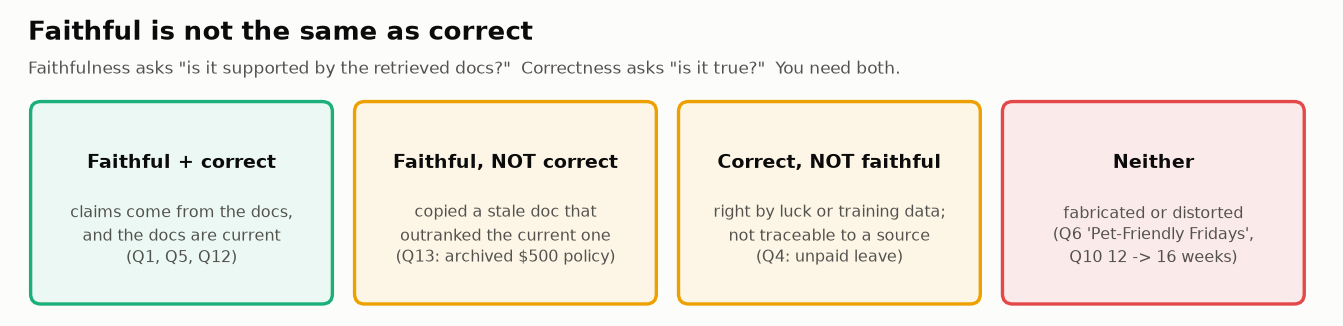

<sub>🖼️ *Grounding/faithfulness and correctness are different axes*</sub>

In [ ]:
# 🧠 YOUR TURN: replace every "..." with your own criteria (aim for 3-5; add or remove entries).
# Cover a changed fact (12 → 16 weeks), a partly grounded answer, helpful extras no doc supports,
# and the line between paraphrase (fine) and fabrication (not).
my_grounding_criteria = [
    {"name": "...",              # e.g. "claim_attribution": does each claim trace to a doc?
     "description": "...", "scoring": "...", "failure_example": "..."},
    {"name": "...",              # e.g. "numerical_accuracy": do numbers match the source?
     "description": "...", "scoring": "...", "failure_example": "..."},
    {"name": "...",              # e.g. "no_unsupported_claims": nothing beyond the docs?
     "description": "...", "scoring": "...", "failure_example": "..."},
]

print("📋 My Grounding Evaluation Criteria:\n")
for i, criterion in enumerate(my_grounding_criteria, 1):
    print(f"  {i}. {criterion['name']}")
    print(f"     Description:    {criterion['description']}")
    print(f"     Scoring:        {criterion['scoring']}")
    print(f"     Failure looks like: {criterion['failure_example']}")
    print()

In [ ]:
# 🔢 One grounding criterion you can automate in 10 lines:
# every NUMBER in the answer (amounts, days, percentages) must appear somewhere in the retrieved docs.
NUM_RE = re.compile(r"\d[\d,]*(?:\.\d+)?")

def numbers_in(text):
    """All numbers in a string, normalized ("$3,000" → "3000")."""
    return {n.replace(",", "") for n in NUM_RE.findall(text)}

def unsupported_numbers(item):
    context = " ".join(item["retrieved_docs"])
    # 👀 Look at: a set difference; any number in the answer that no retrieved doc contains is a claim with no source
    return sorted(numbers_in(item["generated_answer"]) - numbers_in(context))

number_flags = {it["id"]: unsupported_numbers(it) for it in rag_dataset}
flagged = {qid: nums for qid, nums in number_flags.items() if nums}
with_numbers = [it["id"] for it in rag_dataset if numbers_in(it["generated_answer"])]
no_number_fabrications = [it["id"] for it in rag_dataset
                          if sum(it["relevance_labels"]) == 0 and not numbers_in(it["generated_answer"])]

print(f"Answers containing numbers: {len(with_numbers)}/{len(rag_dataset)}")
for qid, nums in flagged.items():
    print(f"  🚩 Query {qid}: {nums} appear in the answer but nowhere in the retrieved docs")

insight(
    f"A 10-line number check flags {len(flagged)} of {len(rag_dataset)} answers: "
    + ", ".join(f"Query {q} ({', '.join(n)})" for q, n in flagged.items()),
    f"That's the 12 → 16 weeks distortion, caught deterministically, with no model. It checked {len(with_numbers)} "
    f"answers that contain numbers and raised no false alarms. It says nothing about queries {no_number_fabrications}, "
    "whose fabrications contain no numbers: a deterministic check is precise, not complete.\n"
    "**Rule of thumb:** in benefits, payroll and tax answers the numbers are the claims that hurt. Verify numbers, "
    "dates and amounts with exact checks first, then spend model-based checks on what's left.")

### Checkpoint ✅
Your rubric printout should show at least 3 criteria, each with a name, description, scoring approach and failure example, covering different kinds of grounding failure (not just "is it correct?").

The number check should print:
```
Answers containing numbers: 10/12
  🚩 Query 10: ['16'] appear in the answer but nowhere in the retrieved docs
```
Card: *"A 10-line number check flags 1 of 12 answers: Query 10 (16)."*

**What just happened:** `unsupported_numbers` subtracts the numbers found anywhere in the five retrieved docs from the numbers in the answer. "16" appears in none of Query 10's docs, so it's flagged; Queries 4 and 6 have no evidence behind them but no digits either, so there was nothing to subtract.

🗣️ **Say it to a colleague:** "Check the numbers with a regex before you pay a model to read the sentence. In a benefits answer, the number *is* the claim."

➡️ **Bridge:** exact checks are precise but narrow. Next you'll build two general faithfulness scorers and see how each one fails.

---

## Task 6: 🧪 Implement Faithfulness Scoring

**Stakes:** a faithfulness scorer wired to an alert pages someone every time it's wrong; if you don't know its miss and false-alarm rates, you don't know which pages to ignore.

### Goal
Build two automated faithfulness scorers, run both on all 12 answers, and measure where each one is wrong.

### Background
- **Word overlap** (rule-based): the share of the answer's content words that also appear in the relevant docs. *Content words* are what's left after dropping **stop words**, a fixed list of very common words (*the*, *of*, *and*, …).
- **NLI**: a model that reads two texts together, defined below.

> 📘 **Concept · NLI entailment**
>
> **What it is:** a natural language inference (NLI) model reads a **premise** (here, the relevant docs) and a **hypothesis** (the answer) and returns three probabilities: **entailment** (the premise supports it), **contradiction**, and **neutral** (neither). Faithfulness = P(entailment). This lab's model is a **cross-encoder**: it reads both texts in one pass, which is more accurate than comparing two separate **embeddings** (one vector per text).
>
> **What it can't tell you:** which claim failed, or whether the premise is current. Asked about a long, multi-claim answer in one pass, a small model often says "neutral" even when every claim is supported.
>
> **Anchor:** with Query 8's doc "Personal charges on company credit cards are strictly prohibited" as the premise, "Personal use is prohibited" is entailment, "You may put personal charges on the card" is contradiction, and "Cards have a $5,000 limit" is neutral.

### 🎯 Why Two Methods?

| | Word overlap | NLI |
|---|---|---|
| Cost | instant, no model | model inference per answer |
| Transparency | you can list the matching words | a probability, no explanation |
| Changed facts (12 → 16 weeks) | ❌ shared words hide them | ✅ catches contradictions |
| Paraphrase | ❌ penalized (different words) | ✅ usually handled |

Every scorer has a **miss rate** (unfaithful answers it passes) and a **false-alarm rate** (faithful answers it flags), and you learn both only by running it on answers you've already judged. Module 05 states them as success rates: **TPR** (true-positive rate) = 1 − miss rate, **TNR** (true-negative rate) = 1 − false-alarm rate.

> 🔮 **Predict:** Query 10 swaps 12 weeks for 16 weeks and keeps the rest of the doc's wording. Its word-overlap score will be (A) below 0.3 · (B) 0.3–0.6 · (C) above 0.6. And how many of the 9 good answers will NLI wrongly flag: 0, 1, or 3 or more?

### Steps
1. Build the word-overlap scorer (its tokenizer and stop list sit in a collapsed 🧰 cell) and test it on Queries 1 and 6
2. Load the NLI cross-encoder and test it on the same two queries
3. Score all 12 queries with both methods, then count each scorer's misses and false alarms

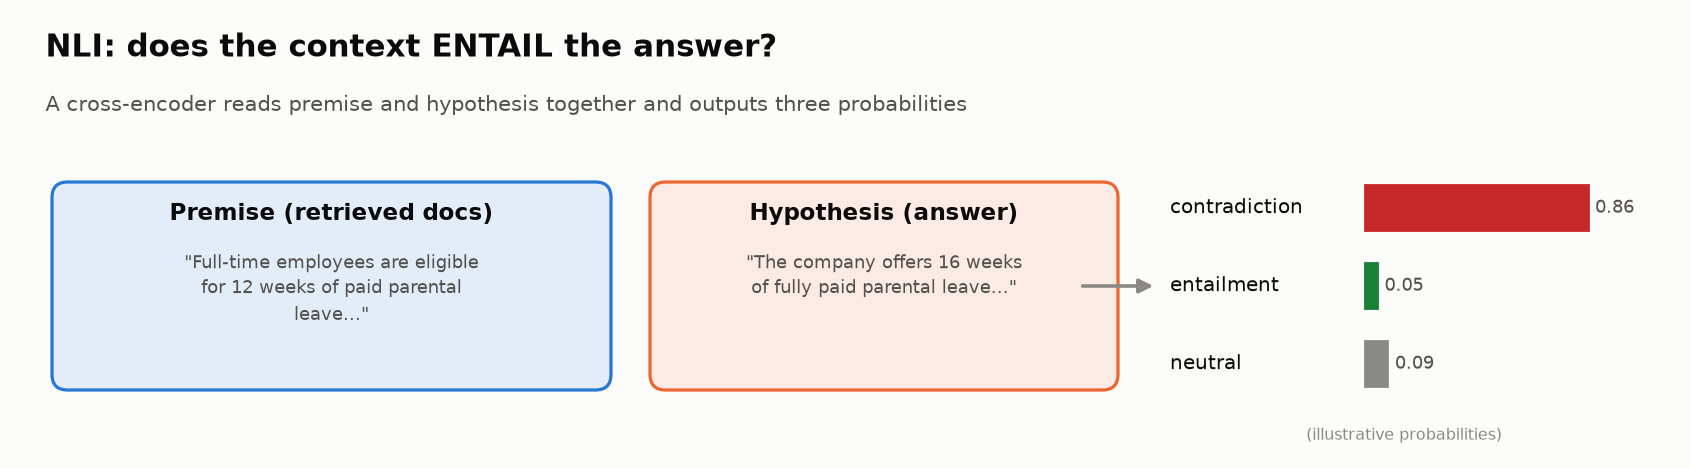

<sub>🖼️ *How an NLI cross-encoder scores one (premise, hypothesis) pair*</sub>

In [ ]:
# @title 🧰 tokenize() and STOP_WORDS, the stop-word list the word-overlap scorer uses (hidden · 16 lines · expand if curious)
def tokenize(text):
    """Lowercased set of words (letters, digits and underscores)."""
    return set(re.findall(r'\b\w+\b', text.lower()))

# Very common words that say little about a text's topic. Search engines drop them; so does this scorer.
STOP_WORDS = {'the', 'a', 'an', 'is', 'are', 'was', 'were', 'be', 'been', 'being',
              'have', 'has', 'had', 'do', 'does', 'did', 'will', 'would', 'could',
              'should', 'may', 'might', 'shall', 'can', 'to', 'of', 'in', 'for',
              'on', 'with', 'at', 'by', 'from', 'as', 'into', 'through', 'during',
              'and', 'but', 'or', 'nor', 'not', 'so', 'yet', 'both', 'either',
              'neither', 'each', 'every', 'all', 'any', 'few', 'more', 'most',
              'other', 'some', 'such', 'no', 'only', 'own', 'same', 'than',
              'too', 'very', 'just', 'because', 'if', 'when', 'where', 'how',
              'what', 'which', 'who', 'whom', 'this', 'that', 'these', 'those',
              'i', 'me', 'my', 'we', 'our', 'you', 'your', 'he', 'him', 'his',
              'she', 'her', 'it', 'its', 'they', 'them', 'their'}

In [ ]:
# Method 1: word overlap. What share of the answer's content words also appear in the RELEVANT docs?
def rule_based_faithfulness(answer, retrieved_docs, relevance_labels):
    """0-1: share of the answer's content words (stop words removed) found in the relevant docs."""
    relevant_docs = [doc for doc, rel in zip(retrieved_docs, relevance_labels) if rel == 1]
    answer_words = tokenize(answer) - STOP_WORDS
    if not relevant_docs:                       # no evidence: a substantive answer must be invented
        return 0.0 if len(answer_words) > 3 else 0.5
    if not answer_words:
        return 1.0
    context_words = set().union(*(tokenize(doc) - STOP_WORDS for doc in relevant_docs))
    # 👀 Look at: a word counts as supported if it appears ANYWHERE in the docs, whatever the doc says around it
    return len(answer_words & context_words) / len(answer_words)

for idx, name, expect in [(0, "Query 1 (PTO days)", "high: the answer mirrors the doc"),
                          (5, "Query 6 (pet policy)", "low: no relevant docs, so nothing supports it")]:
    it = rag_dataset[idx]
    score = rule_based_faithfulness(it["generated_answer"], it["retrieved_docs"], it["relevance_labels"])
    print(f"Rule-based faithfulness for {name}: {score:.3f}  (expected {expect})")
print("\n✅ Rule-based faithfulness scorer ready.")

In [ ]:
# Method 2: NLI. Do the relevant docs ENTAIL the answer? (premise = relevant docs, hypothesis = answer)
from sentence_transformers import CrossEncoder
nli_model = CrossEncoder("cross-encoder/nli-MiniLM2-L6-H768", max_length=512)   # ~90 MB, downloaded once
NLI_LABELS = ["contradiction", "entailment", "neutral"]                          # the model's output order
print("✅ NLI cross-encoder loaded: nli-MiniLM2-L6-H768")

def nli_faithfulness(answer, retrieved_docs, relevance_labels):
    """P(the relevant docs entail the answer), plus P(contradiction) and the winning label."""
    relevant_docs = [doc for doc, rel in zip(retrieved_docs, relevance_labels) if rel == 1]
    if not relevant_docs:                                  # nothing to check against
        return {"entailment_score": 0.0, "label": "no_context", "scores": [0, 0, 0]}
    # 👀 Look at: ONE pair, all relevant docs vs. the whole answer; softmax turns 3 logits into probabilities
    scores = nli_model.predict([(" ".join(relevant_docs), answer)], apply_softmax=True)[0]
    return {"entailment_score": float(scores[1]), "contradiction_score": float(scores[0]),
            "label": NLI_LABELS[int(np.argmax(scores))], "scores": [float(s) for s in scores]}

for idx, name in [(0, "Query 1 (PTO days)"), (5, "Query 6 (pet policy)")]:
    it = rag_dataset[idx]
    r = nli_faithfulness(it["generated_answer"], it["retrieved_docs"], it["relevance_labels"])
    print(f"\nNLI faithfulness for {name}:\n  Entailment score: {r['entailment_score']:.3f}\n  Predicted label:  {r['label']}")

In [ ]:
# Head-to-head: both scorers on all 12 answers. Where they disagree, at least one of them is wrong.
comparison = []
for item in rag_dataset:
    args = (item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
    nli_result = nli_faithfulness(*args)
    comparison.append({
        "id": item["id"], "query": item["query"][:45] + "...", "n_relevant": sum(item["relevance_labels"]),
        "rule_based": rule_based_faithfulness(*args),                       # word overlap (0-1)
        "nli_entailment": nli_result["entailment_score"],                   # P(entailment) (0-1)
        "nli_contradiction": nli_result.get("contradiction_score", 0.0),    # P(contradiction)
        "nli_label": nli_result["label"],
    })
comp_df = pd.DataFrame(comparison)
print("📊 Faithfulness Comparison: Rule-Based vs NLI\n")
print(comp_df.to_string(index=False, float_format="%.3f"))

has_context = comp_df[comp_df["n_relevant"] > 0]   # no-context queries would drag both means toward 0
print(f"\n--- Method Averages (excluding no-context queries) ---")
print(f"  Rule-based mean:     {has_context['rule_based'].mean():.3f}")
print(f"  NLI entailment mean: {has_context['nli_entailment'].mean():.3f}")

In [ ]:
# 🧪 Evaluate the evaluators: misses and false alarms on answers someone already judged by hand
# 👀 Look at: without this hand-labelled set there is nothing to measure a scorer against
KNOWN_UNFAITHFUL = {4, 6, 10}   # we read the docs: these answers contain unsupported claims
c = comp_df.set_index("id")
faithful_ids = [i for i in c.index if i not in KNOWN_UNFAITHFUL]
nli_false_alarms = [i for i in faithful_ids if c.loc[i, "nli_entailment"] < 0.5]
rb_misses = [i for i in KNOWN_UNFAITHFUL if c.loc[i, "rule_based"] >= 0.5]
tiles([
    ("Query 10, word overlap", f"{c.loc[10, 'rule_based']:.2f}", "looks faithful", "critical"),
    ("Query 10, NLI entailment", f"{c.loc[10, 'nli_entailment']:.2f}", "caught the distortion", "good"),
    ("NLI false alarms", f"{len(nli_false_alarms)}/{len(faithful_ids)}", f"good answers scored < 0.5: {nli_false_alarms}", "warning"),
    ("Word-overlap misses", f"{len(rb_misses)}/{len(KNOWN_UNFAITHFUL)}", f"bad answers scored ≥ 0.5: {sorted(rb_misses)}", "warning"),
])
insight(
    f"NLI caught Query 10 (entailment {c.loc[10, 'nli_entailment']:.2f}) that word overlap waved through at "
    f"{c.loc[10, 'rule_based']:.2f}, and then flagged {len(nli_false_alarms)} of {len(faithful_ids)} good answers",
    f"Queries {nli_false_alarms} are faithful, but a small NLI model reading a long, multi-claim answer in one pass "
    "can't confirm them. Each scorer has a measurable **miss rate** and **false-alarm rate**, and you only learn "
    "them by running the scorer on answers you've already judged.\n"
    "**Rule of thumb:** before wiring a faithfulness scorer to an alert, run it on 20–50 hand-labelled answers and "
    "report misses *and* false alarms (TPR/TNR), not its average score.")

**What just happened:** the two scorers fail in opposite directions. Word overlap counts shared words, so Query 10's answer, which keeps the doc's vocabulary around a changed number, lands above 0.5. NLI reads the pair as sentences and catches the change, but `nli_faithfulness` asks it one big question per answer: do all the relevant docs, joined, entail every claim at once? For Query 8 that is five claims drawn from four docs, and the small model's answer is "neutral".

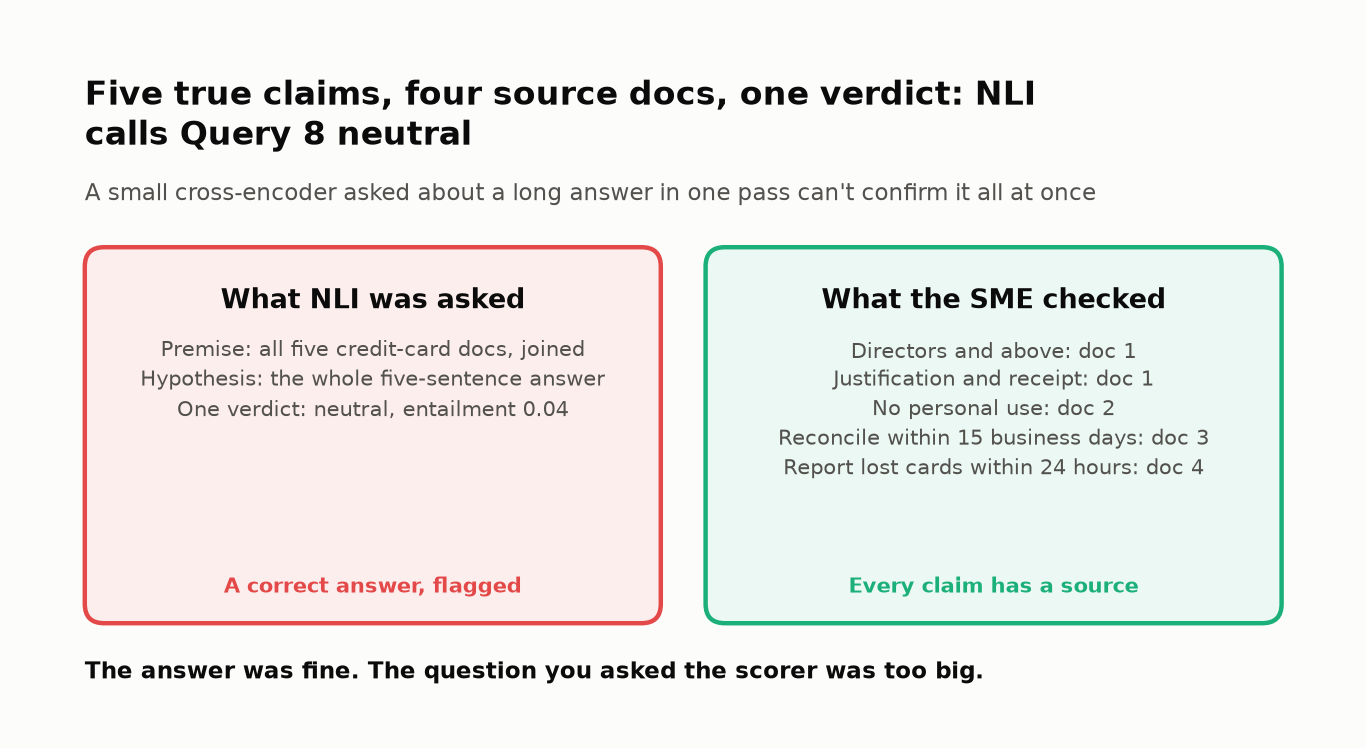
<sub>🖼️ *The false alarm comes from the size of the question, not from the answer. Challenge 5 asks it claim by claim.*</sub>

🗣️ **Say it to a colleague:** "Every faithfulness scorer has a miss rate and a false-alarm rate. Until you've measured both on labelled answers, you have a number, not a scorer."

### 🧨 One more answer: a flat denial

Here is a sentence built only from Query 10's own doc words that **denies** the policy: *"Employees are not eligible for 12 weeks of paid parental leave."*

> 🔮 **Predict:** its word-overlap score will be (A) below 0.3 · (B) 0.3–0.7 · (C) above 0.9. Will the number check flag it? What will NLI say?

In [ ]:
# 🧨 A flat denial of the parental-leave policy, built only from the doc's own words
denial = "Employees are not eligible for 12 weeks of paid parental leave."
q10 = rag_dataset[9]
den_overlap = rule_based_faithfulness(denial, q10["retrieved_docs"], q10["relevance_labels"])
den_nli = nli_faithfulness(denial, q10["retrieved_docs"], q10["relevance_labels"])
den_numbers = unsupported_numbers({**q10, "generated_answer": denial})
print(f"Words the overlap scorer threw away: {sorted(tokenize(denial) & STOP_WORDS)}")

tiles([
    ("Word overlap", f"{den_overlap:.2f}", "a perfect score", "critical"),
    ("Number check", "pass" if not den_numbers else "flag", "12 is in the docs", "critical" if not den_numbers else "good"),
    ("NLI label", den_nli["label"], f"P(contradiction) = {den_nli['contradiction_score']:.2f}", "good"),
])
insight(
    f"A sentence that denies the policy scores {den_overlap:.2f} on word overlap",
    "`not` is on the stop-word list, so the scorer deletes the one word that reverses the meaning, and every word "
    f"left is in the doc. NLI reads the sentence whole and calls it a **contradiction** ({den_nli['contradiction_score']:.2f}). "
    "Stop-word lists were built for search, where *not* says little about the topic; in an evaluator it *is* the claim.\n"
    "**Rule of thumb:** never gate on a bag-of-words score (one that only counts words). If you keep one as a cheap "
    "pre-filter, take negations (not, no, nor, neither) off its stop list.",
    kind="surprise")

### Checkpoint ✅
You should see a comparison table, four tiles and a 💡 card; then, for the denial, three tiles and a 🤯 card. All scores are **probabilities between 0 and 1** (the NLI cell uses `apply_softmax=True`).

| Query | Rule-based | NLI entailment | What it shows |
|---|---|---|---|
| 1, 3, 5, 7, 9, 11 | 0.54–0.93 | **≈ 0.93–0.99** | Faithful answers: both methods agree |
| 4, 6 | 0.00 | 0.00 (`no_context`) | No relevant docs, so nothing can support the answer |
| **10** (12 → 16 weeks) | 0.53 (looks OK!) | **0.02**, contradiction 0.25 | Word overlap is fooled by shared vocabulary; NLI is not |
| **8** (credit cards) | 0.82 | **0.04** → `neutral` | ⚠️ A *correct, faithful* answer that the small NLI model can't confirm |
| **2** (client dinners) | 0.64 | 0.31, `contradiction` 0.59 | ⚠️ A false alarm: "client dinner" vs "client entertainment" |
| **12** (stock options) | ≈ 0.7 | 0.49 | ⚠️ Borderline: just under a 0.5 threshold |

Tiles: Query 10 word overlap **0.53** · Query 10 NLI **0.02** · NLI false alarms **3/9** ([2, 8, 12]) · Word-overlap misses **1/3** ([10]).

The denial:
```
Words the overlap scorer threw away: ['are', 'for', 'not', 'of']
```
Tiles: word overlap **1.00** · number check **pass** · NLI label **contradiction** (P = 0.99). Card: *"A sentence that denies the policy scores 1.00 on word overlap."*

### 🧪 Experiment: Think About This
1. Why can't word overlap see that 12 became 16? (Hint: which words changed?)
2. How might **claim-level** NLI (scoring each sentence separately, Challenge 5) or a larger NLI model change Query 8's result?

**What just happened:** `not` is on the stop list, so the scorer deleted it before counting, and the seven words left are all in the doc. The number check passes because 12 *is* in the doc. NLI reads the sentence as a sentence, and a negated premise is the most basic contradiction it was trained on.

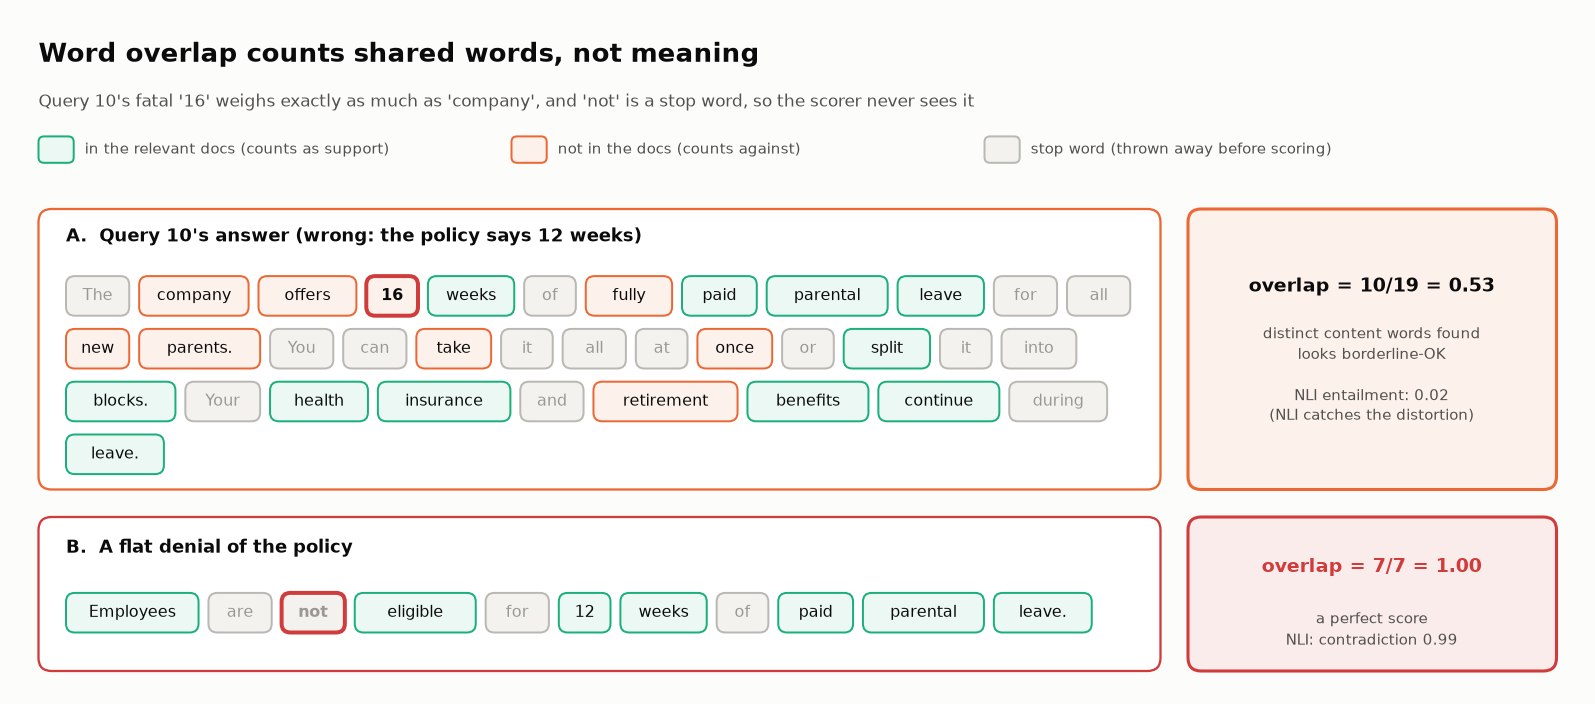

<sub>🖼️ *Word overlap scores each distinct word as found or not found. It can't weigh the word that matters, and it never sees "not".*</sub>

⏱️ **60-second experiment:** run `STOP_WORDS.discard("not")`, rerun the denial cell, then `STOP_WORDS.add("not")`. The score drops only to 0.88, because 7 of the 8 words still match: fixing the stop list doesn't fix a bag of words.

➡️ **Bridge:** you now have retrieval and faithfulness scores for every query. Next, combine them into one trace per query and assign each a root cause.

---

## Task 7: 🔬 Analyze Traced RAG Examples

**Stakes:** a root cause sends an engineer to a file; a wrong one sends them to the wrong file with a ticket that says it's fixed.

### Goal
Combine Task 4's retrieval metrics and Task 6's faithfulness scores into one **trace** per query (a record of each pipeline step: what was retrieved, what was generated, and its scores), and decide whether each failure started in **retrieval** or **generation**.

### 🎯 Why Tracing Matters

```
  Without tracing:              With tracing:
  ────────────────              ────────────────
  "The answer is wrong"    →    "Retrieval failed → no relevant docs
   🤷 Fix what?                  → LLM hallucinated an answer
                                  → Fix: improve retriever first"
```

- Retrieval returned irrelevant documents → fix the retriever (embeddings, chunking, index)
- Generation ignored or distorted good documents → fix the prompt, model or guardrails
- Both → fix retrieval first; it's upstream

> 💡 Tracing tools (Langfuse, LangSmith, Phoenix) record traces automatically, one **span** per step; OpenTelemetry (OTel, the open standard for recording traces) has GenAI conventions that (still *Development* status) and name those spans `retrieval` and `chat`. Here you build a simplified version by hand.

> 🔮 **Predict:** 10 of the 12 offline answers are correct. How many will the classifier mark **NO FAILURE**? (A) 9–10 · (B) 6–8 · (C) 5 or fewer

### Steps
Run the three cells below: the classifier's three rules build one trace per query (the trace packing sits in a collapsed 🧰 cell above them), then the trace table, then the root-cause summary.

In [ ]:
# @title 🧰 analyze_trace(): averages the two faithfulness scores, measures overlap with the ground truth, packs one trace dict (hidden · 27 lines · expand if curious)
def analyze_trace(item, rb_score, nli_score):
    """One trace per query: retrieval status, generation status, root cause, and the scores behind them."""
    n_relevant = sum(item["relevance_labels"])
    avg_faithfulness = (rb_score + nli_score) / 2             # both faithfulness signals, equally weighted
    gt_words = tokenize(item["ground_truth"]) - STOP_WORDS     # word-overlap proxy for correctness
    ans_words = tokenize(item["generated_answer"]) - STOP_WORDS
    gt_overlap = len(gt_words & ans_words) / len(gt_words) if gt_words else 1.0

    retrieval_status = classify_retrieval(n_relevant)
    generation_status = classify_generation(n_relevant, avg_faithfulness, gt_overlap, len(ans_words))
    return {
        "id": item["id"],
        "query": item["query"],
        "retrieval_status": retrieval_status,
        "retrieval_diagnosis": {"❌ FAILURE": "No relevant documents retrieved",
                                "⚠️ WEAK": f"Only {n_relevant}/5 relevant doc(s) — limited context",
                                "✅ GOOD": f"{n_relevant}/5 relevant docs retrieved"}[retrieval_status],
        "generation_status": generation_status,
        "generation_diagnosis": {"✅ GOOD": "Answer is faithful to context and matches ground truth",
                                 "❌ HALLUCINATION": "Generated substantive answer without relevant context",
                                 "❌ UNFAITHFUL": "Answer contains claims not supported by retrieved docs",
                                 "⚠️ PARTIAL": "Answer partially supported — some claims may be unsupported"}[generation_status],
        "root_cause": root_cause(retrieval_status, generation_status),
        "faithfulness_rb": rb_score,
        "faithfulness_nli": nli_score,
        "gt_overlap": gt_overlap,
    }

In [ ]:
# 🔬 The root-cause classifier is three small rules. Each threshold is an assumption about what "failure" means.
def classify_retrieval(n_relevant):
    if n_relevant == 0:
        return "❌ FAILURE"
    # 👀 Look at: one relevant doc out of five is filed as WEAK, even when that one doc holds the whole answer
    return "⚠️ WEAK" if n_relevant <= 1 else "✅ GOOD"

def classify_generation(n_relevant, avg_faithfulness, gt_overlap, n_answer_words):
    if avg_faithfulness >= 0.6 and gt_overlap >= 0.4:      # faithful AND close to the ground truth
        return "✅ GOOD"
    if n_relevant == 0 and n_answer_words > 5:             # a substantive answer from no evidence
        return "❌ HALLUCINATION"
    return "❌ UNFAITHFUL" if avg_faithfulness < 0.4 else "⚠️ PARTIAL"

def root_cause(retrieval, generation):
    if "FAILURE" in retrieval and "HALLUCINATION" in generation: return "RETRIEVAL → led to HALLUCINATION"
    if "GOOD" in retrieval and "UNFAITHFUL" in generation:       return "GENERATION — good docs but unfaithful answer"
    if "GOOD" in retrieval and "GOOD" in generation:             return "NO FAILURE — system worked correctly"
    if "FAILURE" in retrieval:                                   return "RETRIEVAL — no relevant docs found"
    return "MIXED — partial retrieval and/or generation issues"

traces = []
for item in rag_dataset:   # analyze_trace() (collapsed above) averages the two scores and applies these rules
    rb = rule_based_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
    nli = nli_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
    traces.append(analyze_trace(item, rb, nli["entailment_score"]))
print("✅ Trace analysis complete for all 12 queries.")

In [ ]:
# ── The trace view: one row per query, pipeline status left to right ──
trace_df = pd.DataFrame(traces)[["id", "retrieval_status", "generation_status", "faithfulness_rb",
                                 "faithfulness_nli", "gt_overlap", "root_cause"]]
print(trace_df.to_string(index=False, float_format="%.2f"))
print("\n💡 Tip: inspect any single trace in full with inspect_query(<id>) in Task 11.")

In [ ]:
# ── Summary: group all queries by root cause ──
root_cause_counts = defaultdict(list)
for trace in traces:
    root_cause_counts[trace["root_cause"]].append(trace["id"])
for cause, ids in root_cause_counts.items():
    print(f"  {cause:<45} queries {ids}")

def ids_with(word):
    return [t["id"] for t in traces if word in t["root_cause"]]

ok_ids, mixed_ids = ids_with("NO FAILURE"), ids_with("MIXED")
weak_but_good = [t["id"] for t in traces if "WEAK" in t["retrieval_status"] and "GOOD" in t["generation_status"]]
grader_blamed = [t["id"] for t in traces if "PARTIAL" in t["generation_status"]]   # NLI couldn't confirm a faithful answer
tiles([
    ("No failure", len(ok_ids), f"{ok_ids}", "good"),
    ("Retrieval → hallucination", len(ids_with("HALLUCINATION")), f"{ids_with('HALLUCINATION')}", "critical"),
    ("Generation", len(ids_with("GENERATION")), f"{ids_with('GENERATION')}", "critical"),
    ("Mixed (unclear)", len(mixed_ids), f"{mixed_ids}", "warning"),
])
insight(
    f"{len(mixed_ids)} of {len(traces)} queries landed in MIXED, the bucket that tells an engineer nothing",
    f"Queries {weak_but_good} are there only because just 1 of 5 retrieved docs was relevant, and their answers are "
    f"fine: one relevant doc is all a factual question needs. Queries {grader_blamed} are there because the *NLI scorer* "
    "couldn't confirm answers you already know are faithful (Task 6), not because the system failed. A root-cause "
    "classifier is a model too, and its thresholds encode assumptions.\n"
    "**Rule of thumb:** define a retrieval failure as \"the evidence needed to answer isn't in the top K\" "
    "(a *sufficiency* question, Task 9), not \"few relevant docs\". And when a trace looks bad, check the grader first.")

### Checkpoint ✅
You should see a 12-row trace table, a root-cause summary, four tiles and a 💡 card.

### Expected Output
```
  MIXED — partial retrieval and/or generation issues queries [1, 2, 3, 7, 8, 12]
  RETRIEVAL → led to HALLUCINATION              queries [4, 6]
  NO FAILURE — system worked correctly          queries [5, 9, 11]
  GENERATION — good docs but unfaithful answer  queries [10]
```
Tiles: no failure **3** · retrieval → hallucination **2** · generation **1** · mixed **6**. Card: *"6 of 12 queries landed in MIXED, the bucket that tells an engineer nothing."*

- **Queries 4, 6**: retrieval failure → hallucination
- **Query 10**: good retrieval, distorted fact (12 → 16 weeks)
- **Queries 2, 8, 12**: PARTIAL only because the NLI model couldn't confirm a faithful answer (an **evaluator** error)
- **Queries 1, 3, 7**: MIXED only because 1 of 5 docs was relevant, though their answers are good

**What just happened:** two thresholds did the sorting. `classify_retrieval` files every query with one relevant doc as WEAK (Queries 1, 2, 3, 7), and `classify_generation` averages word overlap with NLI, so NLI's false alarms pull Queries 2, 8 and 12 under 0.6. None of the six had a real failure; the two rules together filed six correct answers under MIXED.

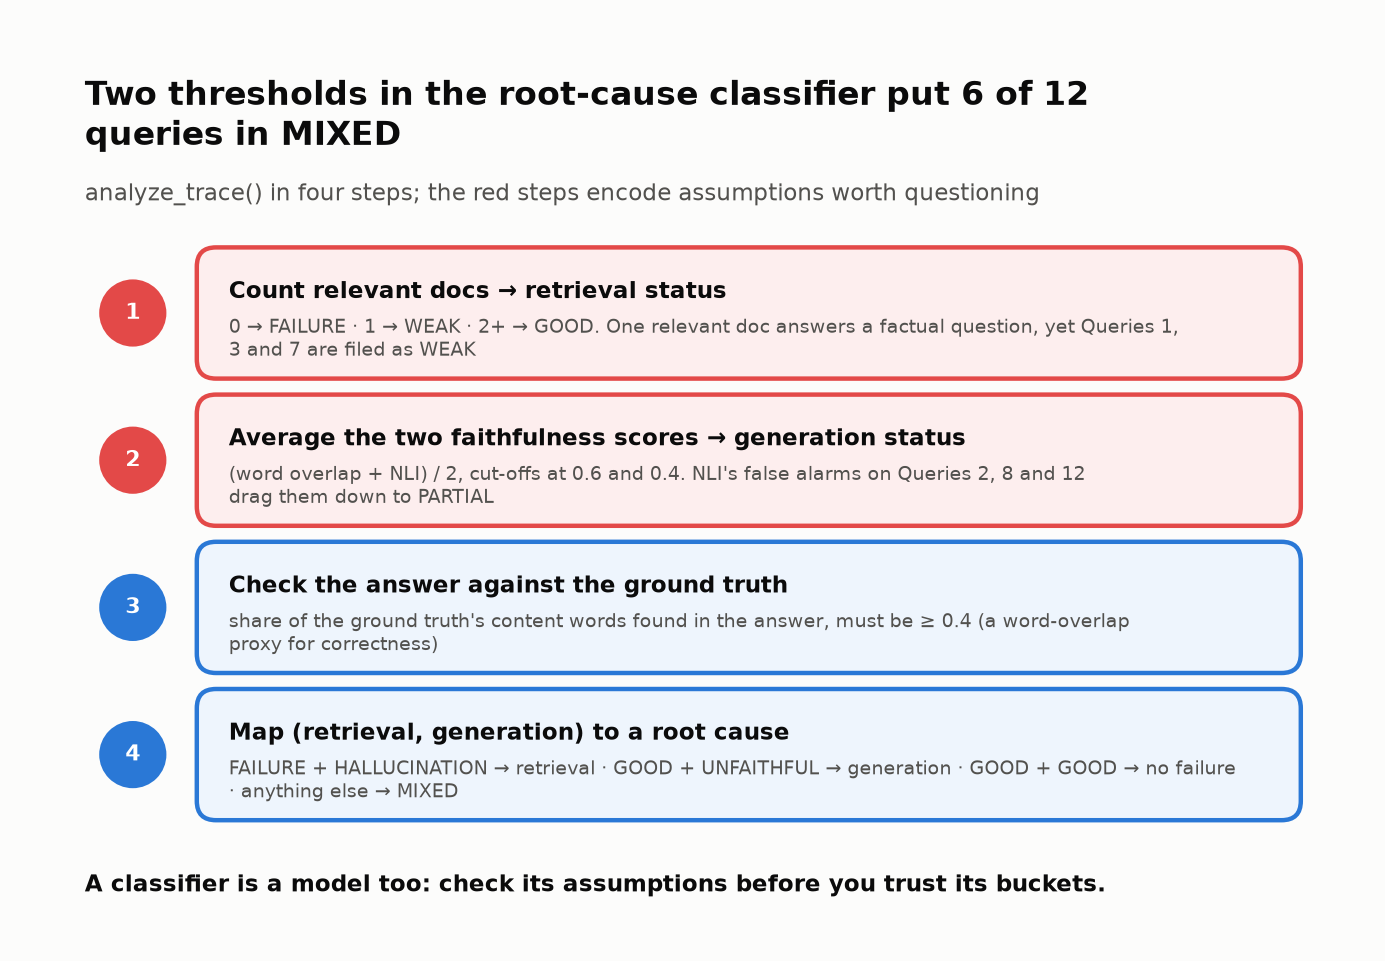
<sub>🖼️ *The red steps are assumptions, not measurements. Change either one and the buckets move.*</sub>

⏱️ **60-second experiment:** in `classify_retrieval`, change `n_relevant <= 1` to `n_relevant < 1` and rerun the three Task 7 cells. Queries 1, 3 and 7 move to NO FAILURE, and MIXED shrinks to Queries 2, 8 and 12: all three the scorer's doing. Change it back afterwards.

🗣️ **Say it to a colleague:** "When a trace looks bad, check the grader before you blame the pipeline."

The most dangerous pattern so far is **retrieval failure + confident generation** (Queries 4 and 6). But the team wrote all 12 questions *while reading the policy docs*, and real users don't phrase things that way.

➡️ **Bridge:** in Task 8, four questions arrive from this week's production logs, and one of them passes every check you've built.

---

## Task 8: 🏭 A Production Sample Arrives: Faithful ≠ Correct

**Stakes:** the answer that passes every automated check is the one nobody re-reads before it reaches an employee.

🧭 **Where you are:** Act III of IV, *The twist* (Tasks 8–9): real questions arrive, and two assumptions break: faithful means correct, and relevant means answerable.

### Goal
Score four questions from this week's production logs with the *same* functions, place all 16 answers on a faithfulness × correctness grid, and compare the offline set with the production sample.

### 🎯 Why This Matters
**Faithfulness** asks "is the answer supported by the retrieved docs?" **Correctness** asks "is the answer true?" They split in two directions:
- **Faithful but wrong**: the docs were wrong, stale or conflicting, and the answer copied them faithfully.
- **Correct but unfaithful**: the model guessed right from its training data. You can't audit that, and it won't hold for the next question.

> 📘 **Concept · Doc-derived (synthetic) test set**
>
> **What it is:** questions written by someone reading the documents, so they borrow the documents' words. Cheap and fast, and the usual first eval set; the offline set here is one.
>
> **What it can't tell you:** how the system does on questions real users type, in their own words, about things the docs may not cover.
>
> **Anchor:** offline Query 1 asks "How many PTO days do new employees get?" and its doc says "New full-time employees receive 15 PTO days". Production Query 16 asks about "time off", a phrase none of its docs uses.

The **production sample** is what employees actually typed. A benefits **SME** (subject-matter expert) grades every answer against the current handbook: slow and expensive, and the closest you get to ground truth.

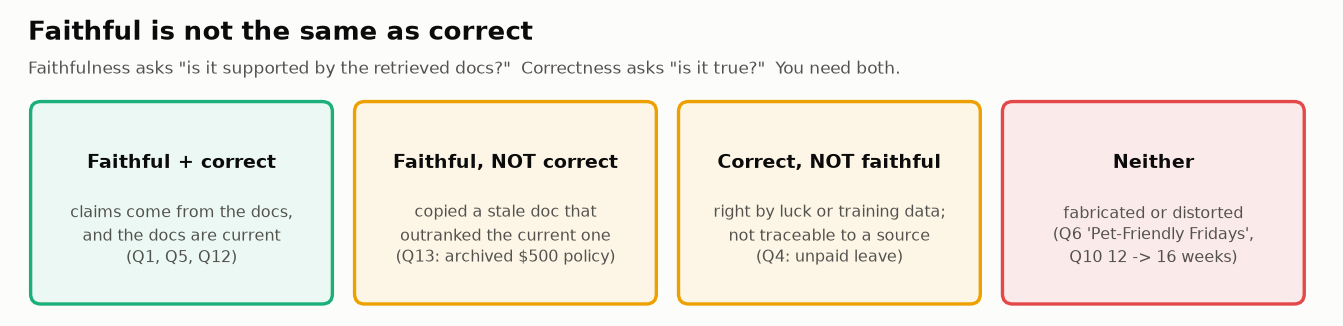

<sub>🖼️ *Faithfulness and correctness are different axes; this lab has an example in every box*</sub>

> 🔮 **Predict:** the system's answers on the offline set were correct 10 times out of 12. On four questions typed by real employees it will score (A) 75–100% · (B) about 50% · (C) 25% or less. And will any answer pass **every** retrieval and faithfulness check yet be wrong: yes or no?

### Steps
1. Load the production sample (collapsed 🧰 fixture cell) and score it with the same functions as before
2. Spotlight Query 13
3. Add the SME's labels and build the faithfulness × correctness grid
4. Compare the offline set with the production sample, with 95% confidence intervals

> 📐 **Confidence intervals in one paragraph.** A **95% confidence interval (CI)** is the range of true rates that could plausibly have produced the score you saw. The textbook formula p ± 1.96·√(p(1−p)/n), with p the observed rate and n the number of questions, breaks at small n: for 1 correct out of 4 it gives 25% ± 42%, a lower bound of **−17%**. The **Wilson interval** fixes that and stays inside 0–100% (here 5%–70%).

In [ ]:
# @title 🧰 Fixtures: 4 questions from this week's production logs, same schema plus a source tag (hidden · 66 lines · expand Query 13 after the spotlight)
# 🆕 Four questions sampled from this week's production logs (real employees, real phrasing).
# Same schema as rag_dataset, plus a "source" tag so we can compare the two sets later.
production_sample = [
    {
        "id": 13,
        "query": "how much can I spend on a desk + chair for working from home?",
        # Two versions of the same policy were indexed. The ARCHIVED one ranks first.
        "retrieved_docs": [
            "Home Office Policy (2023 handbook, archived): remote employees may expense up to $500 for home office equipment such as a desk or chair.",
            "Employees working remotely must maintain core hours of 10am-3pm in their local time zone.",
            "Home office equipment stipends of up to $1,000 are available for remote workers (2026 handbook).",
            "VPN access is required for all remote work to ensure secure connections to company systems.",
            "Office furniture changes require approval from your floor coordinator to ensure space planning compliance.",
        ],
        "relevance_labels": [1, 0, 1, 0, 0],  # both stipend docs are on-topic, so a labeler marks both relevant
        "generated_answer": "Remote employees may expense up to $500 for home office equipment such as a desk or chair.",
        "ground_truth": "Up to $1,000 under the current 2026 handbook. The $500 figure comes from the archived 2023 handbook.",
        "source": "production",
    },
    {
        "id": 14,
        "query": "can I borrow money from my 401k?",
        # Every 401(k) doc is on-topic... and none of them mentions loans.
        "retrieved_docs": [
            "The company matches 401(k) contributions dollar-for-dollar up to 4% of base salary. Matching contributions vest over 3 years: 33% after year 1, 66% after year 2, 100% after year 3.",
            "Employees can adjust their 401(k) contribution percentage at any time through the benefits portal.",
            "The company offers both traditional and Roth 401(k) options.",
            "Financial planning consultations are available quarterly at no cost to employees.",
            "Health insurance enrollment occurs during the annual open enrollment period in November.",
        ],
        "relevance_labels": [1, 1, 1, 1, 0],
        "generated_answer": "Yes. You can take a 401(k) loan of up to 50% of your vested balance, to a maximum of $50,000, repaid through payroll deductions over 5 years.",
        "ground_truth": "The handbook does not cover 401(k) loans. Loan rules are set by the plan; refer the employee to the Benefits team.",
        "source": "production",
    },
    {
        "id": 15,
        "query": "what's the per diem for a work trip to London?",
        "retrieved_docs": [
            "Travel expenses must be submitted within 30 days of the trip using the expense management system.",
            "Employees may expense co-working space fees up to $200/month when traveling.",
            "Client entertainment expenses are capped at $150 per person per meal and require a receipt and attendee list.",
            "Office supply purchases under $50 do not require pre-approval.",
            "Annual team-building budgets are allocated at $500 per team member.",
        ],
        "relevance_labels": [1, 1, 0, 0, 0],
        "generated_answer": "I don't have enough information in the policy documents to answer that. Please check with Finance.",
        "ground_truth": "The handbook has no per-diem rates. The assistant should say so and route the employee to Finance.",
        "source": "production",
    },
    {
        "id": 16,
        "query": "how far ahead do I need to ask for time off?",
        "retrieved_docs": [
            "Company holidays include New Year's Day, Memorial Day, Independence Day, Labor Day, Thanksgiving, and Christmas.",
            "PTO requests must be submitted at least 2 weeks in advance through the HR portal.",
            "New full-time employees receive 15 PTO days per year, accrued monthly starting from their hire date.",
            "Part-time employees receive prorated PTO based on their scheduled hours.",
            "After 5 years of service, employees receive an additional 5 PTO days per year.",
        ],
        "relevance_labels": [0, 1, 0, 0, 0],
        "generated_answer": "I'm sorry, I couldn't find a policy about how far in advance time off must be requested.",
        "ground_truth": "PTO requests must be submitted at least 2 weeks in advance through the HR portal.",
        "source": "production",
    },
]

In [ ]:
# 🏭 Score the production sample with exactly the checks you built on the offline set
all_items = rag_dataset + production_sample
ITEMS = {it["id"]: it for it in all_items}

def score_item(it):
    """Run every automated check from Tasks 4–6 on one query."""
    labels = it["relevance_labels"]
    # 👀 Look at: the same functions as Tasks 4-6, unchanged; only the questions are new
    nli = nli_faithfulness(it["generated_answer"], it["retrieved_docs"], labels)
    return {
        "id": it["id"], "source": it["source"], "query": it["query"][:48],
        "precision@5": precision_at_k(labels), "ndcg@5": ndcg_at_k(labels), "mrr@5": mrr_at_k(labels),
        "rule_based": rule_based_faithfulness(it["generated_answer"], it["retrieved_docs"], labels),
        "nli_entailment": nli["entailment_score"],
        "number_flags": unsupported_numbers(it),
        "abstained": is_abstention(it["generated_answer"]),
    }

scores_df = pd.DataFrame([score_item(it) for it in all_items]).set_index("id")
print(scores_df.loc[[13, 14, 15, 16]].to_string(float_format="%.2f"))

> 🔮 **Predict:** Query 13's answer faces five automated checks: Precision@5, MRR, word overlap, NLI and the number check. How many will it pass? (A) 0–1 · (B) 2–3 · (C) all 5

In [ ]:
# 🔦 Spotlight: Query 13. Read the question, the top doc and the answer, then look at its scores.
q13, s13 = ITEMS[13], scores_df.loc[13]
print("Q:", q13["query"])
print("Top retrieved doc:", q13["retrieved_docs"][0])
print("Answer:", q13["generated_answer"])
print("Ground truth (current handbook):", q13["ground_truth"])

tiles([
    ("Precision@5", f"{s13['precision@5']:.2f}", "on-topic retrieval", "good"),
    ("MRR", f"{s13['mrr@5']:.2f}", "relevant doc ranked #1", "good"),
    ("Word-overlap faithfulness", f"{s13['rule_based']:.2f}", "supported by context", "good"),
    ("NLI entailment", f"{s13['nli_entailment']:.2f}", "context entails the answer", "good"),
    ("Number check", "pass" if not s13["number_flags"] else "flag", "every number is in the docs", "good"),
    ("Correct?", "NO", "$500 is the 2023 policy; it's $1,000 now", "critical"),
])
insight(
    "Query 13 passes every automated check you've built, and the answer is wrong",
    f"Retrieval ranked an on-topic doc first (MRR {s13['mrr@5']:.2f}); faithfulness scorers agree the answer is "
    f"supported (word overlap {s13['rule_based']:.2f}, NLI {s13['nli_entailment']:.2f}); the number check passes. "
    "The answer is faithful to the **archived 2023 handbook**, which outranked the current one. Faithfulness only "
    "tells you the answer matches its context; when the context is stale, a perfect score certifies a wrong answer.\n"
    "**Rule of thumb:** evaluate *correctness against a trusted reference* separately from faithfulness, and treat "
    "index hygiene (expiring old versions, freshness metadata, conflict detection) as part of RAG quality.",
    kind="surprise")

In [ ]:
# @title 🧰 Chart helper: draw_quadrant() paints the faithfulness × correctness grid (hidden · 17 lines · expand if curious)
def draw_quadrant(quad, n_wrong):
    """quad: {(faithful, correct): [query ids]} → a 2×2 chart titled with the faithful-but-wrong count."""
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    colors = {(True, True): STATUS["good"], (True, False): STATUS["critical"],
              (False, True): STATUS["warning"], (False, False): STATUS["critical"]}
    names = {(True, True): "faithful + correct", (True, False): "faithful, WRONG",
             (False, True): "correct by luck", (False, False): "unfaithful + wrong"}
    for (f, c), ids in quad.items():
        x, y = (0 if f else 1), (1 if c else 0)
        ax.add_patch(plt.Rectangle((x, y), 0.96, 0.96, color=colors[(f, c)], alpha=0.18))
        ax.text(x + 0.48, y + 0.62, str(len(ids)), ha="center", va="center", fontsize=30, weight="bold")
        ax.text(x + 0.48, y + 0.30, f"{names[(f, c)]}\nqueries {ids}", ha="center", va="center", fontsize=10, color="#52514e")
    ax.set_xlim(-0.04, 2); ax.set_ylim(-0.04, 2); ax.grid(False)
    ax.set_xticks([0.48, 1.48]); ax.set_xticklabels(["faithful (SME)", "unfaithful (SME)"])
    ax.set_yticks([0.48, 1.48]); ax.set_yticklabels(["wrong", "correct"])
    ax.set_title(f"{len(quad[(True, False)])} of {n_wrong} wrong answers would pass a perfect faithfulness check")
    plt.tight_layout(); plt.show()

In [ ]:
# 🧑‍⚖️ A benefits SME graded every answer against the CURRENT handbook (slow, expensive, trustworthy labels).
#   faithful: are the answer's claims supported by the retrieved docs?  (None = the system abstained)
#   outcome:  "correct" / "wrong" / "abstained"
SME = {
    1: (True, "correct"),  2: (True, "correct"),  3: (True, "correct"),  4: (False, "correct"),
    5: (True, "correct"),  6: (False, "wrong"),   7: (True, "correct"),  8: (True, "correct"),
    9: (True, "correct"), 10: (False, "wrong"),  11: (True, "correct"), 12: (True, "correct"),
    13: (True, "wrong"),  14: (False, "wrong"),  15: (None, "abstained"), 16: (None, "abstained"),
}
scores_df["sme_faithful"] = [SME[i][0] for i in scores_df.index]
scores_df["outcome"] = [SME[i][1] for i in scores_df.index]

answered = scores_df[scores_df["outcome"] != "abstained"]
# 👀 Look at: faithfulness and correctness are labelled separately, so all four combinations can occur
quad = {(f, c): answered[(answered["sme_faithful"] == f) & ((answered["outcome"] == "correct") == c)].index.tolist()
        for f in (True, False) for c in (True, False)}
wrong = answered[answered["outcome"] == "wrong"]
draw_quadrant(quad, len(wrong))

In [ ]:
# @title 🧰 Helpers: wilson() 95% interval and word_reuse(), the share of a query's words found in its docs (hidden · 14 lines · expand if curious)
def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion: honest error bars for small n."""
    if n == 0:
        return (0.0, 1.0)
    p = k / n
    mid = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (max(0.0, mid - half), min(1.0, mid + half))

def word_reuse(it):
    """Share of the query's content words that also appear in its relevant docs."""
    q = tokenize(it["query"]) - STOP_WORDS
    rel = " ".join(d for d, r in zip(it["retrieved_docs"], it["relevance_labels"]) if r)
    return len(q & tokenize(rel)) / len(q) if q and rel else 0.0

In [ ]:
# 📉 Offline set vs. production sample: same system, same scorers.
def good_behavior(row):
    """Correct answer, or a correct abstention (the corpus has no answer: queries 14 and 15)."""
    return row["outcome"] == "correct" or (row["outcome"] == "abstained" and row.name in (14, 15))

scores_df["good"] = scores_df.apply(good_behavior, axis=1)
scores_df["word_reuse"] = [word_reuse(ITEMS[i]) for i in scores_df.index]
summary = {}
for src in ("offline", "production"):
    part = scores_df[scores_df["source"] == src]
    k, n = int(part["good"].sum()), len(part)
    summary[src] = (k, n, wilson(k, n), part["word_reuse"].mean())

(k_o, n_o, ci_o, reuse_o), (k_p, n_p, ci_p, reuse_p) = summary["offline"], summary["production"]
tiles([
    ("Offline set (doc-derived)", f"{k_o}/{n_o} = {k_o/n_o:.0%}", f"95% CI {ci_o[0]:.0%}–{ci_o[1]:.0%}", "good"),
    ("Production sample", f"{k_p}/{n_p} = {k_p/n_p:.0%}", f"95% CI {ci_p[0]:.0%}–{ci_p[1]:.0%}", "critical"),
    ("Query words reused from docs", f"{reuse_o:.0%} vs {reuse_p:.0%}", "offline vs production", "warning"),
])
insight(
    f"Same system: {k_o/n_o:.0%} on questions written from the docs, {k_p/n_p:.0%} on questions typed by employees",
    f"The offline questions reuse {reuse_o:.0%} of their content words from the relevant docs; the production questions "
    f"reuse {reuse_p:.0%} (\"time off\" for \"PTO\", \"borrow from my 401k\"): questions written *from* the docs are easy "
    "for a retriever built on those docs. n is tiny (the intervals overlap), but the literature agrees: Rahmani et al. "
    "(2024) found LLM-based systems score higher on synthetic judgments, and a 2025 study found synthetic QA benchmarks "
    "may **rank RAG systems differently** than human-annotated ones.\n"
    "**Rule of thumb:** use doc-derived (synthetic) test sets for A/B regression checks (\"did chunker B beat A?\"), "
    "never for absolute claims (\"our RAG is 83% accurate\"). Grow the set from real queries.",
    kind="research")

### Checkpoint ✅
You should see the four production rows, a six-tile spotlight with a 🤯 *Counterintuitive* card, a 2×2 quadrant chart, and a three-tile comparison with a 📚 *research* card.

### Expected Output
```
        source                                             query  precision@5  ndcg@5  mrr@5  rule_based  nli_entailment    number_flags  abstained
id
13  production  how much can I spend on a desk + chair for worki         0.40    0.92   1.00        1.00            0.92              []      False
14  production                  can I borrow money from my 401k?         0.80    1.00   1.00        0.29            0.01  [5, 50, 50000]      False
15  production    what's the per diem for a work trip to London?         0.40    1.00   1.00        0.00            0.00              []       True
16  production      how far ahead do I need to ask for time off?         0.20    0.63   0.50        0.15            0.00              []       True
```
- Spotlight card: *"Query 13 passes every automated check you've built, and the answer is wrong."*
- Quadrant title: *"1 of 4 wrong answers would pass a perfect faithfulness check"*: faithful + correct **9**, faithful + wrong **1** ([13]), correct by luck **1** ([4]), unfaithful + wrong **3** ([6, 10, 14]).
- Tiles: offline **10/12 = 83%** (95% CI 55%–95%) · production **1/4 = 25%** (95% CI 5%–70%) · query words reused **37% vs 17%**.

> 💡 The NLI scorer (0.01) and the number check (`5`, `50`, `50000` aren't in the docs) both catch Query 14. Nothing automated catches Query 13, which makes it the dangerous one.

**What just happened:** the retriever ranked the archived 2023 policy first; both stipend docs are on-topic, so the labeler marked both relevant; the model copied the first; and every scorer compared the answer with that same context. Each check did its job, and none of them asks whether the context is *current*. Only the SME, reading the 2026 handbook, does.

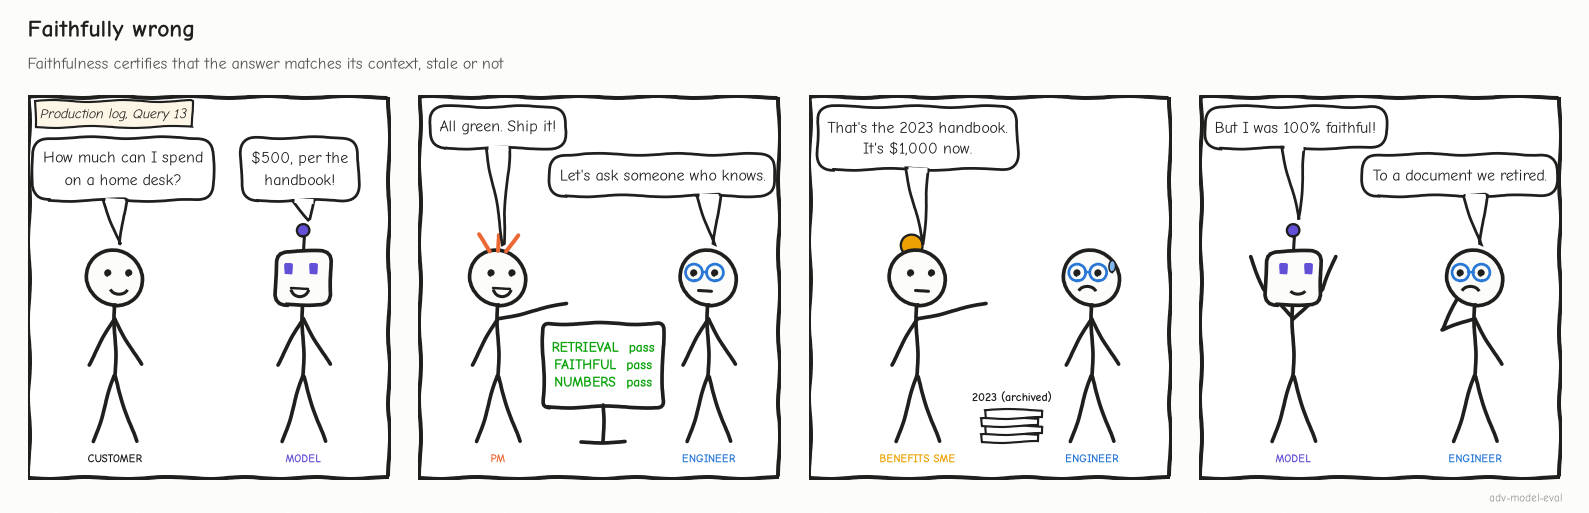

<sub>🖼️ *A perfect faithfulness score can certify a wrong answer.*</sub>

Query 4 is the mirror image, **correct but unfaithful**: a lucky guess you can't audit. You need both axes.

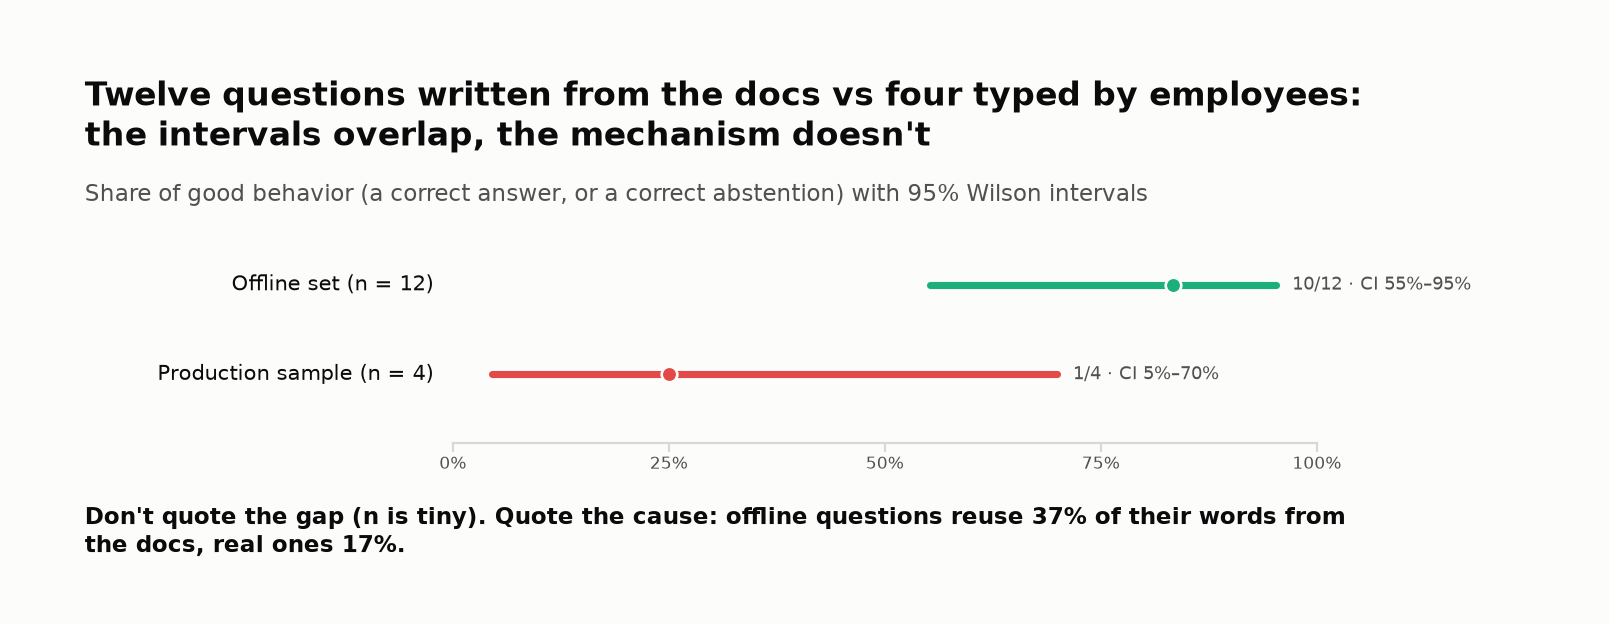
<sub>🖼️ *Four questions can't prove the gap. The vocabulary reuse, 37% vs 17%, explains why one is likely.*</sub>

🗣️ **Say it to a colleague:** "Faithful means 'agrees with what we retrieved', not 'true'. Retrieve last year's policy and faithfulness will certify last year's answer."

➡️ **Bridge:** look again at Queries 14 and 15. Retrieval found on-topic docs for both, yet neither context contains the answer; the system answered one and declined the other. Task 9 asks what no metric has asked yet: **was the context sufficient to answer at all?**

---

## Task 9: 🧱 Sufficient Context and Abstention

**Stakes:** Query 14's retrieval looks healthy (4 of 5 docs relevant), and the system invented 401(k) loan terms an employee could act on.

### Goal
Label whether each query's retrieved context is **sufficient** to answer it, cross that label with what the system did (answered correctly / abstained / answered wrong), and compare three answer/abstain policies on a **selective-answer metric**.

### 🎯 Why This Matters
**Relevant ≠ sufficient.** Every 401(k) doc is relevant to "can I borrow from my 401k?" (some US retirement plans let you borrow from your own balance; the plan sets the rules), and none of them mentions loans. Google's *Sufficient Context* study (Joren et al., ICLR 2025) made sufficiency its own label, separate from relevance and correctness; the card in Step 2 shows what it found.

> 📘 **Concept · Context sufficiency**
>
> **What it is:** the retrieved text contains every fact a correct answer needs. Offline you label it from **key facts** (the facts an annotator says a correct answer must contain); at serving time an LLM **autorater** estimates it.
>
> **What it can't tell you:** whether the model will use those facts well (Query 10 had sufficient context and still changed 12 to 16), or whether they are current.
>
> **Anchor:** Query 14's four relevant docs cover the 401(k) match and vesting, contribution changes, Roth options and financial planning. None mentions loans: relevant, and insufficient.

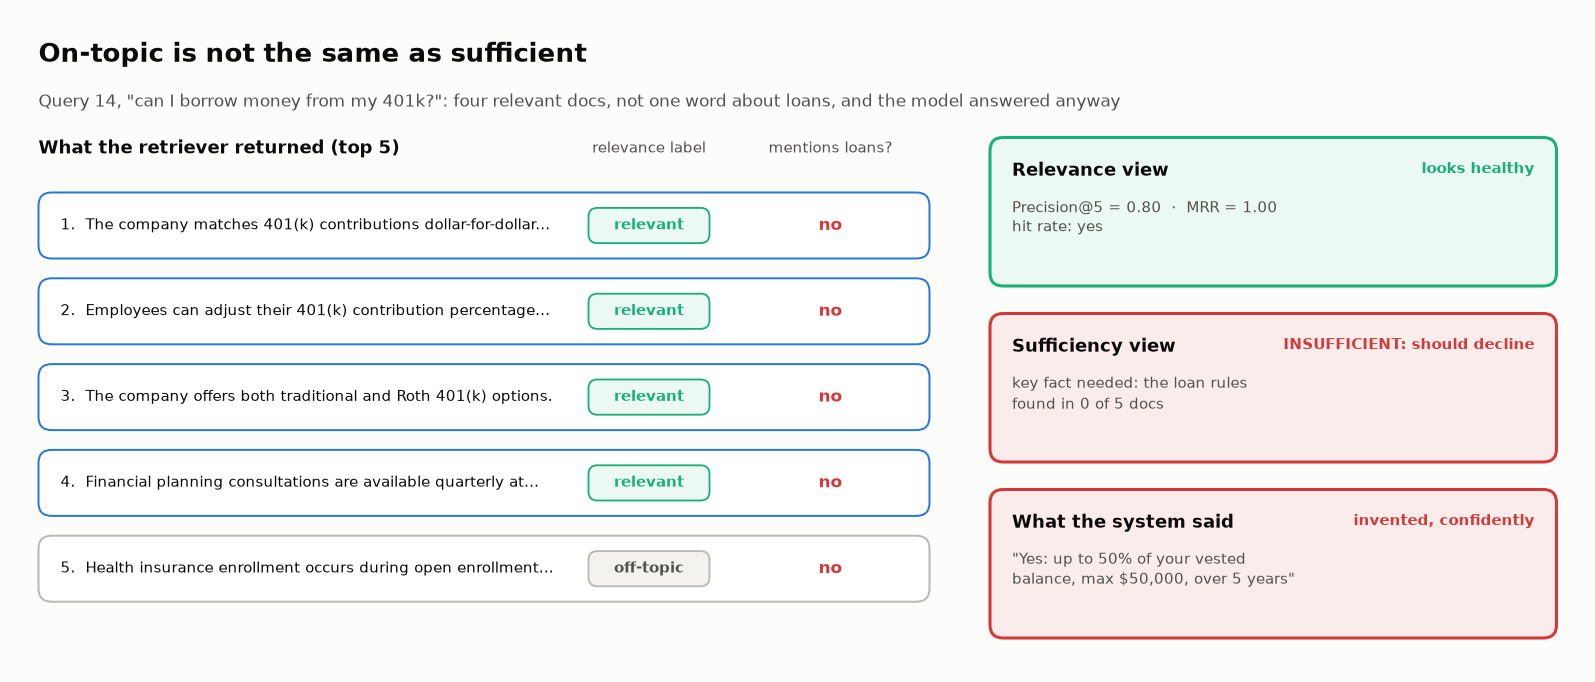

<sub>🖼️ *Relevance asks "is it about the topic?" Sufficiency asks "is the answer in here?"*</sub>

Abstention fails in two directions: **answering when the context is insufficient** (the source of confident hallucinations), and **over-refusal**, declining when the answer is in the retrieved docs.

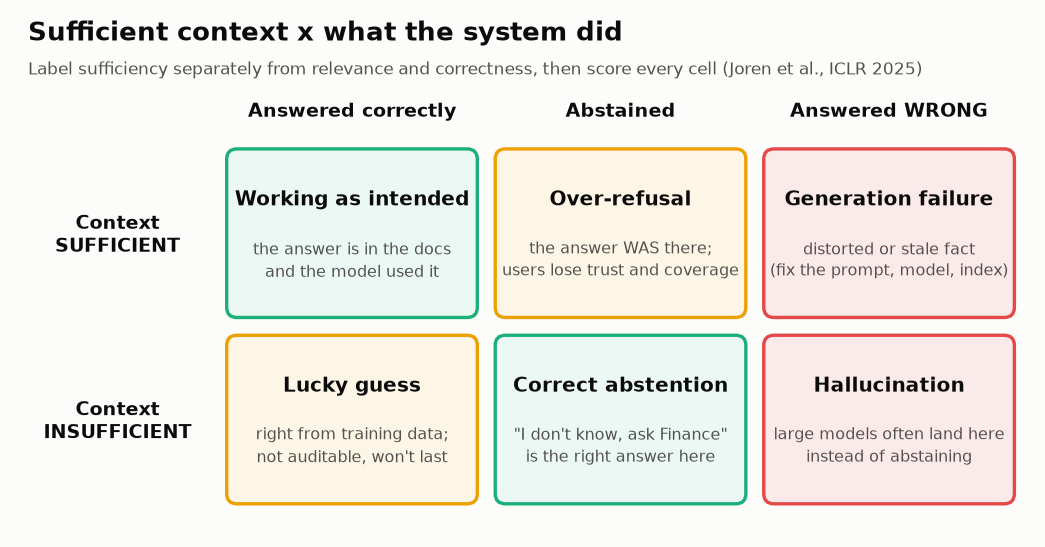

<sub>🖼️ *Every cell of this grid needs its own count. Faithfulness alone sees none of them.*</sub>

**Labelling it here:** the context is sufficient if every key fact appears in the retrieved docs; questions the handbook can't answer get `None`, because no context could be sufficient. (Serving time has no key facts; see the autorater note at the end of this task.)

> 📘 **Concept · Coverage and selective accuracy**
>
> **What it is:** for a system that can decline, two numbers reported together. **Coverage** = share of questions answered; **selective accuracy** = share of *answered* questions that are correct.
>
> **What it can't tell you:** either number alone. Abstaining more raises selective accuracy and lowers coverage: a system that answers one easy question and declines the rest scores 100%.
>
> **Anchor:** as shipped, the assistant answered 14 of 16 questions (coverage 88%), and 10 of those 14 were correct (selective accuracy 71%).

> 🔮 **Predict:** four queries have insufficient context. How many did the system *answer anyway*? (A) 0–1 · (B) 2 · (C) 3–4. If it abstained whenever context was insufficient, selective accuracy would rise by (A) under 5 points · (B) 5–15 · (C) over 15. At what cost in coverage?

### Steps
1. Label sufficiency from key facts and compare it with "has a relevant doc"
2. Build the sufficiency × outcome table
3. Compare three answer/abstain policies on coverage and selective accuracy

In [ ]:
# 🧱 Key facts a correct answer must contain (written by the annotator from the CURRENT handbook).
# None = the handbook doesn't answer this question at all, so no retrieved context can be sufficient.
KEY_FACTS = {
    1: ["15 pto days"], 2: ["$150 per person"], 3: ["legal", "30 days"], 4: ["unpaid"],
    5: ["4%", "3 years"], 6: ["service animal"], 7: ["2222"],
    8: ["director", "personal charges", "15 business days", "24 hours"], 9: ["$3,000", "online courses"],
    10: ["12 weeks"], 11: ["facilities portal"], 12: ["forfeited", "90 days"],
    13: ["$1,000"], 14: None, 15: None, 16: ["2 weeks"],
}

def context_sufficient(qid):
    facts = KEY_FACTS[qid]
    if facts is None:
        return False
    context = " ".join(ITEMS[qid]["retrieved_docs"]).lower()
    # 👀 Look at: sufficient = EVERY key fact appears somewhere in the retrieved text; relevance labels never enter
    return all(fact.lower() in context for fact in facts)

scores_df["has_relevant"] = [sum(ITEMS[i]["relevance_labels"]) > 0 for i in scores_df.index]
scores_df["sufficient"] = [context_sufficient(i) for i in scores_df.index]
disagree = scores_df[scores_df["has_relevant"] != scores_df["sufficient"]]
print("Where 'has a relevant doc' and 'context is sufficient' disagree:\n")
print(disagree[["query", "precision@5", "has_relevant", "sufficient", "outcome"]].to_string())

In [ ]:
# 📊 Sufficiency × outcome: the 2×3 table from the diagram, filled in with our 16 queries
table = pd.crosstab(scores_df["sufficient"].map({True: "sufficient", False: "insufficient"}),
                    scores_df["outcome"]).reindex(index=["sufficient", "insufficient"],
                                                  columns=["correct", "abstained", "wrong"], fill_value=0)
display(table)

ins = scores_df[~scores_df["sufficient"]]
suf = scores_df[scores_df["sufficient"]]
ins_answered = ins[ins["outcome"] != "abstained"]
suf_abstained = suf[suf["outcome"] == "abstained"]
tiles([
    ("Insufficient context", len(ins), f"queries {ins.index.tolist()}", None),
    ("…answered anyway", f"{len(ins_answered)}/{len(ins)}", f"queries {ins_answered.index.tolist()}", "critical"),
    ("…of which wrong", int((ins["outcome"] == "wrong").sum()), "hallucinated", "critical"),
    ("Over-refusals", f"{len(suf_abstained)}/{len(suf)}", f"sufficient but abstained: {suf_abstained.index.tolist()}", "warning"),
])
insight(
    f"When the context could not support an answer, the system answered anyway {len(ins_answered)} times out of {len(ins)}",
    f"It abstained correctly only on {ins[ins['outcome'] == 'abstained'].index.tolist()}, and it *also* refused "
    f"{suf_abstained.index.tolist()} when the answer was in the retrieved docs: overconfidence and over-refusal in one "
    "system. Google's *Sufficient Context* study (Joren et al., ICLR 2025) found large models often answer incorrectly "
    "instead of abstaining when context is insufficient, and that *some* context can make a model **less** likely to "
    "abstain. RefusalBench (2025) found some models refused over 60% of answerable queries while still answering "
    "unanswerable ones.\n"
    "**Rule of thumb:** test abstention in both directions: unanswerable questions (should decline) *and* "
    "answerable ones phrased the way users phrase them (should not decline).",
    kind="research")

In [ ]:
# @title 🧰 Chart helper: plot_policies() draws coverage vs. selective accuracy, one dot per policy (hidden · 13 lines · expand if curious)
def plot_policies(policy_df, base, gate):
    """One dot per answer/abstain policy: coverage on x, selective accuracy on y."""
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for (name, r), color in zip(policy_df.iterrows(), PALETTE):
        ax.scatter(r["coverage"], r["selective_accuracy"], s=140, color=color, zorder=3)
        ax.annotate(f"{name}\n{r['wrong_answers']} wrong answers", (r["coverage"], r["selective_accuracy"]),
                    textcoords="offset points", xytext=(10, -4), fontsize=9.5, color="#52514e")
    ax.set_xlim(min(0.5, policy_df["coverage"].min() - 0.05), 1.05)
    ax.set_ylim(min(0.6, policy_df["selective_accuracy"].min() - 0.05), max(0.95, policy_df["selective_accuracy"].max() + 0.05))
    ax.set_xlabel("coverage (share of questions answered)"); ax.set_ylabel("selective accuracy")
    ax.set_title(f"Abstaining on insufficient context: {100*(gate.coverage-base.coverage):+.0f} pts coverage, "
                 f"{100*(gate.selective_accuracy-base.selective_accuracy):+.0f} pts accuracy")
    plt.tight_layout(); plt.show()

In [ ]:
# ⚖️ Selective-answer metric: coverage vs. accuracy-when-answering for three policies.
answers_now = scores_df["outcome"] != "abstained"
POLICIES = {
    "As shipped (always answer)": answers_now,
    "Abstain if no relevant doc": answers_now & scores_df["has_relevant"],
    "Abstain if context insufficient": answers_now & scores_df["sufficient"],
}

rows = []
for name, answers in POLICIES.items():
    ans = scores_df[answers]
    rows.append({"policy": name, "answered": len(ans),
                 # 👀 Look at: coverage divides by ALL questions, selective accuracy only by the answered ones
                 "coverage": len(ans) / len(scores_df),
                 "selective_accuracy": (ans["outcome"] == "correct").mean(),
                 "wrong_answers": int((ans["outcome"] == "wrong").sum()),
                 "wrong_ids": ans.index[ans["outcome"] == "wrong"].tolist()})
policy_df = pd.DataFrame(rows).set_index("policy")
print(policy_df.to_string(float_format="%.2f"))
base, gate = policy_df.loc["As shipped (always answer)"], policy_df.loc["Abstain if context insufficient"]
plot_policies(policy_df, base, gate)

insight(
    f"The sufficiency gate cut wrong answers from {base.wrong_answers} to {gate.wrong_answers} and raised accuracy-when-answering "
    f"from {base.selective_accuracy:.0%} to {gate.selective_accuracy:.0%}, at {gate.coverage:.0%} coverage instead of {base.coverage:.0%}",
    f"The relevance gate only got to {policy_df.loc['Abstain if no relevant doc'].selective_accuracy:.0%}: it can't see that Query 14's on-topic "
    f"docs don't contain the answer. The {gate.wrong_answers} wrong answers that survive every gate, {gate.wrong_ids}, had "
    "*sufficient* context: a distorted number and a stale doc. No abstention policy fixes those; the number check and "
    "index hygiene do. And no gate can fix the over-refusal on Query 16, because gates only remove answers.\n"
    "**Rule of thumb:** report coverage and selective accuracy together. A single accuracy number lets a system win "
    f"by refusing everything (n = {len(scores_df)} here, so treat the percentages as illustrations, not estimates).")

### Checkpoint ✅
You should see a 2-row disagreement table, a 2×3 crosstab, four tiles with a 📚 card, a 3-row policy table, a scatter chart and a 💡 card.

### Expected Output
```
Where 'has a relevant doc' and 'context is sufficient' disagree:

                                             query  precision@5  has_relevant  sufficient    outcome
id
14                can I borrow money from my 401k?          0.8          True       False      wrong
15  what's the per diem for a work trip to London?          0.4          True       False  abstained
```
| | correct | abstained | wrong |
|---|---|---|---|
| **sufficient** | 9 | 1 | 2 |
| **insufficient** | 1 | 1 | 2 |

```
                                 answered  coverage  selective_accuracy  wrong_answers   wrong_ids
As shipped (always answer)             14      0.88                0.71              4  [6, 10, 13, 14]
Abstain if no relevant doc             12      0.75                0.75              3  [10, 13, 14]
Abstain if context insufficient        11      0.69                0.82              2  [10, 13]
```
Chart title: *"Abstaining on insufficient context: -19 pts coverage, +10 pts accuracy"*.

**What just happened:** a gate can only turn an answer into an abstention. The sufficiency gate removed Queries 4, 6 and 14 (one lucky guess, two wrong answers) because their contexts lacked a key fact. Queries 10 and 13 had every key fact in context and were wrong anyway, so no abstention policy reaches them, and no gate can repair Query 16's refusal.

🗣️ **Say it to a colleague:** "Relevant means on-topic; sufficient means the answer is in there. Gate on the second, and report coverage next to accuracy."

⏱️ **60-second experiment:** add `"Abstain if NLI < 0.5": answers_now & (scores_df["nli_entailment"] >= 0.5)` to `POLICIES` and rerun the cell. You get the best selective accuracy yet at the lowest coverage, and the one wrong answer it keeps is Query 13.

> 🎁 **Bonus observation.** In Task 8's scores, the NLI model labels Query 16's refusal a **contradiction** of its context (the doc says "2 weeks in advance"). An entailment model pointed at refusals is a cheap **over-refusal detector**.

### 🏭 At serving time: an LLM sufficiency autorater
In production there are no key facts; an LLM judge (an **autorater**) sees only the question and the retrieved context. Google reported its LLM autorater labels sufficiency with about 93% accuracy (per secondary coverage of the paper). A minimal prompt, behind your usual `PROVIDER` switch (current IDs: `gpt-6-luna` via the Responses API, or `claude-haiku-5-5`):

```text
Question: {question}
Retrieved context: {context}
Can the question be fully answered using ONLY this context? Answer SUFFICIENT or INSUFFICIENT,
then quote the sentence(s) that contain the answer (or write NONE).
```
Validate it against human labels (TPR/TNR), as you did the faithfulness scorers in Task 6, before it gates any answer. Google's paper combines a sufficiency signal with the model's own confidence ("selective generation") and reports a **2–10%** gain in the fraction of correct answers among those the model gives.

➡️ **Bridge:** you've now seen four failure shapes: no evidence, distorted evidence, stale evidence, and insufficient evidence. Next, design stress tests that hunt for each one *before* users do.

---

## Task 10: 🧠 Your Turn: Create Stress Test Queries

**Stakes:** a stress suite of only "should refuse" questions gives a perfect score to an assistant that refuses everything.

🧭 **Where you are:** Act IV of IV, *Decide* (Tasks 10–11): hunt for the next failure before users do, then make the ship call.

### Goal
Design a **balanced** stress-test suite: probes the system *should* decline, and probes it should *not* decline.

### 🎯 Why Stress Test?
So far you've scored queries someone else wrote. Queries 4, 6 and 14 had no usable evidence and still got confident answers; Query 16 had the evidence and refused. Stress tests find these failures before users do.

> ⚠️ **Common mistake:** testing only "should refuse" cases. A system that refuses everything passes them all. Pair every *should-abstain* probe with a *should-answer* probe.

### Categories of Stress Tests
Design **at least 2 queries per category**:

| Category | What it probes | Example |
|---|---|---|
| `ambiguous` | multiple valid readings | "What's the limit?" (PTO? expenses? credit card?) |
| `adversarial` | leading or misleading phrasing | "Can I expense my vacation if I check email during it?" |
| `should_abstain` | the handbook has no answer (out of scope or a coverage gap) | "What's the per diem in Tokyo?" |
| `should_answer` | answerable, but phrased like a real user (no doc vocabulary) | "do I lose my stock if I quit?" |
| `conflicting_context` | two policies or two versions disagree | "Does my education stipend deadline pause during parental leave?" |

For each query, write the text, pick the category, name the failure mode you expect, and describe a good and a bad response. Reuse the failure shapes from Tasks 8–9: vocabulary mismatch (Q16), stale versions (Q13), on-topic but insufficient context (Q14). There's no single correct set.

> 🔮 **Predict:** your finished suite will have (A) fewer *should-answer* than *should-abstain* probes · (B) the same number · (C) more. Most people land on A.

In [ ]:
# @title 🧰 Helper: review_suite() lists your probes and checks the should-abstain / should-answer balance (hidden · 21 lines · expand if curious)
def review_suite(my_stress_tests):
    """List the probes you wrote and check the should-abstain / should-answer balance."""
    filled = [t for t in my_stress_tests if t["query"].strip() not in ("", "...")]
    cat_counts = Counter(t["category"] for t in filled)
    print(f"📋 My Stress Test Suite: {len(filled)} of {len(my_stress_tests)} probes written\n")
    for i, test in enumerate(filled, 1):
        print(f"  {i}. [{test['category'].upper()}] \"{test['query']}\"  → expected failure: {test['expected_failure']}")

    n_abstain, n_answer = cat_counts["should_abstain"], cat_counts["should_answer"]
    if not filled:
        insight(f"Your stress suite is still empty: 0 of {len(my_stress_tests)} probes written",
                "Replace the \"...\" placeholders above and re-run. Start with one *should_answer* probe: it's the "
                "category almost everyone forgets.", kind="warning")
    else:
        balanced = n_answer >= n_abstain > 0
        insight(f"Your suite: {n_abstain} should-abstain vs {n_answer} should-answer probes, "
                f"{len(cat_counts)}/5 categories covered",
                ("Balanced: a system can't pass this suite by refusing everything. " if balanced else
                 "Unbalanced: a system that refuses everything would score well on this suite. Add should-answer probes. ")
                + "**Rule of thumb:** for every probe that should trigger a refusal, write one that should *not*.",
                kind="insight" if balanced else "warning")

In [ ]:
# 🧠 YOUR TURN: design stress-test queries. Replace the "..." placeholders (aim for 2 per category, 10+ total).
def probe(category):
    return {"query": "...", "category": category, "expected_failure": "...",
            "good_response": "...", "bad_response": "..."}

my_stress_tests = [
    # --- Ambiguous: does the system ask for clarification or guess? ---
    probe("ambiguous"), probe("ambiguous"),
    # --- Adversarial: can it resist leading or misleading questions? ---
    probe("adversarial"), probe("adversarial"),
    # --- Should abstain: the handbook has no answer. Does it say so? ---
    probe("should_abstain"), probe("should_abstain"),
    # --- Should answer: answerable, phrased like a real user. Does it still answer? ---
    probe("should_answer"), probe("should_answer"),
    # --- Conflicting context: two policies or two versions disagree ---
    probe("conflicting_context"), probe("conflicting_context"),
]
# Example of a filled-in probe (edit the list above, don't just keep this one):
# {"query": "do I lose my stock if I quit?", "category": "should_answer",
#  "expected_failure": "vocabulary mismatch ('stock' vs 'options', 'quit' vs 'voluntary termination') → over-refusal",
#  "good_response": "Unvested options are forfeited; you have 90 days to exercise vested ones.",
#  "bad_response": "I couldn't find a policy about that."}

# 👀 Look at: the check that matters is should-answer probes ≥ should-abstain probes
review_suite(my_stress_tests)

### Checkpoint ✅
After filling in your stress tests and running the cell, verify that:
- You have at least 10 probes, at least 2 in each of the 5 categories
- `should_answer` probes are at least as many as `should_abstain` ones
- Each probe names a concrete failure mode (not just "a hard question")

### Expected Output
With the template untouched you'll see `📋 My Stress Test Suite: 0 of 10 probes written` and a ⚠️ card asking you to fill it in. Once filled, the card reports your should-abstain vs. should-answer balance.

**What just happened:** each category targets a failure this lab has already seen:

| Category | Danger if not caught |
|----------|---------------------|
| Ambiguous | Answers the wrong interpretation confidently |
| Adversarial | Produces incorrect policy guidance |
| Should abstain | Fabricates answers (Queries 6, 14) |
| Should answer | Over-refuses (Query 16); users stop trusting it |
| Conflicting context | Copies the stale version faithfully (Query 13) |

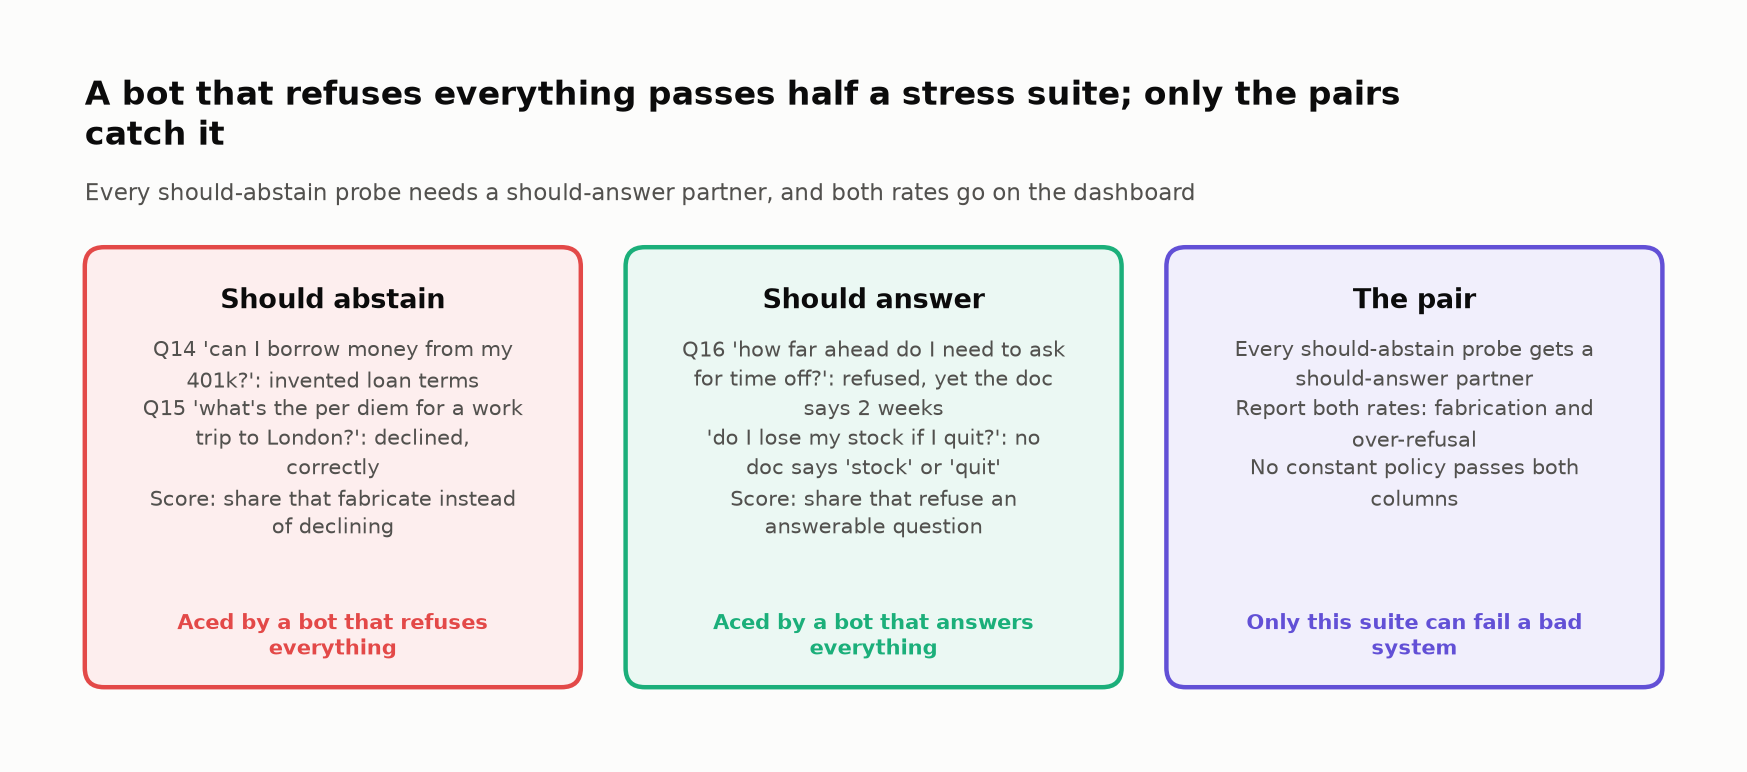
<sub>🖼️ *Score each column separately: one rate for fabrication, one for over-refusal.*</sub>

🗣️ **Say it to a colleague:** "For every probe that should make it refuse, write one that shouldn't. A bot that refuses everything aces half a test suite."

➡️ **Bridge:** time to put everything together and make the call: would you ship this system?

---

## Task 11: ⚠️ Open Challenge: Failure Analysis and the Ship Decision

**Stakes:** the rollout is yours to sign, and "most checks pass" is not a reason you can defend after the first wrong 401(k) answer.

### Goal
Document the cases where one stage looks fine but the outcome is wrong, then render a ship/block verdict.

### 🎯 Why This Is the Hardest Problem

```
           Retrieval    Generation    Visible to User?    Danger Level
           ─────────    ──────────    ────────────────    ────────────
  Case 1:    ✅ Good      ✅ Good     Answer correct       ✅ Safe
  Case 2:    ❌ Bad       ❌ Bad      Answer clearly wrong  ⚠️ Moderate
  Case 3:    ✅ Good      ❌ Bad      Answer sounds right   🔴 HIGH
  Case 4:    ❌ Bad       ✅ "Good"   Answer sounds right   🔴 HIGHEST
```

Tasks 8–9 added two shapes this table can't show:
- **Pattern C, faithful but wrong**: retrieval *and* generation look good, but the source is stale (Query 13)
- **Pattern D, wrong abstention behavior**: answering on insufficient context (Queries 4, 6, 14) or refusing on sufficient context (Query 16)

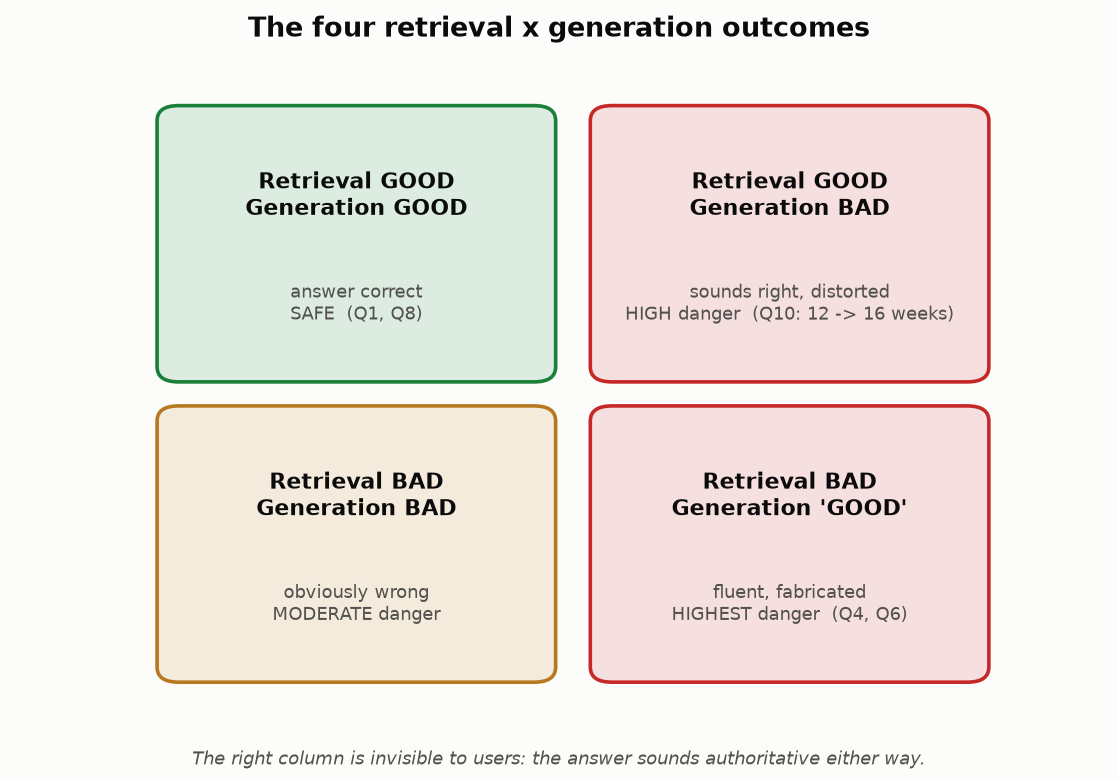

<sub>🖼️ *The four retrieval × generation outcomes, with this dataset's examples*</sub>

### The Challenge
For each pattern (A: retrieval succeeds, generation fails; B: retrieval fails, generation "succeeds"; C; D):
1. Identify the specific queries
2. Explain the root cause
3. Propose an automated detection strategy and a fix

> 🔮 **Predict:** before you run the verdict cell: (A) SHIP · (B) SHIP WITH CAUTION · (C) BLOCK. And which single failure decides it?

### Steps
1. Use `inspect_query(id)` to examine any query in full (works for all 16)
2. Run the check-coverage matrix: which check caught which failure?
3. Run the verdict cell
4. Write your analysis in the markdown cell at the end

In [ ]:
# ── Helper: deep-dive into any query (1–16) ──
def inspect_query(query_id):
    """Print the full pipeline for one query: docs → answer → ground truth → every score we computed."""
    item, s = ITEMS[query_id], scores_df.loc[query_id]
    print(f"🔬 Query {query_id} ({item['source']}): \"{item['query']}\"")
    print("\n--- Retrieved documents ---")
    for i, (doc, rel) in enumerate(zip(item["retrieved_docs"], item["relevance_labels"]), 1):
        print(f"  {i}. [{'✅ relevant' if rel else '·  not relevant'}] {doc[:95]}")
    print(f"\n--- Generated answer ---\n  {item['generated_answer']}")
    print(f"\n--- Ground truth (current handbook) ---\n  {item['ground_truth']}")
    print(f"\n--- Scores ---\n  Precision@5 {s['precision@5']:.2f} · MRR {s['mrr@5']:.2f} · word overlap {s['rule_based']:.2f} · "
          f"NLI {s['nli_entailment']:.2f} · number flags {s['number_flags']}")
    print(f"  Context sufficient: {s['sufficient']} · SME outcome: {s['outcome']}")
    print("─" * 70)

inspect_query(10)   # Pattern A: good retrieval, distorted generation
inspect_query(13)   # Pattern C: faithful to a stale doc
# 💡 Try inspect_query(4), inspect_query(14) or inspect_query(16) too.

In [ ]:
# @title 🧰 Chart helper: draw_coverage_matrix() paints which check caught which failure (hidden · 21 lines · expand if curious)
def draw_coverage_matrix(caught, escaped, row_labels):
    """caught: DataFrame (failure × check) of booleans → a caught/missed grid; the last column is the SME."""
    fig, ax = plt.subplots(figsize=(10.5, 4.2))
    for r, qid in enumerate(caught.index):
        for c, name in enumerate(caught.columns):
            hit = caught.loc[qid, name]
            ax.add_patch(plt.Rectangle((c + 0.04, r + 0.06), 0.92, 0.88, color=STATUS["good"] if hit else "#e9e8e4",
                                       alpha=0.35 if hit else 1.0))
            ax.text(c + 0.5, r + 0.5, "caught" if hit else "missed", ha="center", va="center", fontsize=10,
                    color="#0b0b0b" if hit else "#9a9893", weight="bold" if hit else "normal")
    n_rows, n_cols = caught.shape
    ax.axvline(n_cols - 1, color="#52514e", lw=1.2, ls="--")
    ax.set_xlim(0, n_cols); ax.set_ylim(n_rows, 0); ax.grid(False)
    ax.set_xticks([c + 0.5 for c in range(n_cols)]); ax.set_xticklabels(list(caught.columns), fontsize=9.5)
    ax.xaxis.tick_top(); ax.tick_params(length=0)
    ax.set_yticks([r + 0.5 for r in range(n_rows)]); ax.set_yticklabels(row_labels, fontsize=10)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    fig.suptitle(f"Every failure trips an automated check except Query {', '.join(map(str, escaped))}: "
                 "only the SME reference catches it", x=0.01, ha="left", fontsize=13, weight="bold")
    plt.tight_layout(); plt.show()

In [ ]:
# 🧮 Which check catches which failure? One row per bad behavior, one column per check you built.
BAD = {6: "Q6 pets: invented policy", 10: "Q10 leave: 12 → 16 weeks", 13: "Q13 desk: stale 2023 doc",
       14: "Q14 401(k) loan: invented", 16: "Q16 time off: over-refusal"}
CHECKS = {   # True = this check flags the query
    "No relevant\ndoc (T4)":          lambda i: not scores_df.loc[i, "has_relevant"],
    "Number\ncheck (T5)":             lambda i: bool(scores_df.loc[i, "number_flags"]),
    "NLI entailment\n< 0.5 (T6)":      lambda i: scores_df.loc[i, "nli_entailment"] < 0.5,
    "Sufficiency vs.\nbehavior (T9)":  lambda i: scores_df.loc[i, "sufficient"] == scores_df.loc[i, "abstained"],
    "SME vs. current\nhandbook (T8)":  lambda i: not scores_df.loc[i, "good"],
}
caught = pd.DataFrame({name: [bool(f(i)) for i in BAD] for name, f in CHECKS.items()}, index=list(BAD))
# 👀 Look at: the first four columns run without a human; the last one needs an SME with the current handbook
auto = caught.iloc[:, :-1].sum(axis=1)
escaped = auto.index[auto == 0].tolist()
draw_coverage_matrix(caught, escaped, list(BAD.values()))
print(f"Automated checks per failure: {auto.to_dict()}")

In [ ]:
# 🧾 The ship decision, computed from everything above
answered_now = scores_df[scores_df["outcome"] != "abstained"]
wrong_now = answered_now[answered_now["outcome"] == "wrong"]
silent = [i for i in wrong_now.index                      # wrong answers no automated check flagged
          if scores_df.loc[i, "nli_entailment"] >= 0.5 and not scores_df.loc[i, "number_flags"]]
wrong_rate = len(wrong_now) / len(scores_df)
# 👀 Look at: two triggers, either one blocks: too many wrong answers, or one wrong answer nothing automated can see
decision = "BLOCK" if wrong_rate > 0.10 or silent else ("SHIP WITH CAUTION" if len(wrong_now) else "SHIP")

verdict(decision, [
    f"**{len(wrong_now)} of {len(answered_now)} answers are wrong** ({wrong_rate:.0%} of all {len(scores_df)} questions; "
    f"selective accuracy {1 - len(wrong_now) / len(answered_now):.0%}). Each sounds authoritative.",
    f"**{len(silent)} wrong answer(s) pass every automated check** ({silent}): a stale doc outranked the current one. "
    "Fix: expire archived versions, add freshness metadata, detect conflicting chunks at index time.",
    f"**Answered {len(ins_answered)} of {len(ins)} insufficient-context questions.** Fix: abstain-and-route prompt plus "
    f"a validated sufficiency autorater; re-measure coverage vs. selective accuracy (gate result: {gate.selective_accuracy:.0%} "
    f"at {gate.coverage:.0%} coverage).",
    f"**Query 10 changed a number** that a 10-line check catches. Fix: block answers whose numbers aren't in the context.",
    "**Before re-testing:** grow the eval set from real employee questions with SME labels; 16 questions can't "
    "support a launch percentage.",
])

### ✍️ Your Analysis

**Write your findings here** (double-click to edit):

### Pattern A: Retrieval Succeeds, Generation Fails
**Query ID(s):** *...*  **What went wrong?** *...*  **Automated detection:** *...*  **Fix:** *...*

### Pattern B: Retrieval Fails, Generation "Succeeds"
**Query ID(s):** *...*  **Why is this more dangerous than both failing?** *...*  **Guardrail:** *...*

### Pattern C: Faithful but Wrong
**Query ID(s):** *...*  **Why did every metric miss it?** *...*  **What would catch it?** *...*

### Pattern D: Wrong Abstention Behavior (both directions)
**Answered when it should have declined:** *...*  **Declined when it should have answered:** *...*  **How would you test both directions in your CI pipeline (continuous integration)?** *...*

### Your verdict
**Ship / ship with caution / block?** *...*  **The one fix you'd do first, and why:** *...*

### Checkpoint ✅
You should see two full query deep-dives, a check-coverage matrix and a 🛑 verdict banner.

### Expected Output
Matrix title: *"Every failure trips an automated check except Query 13: only the SME reference catches it"*.
```
Automated checks per failure: {6: 3, 10: 2, 13: 0, 14: 3, 16: 2}
```
```
🛑 BLOCK
• 4 of 14 answers are wrong (25% of all 16 questions; selective accuracy 71%). Each sounds authoritative.
• 1 wrong answer(s) pass every automated check ([13]): a stale doc outranked the current one. ...
• Answered 3 of 4 insufficient-context questions. ... (gate result: 82% at 69% coverage).
• Query 10 changed a number that a 10-line check catches. ...
• Before re-testing: grow the eval set from real employee questions with SME labels; ...
```
**What just happened:** the rule has two triggers: BLOCK if more than 10% of all questions get a wrong answer, or if any wrong answer passes every automated check. Both fired: 4 of 16 wrong, and Query 13 invisible to everything except the SME. Fix Query 10's number and the first trigger still fires (3 of 16 is 19%), while the second doesn't move.

🗣️ **Say it to a colleague:** "Every failure tripped a cheap check except the stale one. Automate the cheap checks; budget humans for the truth."

Then complete the four patterns and your own verdict in the cell above.

---

## ✅ Validation / Success Criteria

You're done when:

- [ ] 📊 The dataset loaded and the tiles show **0** abstentions on the offline set
- [ ] 🤔 The 🔍 Think First reflection is written (5 questions)
- [ ] 📏 Retrieval metrics computed for all 12 queries (mean hit rate 0.83)
- [ ] 📝 3+ grounding criteria designed; the number check flags **Query 10** only
- [ ] 🧪 Both faithfulness scorers ran: NLI false alarms 3/9, word-overlap misses 1/3; the denial scored 1.00 on overlap
- [ ] 🔬 Trace analysis assigns a root cause to all 12 offline queries
- [ ] 🏭 You found the **faithful-but-wrong** answer (Query 13) and the offline vs. production gap
- [ ] 🧱 Sufficiency labels, the 2×3 table and the three-policy comparison ran
- [ ] 💥 10+ balanced stress tests designed (should-answer ≥ should-abstain)
- [ ] ⚠️ Check-coverage matrix ran, Patterns A–D documented and a verdict rendered

---

## 🛠️ Troubleshooting

| Symptom | Likely Cause | Fix |
|---------|-------------|-----|
| `ModuleNotFoundError: sentence_transformers` | Package not installed | Re-run the install cell and restart the kernel |
| `NameError: name 'insight' is not defined` | The 🎨 Lab kit cell was skipped | Run the lab kit cell in Task 1 |
| NLI model download hangs or fails | Network issue in Colab | Restart the runtime; the model is ~90 MB and may take 1–2 min |
| `RuntimeError` on NLI model loading | CUDA/GPU issue | The model runs on CPU by default; restart the runtime |
| NLI scores differ in the 3rd decimal from the checkpoint | Different `sentence-transformers`/`torch` build | Expected; the pattern (which queries pass/fail) should match |
| `KeyError: 13` in Task 9 or 11 | Task 8's cells weren't run | Run Task 8 top to bottom first |
| Rule-based faithfulness looks too high | Word overlap can't see changed facts | That's the lesson of Task 6 (Query 10) |
| `ZeroDivisionError` in metrics | No relevant docs | The provided functions handle this; check you didn't edit them |

---

## 🚀 Stretch Goal / Extension

1. **Claim-level faithfulness** is now Challenge 5 below (🌶️🌶️🌶️): score each sentence separately and see what happens to Query 8's false alarm and to Query 13.
2. **Over-refusal detector:** for every abstention, run NLI with the context as premise and the refusal as hypothesis. Which refusals are *contradicted* by the context?
3. **Freshness check:** add a `version_date` to each doc and flag any answer whose supporting doc is older than another retrieved doc on the same topic. Does it catch Query 13? (Challenge 2 below builds a version that needs no metadata.)
4. **Risk–coverage curve:** give each query a sufficiency *score* (share of key facts found) and sweep the threshold from 0 to 1. Plot coverage vs. selective accuracy.

---

### 🏆 Challenge exercises

Five challenges; the 🌶️ count is the difficulty. Each starter cell runs as shipped; edit the `TODO`s and re-run until the auto-check shows ✅. Worked solutions are in the instructor solution file.

#### 🌶️ Challenge 1: Break the number check, then fix it

**Stakes:** a number check that accepts any number found in *any* retrieved text certifies a wrong reimbursement limit whenever an off-topic doc happens to mention it.

Task 5's number check compares the answer's numbers with **all five** retrieved docs, not only the relevant ones.

1. Write a **wrong** answer to Query 2 (*"What is the expense reimbursement limit for client dinners?"*; truth: $150 per person) that the current check passes.
2. Write `unsupported_numbers_v2(item)` so it flags your trap and still flags Queries 10 and 14, with **no** flags on any answer the SME marked correct.

<details><summary>💡 Hint</summary>

Read the four *off-topic* docs Query 2 retrieved: each carries a dollar amount. A number that's "in the context" can come from the wrong policy. For the fix, `relevance_labels` tells you which docs are about the question.
</details>

In [ ]:
# 🌶️ Challenge 1: edit the two TODOs, then re-run
my_trap = "..."   # TODO: a WRONG answer to Query 2 whose numbers all appear in its retrieved docs

def unsupported_numbers_v2(item):
    # TODO: fix the flaw. As shipped, this is Task 5's check unchanged.
    return unsupported_numbers(item)

q2 = ITEMS[2]
if my_trap.strip() in ("", "..."):
    print("✏️ Part 1: write my_trap first.")
else:
    trap_item = {**q2, "generated_answer": my_trap}
    nums = numbers_in(my_trap)
    broke = bool(nums) and "150" not in nums and not unsupported_numbers(trap_item)
    print(("✅" if broke else "❌") + f" Part 1: the original check flags {unsupported_numbers(trap_item) or 'nothing'} in your trap"
          + ("" if broke else " (you need a wrong amount, not 150, that it lets through)"))
    print(("✅" if unsupported_numbers_v2(trap_item) else "❌") + f" Part 2a: v2 flags your trap: {unsupported_numbers_v2(trap_item)}")
correct_ids = scores_df.index[scores_df["outcome"] == "correct"].tolist()
missed = [i for i in (10, 14) if not unsupported_numbers_v2(ITEMS[i])]
false_alarms = [i for i in correct_ids if unsupported_numbers_v2(ITEMS[i])]
print(("✅" if not missed else "❌") + " Part 2b: v2 still flags Queries 10 and 14" + (f" (missed {missed})" if missed else ""))
print(("✅" if not false_alarms else "❌") + f" Part 2c: no false alarms on the {len(correct_ids)} correct answers"
      + (f" (flagged {false_alarms})" if false_alarms else ""))

#### 🌶️🌶️ Challenge 2: Design a stale-version detector

**Stakes:** two versions of one policy in the index is the normal state of every handbook mid-update, and the retriever has no reason to prefer the new one.

Nothing automated caught Query 13: the archived $500 policy and the current $1,000 policy were both retrieved, and the model copied the first. An old version of the same policy is the most convincing distractor there is: same topic, same words, different number.

Write `conflict_flag(docs, labels)` that returns `True` when two **relevant** docs give **different amounts for the same thing**. The test suite: Query 13 (must flag), the other 15 queries (must not), and four planted cases, two real conflicts with no "archived" tag and two near-misses that aren't conflicts.

The starter flags any relevant doc containing "archived". It catches Query 13. Run it to see what else it gets wrong.

<details><summary>💡 Hint</summary>

Require two things: (1) the docs disagree on a dollar amount (a regex such as `\$\s?(\d[\d,]*(?:\.\d+)?)` extracts amounts); (2) they're about the same thing. A cheap proxy for (2): they share at least 3 content words besides numbers (reuse `tokenize` and `STOP_WORDS`). A keyword rule fitted to the one case you've seen is how evaluators overfit.
</details>

In [ ]:
# 🌶️🌶️ Challenge 2: replace the naive rule with a real detector
from itertools import combinations   # handy for comparing every pair of docs

def conflict_flag(docs, labels):
    """True if two relevant docs give different amounts for the same thing."""
    # TODO: replace this keyword rule; it fits the one case you've seen
    return any("archived" in d.lower() for d, r in zip(docs, labels) if r)

PLANTED = [  # (name, docs, relevance labels, should_flag)
    ("planted: mileage, two versions, no tag",
     ["Mileage is reimbursed at $0.65 per mile for business travel.",
      "Business travel mileage is reimbursed at $0.70 per mile."], [1, 1], True),
    ("planted: client meals, two policies disagree",
     ["Client meals are capped at $120 per person.",
      "Client entertainment expenses are capped at $150 per person per meal."], [1, 1], True),
    ("planted: home office, different items",
     ["Home office equipment stipends of up to $1,000 are available.",
      "Internet costs are reimbursed up to $50/month for remote workers."], [1, 1], False),
    ("planted: archived but consistent",
     ["Parking (2023 handbook, archived): passes cost $50/month.",
      "Parking passes are available at a subsidized rate of $50/month in the company garage."], [1, 1], False),
]
cases = [(f"Query {i}", ITEMS[i]["retrieved_docs"], ITEMS[i]["relevance_labels"], i == 13) for i in ITEMS] + PLANTED
errors = [(name, should) for name, docs, labels, should in cases if conflict_flag(docs, labels) != should]
for name, should in errors:
    print(f"  ❌ {name}: should {'flag' if should else 'NOT flag'}")
print(("✅" if not errors else "❌") + f" {len(cases) - len(errors)}/{len(cases)} cases right")

#### 🌶️🌶️🌶️ Challenge 3: Make the call on a sufficiency gate

**Stakes:** "only refuse when the context is insufficient" sounds free, but at a 10% base rate more than half of a good autorater's refusals can land on questions it should have answered.

Your team validated an LLM sufficiency autorater (Task 9) on 200 SME-labelled questions: it flags **85%** of insufficient contexts (TPR) and passes **90%** of sufficient ones (TNR). The proposal is to abstain whenever it flags. Planning assumptions for 10,000 questions a week (illustrative, not measured): 10% have insufficient context; the system answers those wrong 70% of the time; it answers sufficient-context questions correctly 92% of the time.

For one week with the gate on, compute:
1. `wrong_prevented`: wrong answers the gate turns into abstentions
2. `correct_lost`: correct answers the gate turns into abstentions
3. `refusal_precision`: share of the gate's abstentions that were on truly insufficient context
4. `break_even`: how many times worse a wrong answer must be than an unneeded refusal for the gate to pay off
5. `tnr_needed`: the TNR at which 80% of the gate's abstentions would be justified (TPR unchanged)

Then **make the call** in one sentence: would you ship this gate on a benefits assistant, where a wrong 401(k) answer means an HR escalation and a refusal means a two-minute lookup?

<details><summary>💡 Hint</summary>

Draw the 2×2: (sufficient / insufficient) × (gate flags / passes). Flagged insufficient = 10,000 × 0.10 × 0.85. Flagged sufficient = 10,000 × 0.90 × (1 − 0.90). Each flagged question was going to be right or wrong *before* the gate; the gate removes both kinds. For part 5, solve flagged_insufficient ÷ (flagged_insufficient + flagged_sufficient) = 0.80 for TNR.
</details>

In [ ]:
# 🌶️🌶️🌶️ Challenge 3: fill in the five numbers (None = not attempted yet)
N, P_INSUFF, WRONG_IF_INSUFF, RIGHT_IF_SUFF, TPR, TNR = 10_000, 0.10, 0.70, 0.92, 0.85, 0.90

wrong_prevented = None    # TODO
correct_lost = None       # TODO
refusal_precision = None  # TODO (a share, 0–1)
break_even = None         # TODO
tnr_needed = None         # TODO (a rate, 0–1)
my_call = "..."           # TODO: one sentence, ship the gate or not, and why

import base64 as _b64
_expected = json.loads(_b64.b64decode("eyJ3cm9uZ19wcmV2ZW50ZWQiOiA2NjcuMCwgImNvcnJlY3RfbG9zdCI6IDEwODMuMCwgInJlZnVzYWxfcHJlY2lzaW9uIjogMC40ODU3MTQyODU3MTQyODU3LCAiYnJlYWtfZXZlbiI6IDEuNjIzNjg4MTU1OTIyMDM5LCAidG5yX25lZWRlZCI6IDAuOTc2Mzg4ODg4ODg4ODg4OX0="))   # encoded so the answers aren't in plain sight
for name, ref in _expected.items():
    val = globals()[name]
    if val is None:
        print(f"  ✏️ {name}: not attempted")
    else:
        ok = abs(val - ref) <= 0.01 * abs(ref) + 1e-3
        print(f"  {'✅' if ok else '❌'} {name} = {val:,.3f}" + ("" if ok else "  (re-check your 2×2)"))
print("📝 Your call:", my_call)

#### 🌶️🌶️ Challenge 4: Right digits, wrong unit

**Stakes:** a payroll help assistant tells a manager that overtime starts after 40 hours *a day*; the handbook says *a workweek*. Every digit is in the docs, both of your automated faithfulness checks pass it, and the overtime gets under-paid. (A fictional handbook with simplified teaching rules.)

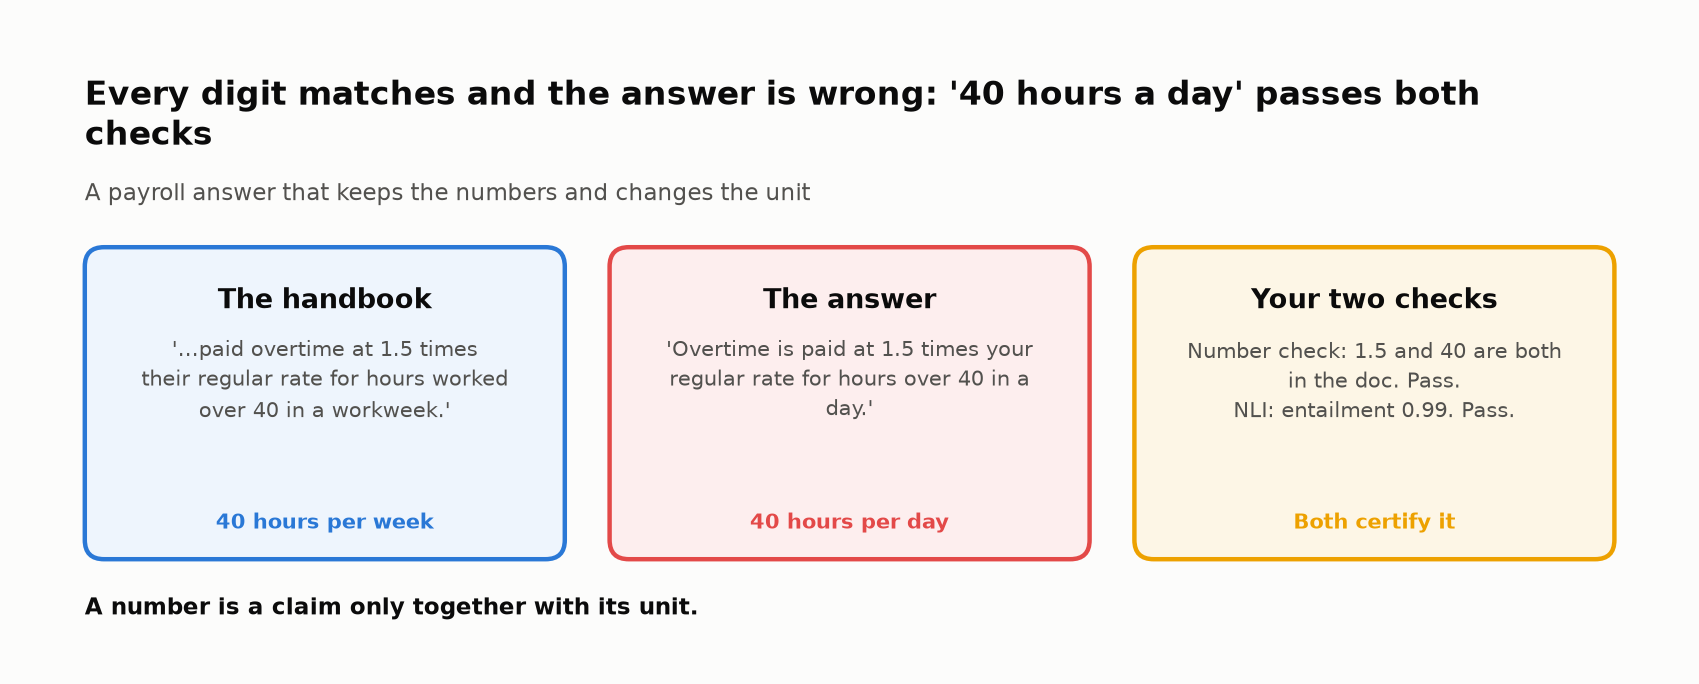
<sub>🖼️ *The number check verifies digits and NLI verifies gist. Neither reads "in a day".*</sub>

The collapsed 🧰 cell holds 12 answers from a payroll and payments handbook: 6 **traps** that keep every number and change its unit (per day vs. per workweek, $ vs. %, cents vs. dollars, hours vs. days, weeks vs. months) and 6 **faithful paraphrases** of the same sentences. The starter scores the traps with Task 5's digits-only check and with NLI.

Rewrite `unit_flags(answer, context)` so it returns the quantities in the answer that the context doesn't state *with the same unit*. The auto-check wants all 6 traps flagged, no flags on the 6 paraphrases or on the 10 lab answers the SME marked correct, and Queries 10 and 14 still flagged.

<details><summary>💡 Hint</summary>

Bind each number to the unit words that follow it, up to the next number or punctuation mark, plus a `$` just before it. Map synonyms to one canonical unit with the `UNITS` dict (`"workweek"` and `"weeks"` → `"week"`, `"x"` → `"times"`) and ignore every other word, or "per year" vs. "a year" will false-alarm. An answer's quantity is supported if the context has the same number with at least the same units.
</details>

In [ ]:
# @title 🧰 Fixtures for Challenge 4: 12 payroll and payments answers (6 unit traps, 6 paraphrases), their NLI scores, and the auto-check (hidden · 55 lines · expand after you've tried)
PAY_CASES = [  # (handbook sentence, assistant's answer, answer_is_wrong): a fictional payroll and payments handbook
    ("Non-exempt employees are paid overtime at 1.5 times their regular rate for hours worked over 40 in a workweek.",
     "Overtime is paid at 1.5 times your regular rate for hours over 40 in a day.", True),
    ("Non-exempt employees are paid overtime at 1.5 times their regular rate for hours worked over 40 in a workweek.",
     "You get 1.5x your regular pay for any hours past 40 in a week.", False),
    ("Business mileage is reimbursed at 70 cents per mile.",
     "Business mileage is reimbursed at $70 per mile.", True),
    ("Business mileage is reimbursed at 70 cents per mile.",
     "Mileage is reimbursed at 70 cents a mile.", False),
    ("Employees may contribute up to 6% of salary to the stock purchase plan.",
     "Employees may contribute up to $6 of salary to the stock purchase plan.", True),
    ("Employees may contribute up to 6% of salary to the stock purchase plan.",
     "You can put up to 6% of your salary into the stock purchase plan.", False),
    ("Card disputes must be filed within 60 days of the statement date.",
     "Card disputes must be filed within 60 hours of the statement date.", True),
    ("Card disputes must be filed within 60 days of the statement date.",
     "You have 60 days from the statement date to file a card dispute.", False),
    ("Payroll for hourly staff runs every 2 weeks, on Friday.",
     "Hourly staff are paid every 2 months, on a Friday.", True),
    ("Payroll for hourly staff runs every 2 weeks, on Friday.",
     "Hourly staff get paid every 2 weeks, on Fridays.", False),
    ("Overdue invoices are charged a late fee of 1.5% per month on the unpaid balance.",
     "Overdue invoices are charged a late fee of 1.5% per year on the unpaid balance.", True),
    ("Overdue invoices are charged a late fee of 1.5% per month on the unpaid balance.",
     "Late invoices pick up a 1.5% fee each month on whatever is still unpaid.", False),
]
PAY_NLI = nli_model.predict([(doc, ans) for doc, ans, _ in PAY_CASES], apply_softmax=True)[:, 1]   # P(entailment)

def check_unit_flags(unit_flags):
    """Score unit_flags() on the payroll traps and paraphrases, then on the lab's own 16 answers."""
    traps = [i for i, (_, _, wrong) in enumerate(PAY_CASES) if wrong]
    fine = [i for i, (_, _, wrong) in enumerate(PAY_CASES) if not wrong]
    flags = lambda f, i: f(PAY_CASES[i][1], PAY_CASES[i][0])
    digits_only = lambda answer, context: sorted(numbers_in(answer) - numbers_in(context))
    caught = [i for i in traps if flags(unit_flags, i)]
    false_alarms = [i for i in fine if flags(unit_flags, i)]
    relevant = lambda i: " ".join(d for d, r in zip(ITEMS[i]["retrieved_docs"], ITEMS[i]["relevance_labels"]) if r)
    correct = scores_df.index[scores_df["outcome"] == "correct"].tolist()
    lab_alarms = [i for i in correct if unit_flags(ITEMS[i]["generated_answer"], relevant(i))]
    lab_missed = [i for i in (10, 14) if not unit_flags(ITEMS[i]["generated_answer"], relevant(i))]
    for n, i in enumerate(traps, 1):
        yours = flags(unit_flags, i)
        print(f"  Trap {n}: NLI {PAY_NLI[i]:.2f} · yours: {'🚩 ' + str(yours) if yours else 'pass'} · \"{PAY_CASES[i][1]}\"")
    tiles([
        ("Digits-only check (Task 5)", f"{sum(bool(flags(digits_only, i)) for i in traps)}/{len(traps)}", "unit traps caught", "critical"),
        ("NLI entailment < 0.5", f"{sum(bool(PAY_NLI[i] < 0.5) for i in traps)}/{len(traps)}", "unit traps caught", "warning"),
        ("Your unit_flags()", f"{len(caught)}/{len(traps)}", f"{len(false_alarms)} false alarms on paraphrases",
         "good" if len(caught) == len(traps) and not false_alarms else "critical"),
    ])
    print(("✅" if len(caught) == len(traps) else "❌") + f" 1. Flags all {len(traps)} unit traps (now {len(caught)})")
    print(("✅" if not false_alarms else "❌") + f" 2. No flags on the {len(fine)} faithful paraphrases"
          + (f" (flagged {false_alarms})" if false_alarms else ""))
    print(("✅" if not lab_alarms else "❌") + f" 3. No flags on the {len(correct)} lab answers the SME marked correct"
          + (f" (flagged {lab_alarms})" if lab_alarms else ""))
    print(("✅" if not lab_missed else "❌") + " 4. Still flags Queries 10 and 14" + (f" (missed {lab_missed})" if lab_missed else ""))

In [ ]:
# 🌶️🌶️ Challenge 4 starter: runs as shipped. Make unit_flags() read units, then re-run.
UNITS = {"%": "%", "percent": "%", "x": "times", "times": "times", "cents": "cents",
         "hour": "hour", "hours": "hour", "day": "day", "days": "day", "week": "week", "weeks": "week",
         "workweek": "week", "month": "month", "months": "month", "year": "year", "years": "year"}

def unit_flags(answer, context):
    """Quantities in the answer that the context doesn't state WITH THE SAME UNIT.
    TODO: as shipped this is Task 5's digits-only check, so '40 in a day' passes against '40 in a workweek'."""
    return sorted(numbers_in(answer) - numbers_in(context))

check_unit_flags(unit_flags)

#### 🌶️🌶️🌶️ Challenge 5: Score claims, not answers

**Stakes:** answer-level NLI flagged 3 of 9 faithful answers in Task 6, so half of its flags on the offline set were false alarms; wire it to an alert and the on-call engineer learns to ignore it before the week it fires on a real one.

Task 6 asked the model one question per answer: do all the relevant docs, joined, entail the whole answer? Rewrite `claim_faithfulness(answer, docs, labels)` to score each claim (sentence) separately and combine the claim scores into one 0–1 score. `split_claims()` and `entail(premise, hypothesis)` are ready in the collapsed 🧰 cell. The auto-check wants:

1. at most 1 false alarm (score < 0.5) on the 9 answers the SME judged faithful;
2. every unfaithful answer (Queries 4, 6, 10 and 14) still below 0.5;
3. a planted answer, Query 12's plus one invented sentence, below 0.5.

When all three pass, read the last line the checker prints, about Query 13.

<details><summary>💡 Hint</summary>

Three design choices, each with a trap. (1) **A claim's premise:** one doc at a time misses claims that combine two docs (Query 5's last sentence), and all docs joined is what failed in Task 6; try both and keep the better score. (2) **Combining claims:** an average lets two true sentences outvote a false one; try it and watch Query 10. (3) **No relevant docs** means nothing supports the answer.
</details>

In [ ]:
# @title 🧰 Helpers for Challenge 5: split_claims(), entail(), the planted answer and the auto-check (hidden · 35 lines · expand if curious)
def split_claims(answer):
    """One claim per sentence (good enough for these short policy answers)."""
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", answer) if s.strip()]

def entail(premise, hypothesis):
    """P(premise entails hypothesis), from the Task 6 cross-encoder."""
    return float(nli_model.predict([(premise, hypothesis)], apply_softmax=True)[0][1])

PLANTED_12 = ITEMS[12]["generated_answer"] + " Vested options can also be transferred to a family member."
FAITHFUL_OFFLINE = [i for i in range(1, 13) if SME[i][0]]      # the SME found every claim supported
UNFAITHFUL = [i for i in ITEMS if SME[i][0] is False]           # Queries 4, 6, 10, 14

def check_claim_scorer(scorer, threshold=0.5):
    """Run a faithfulness scorer on the SME-labelled answers, the planted answer and Query 13."""
    s = {i: scorer(ITEMS[i]["generated_answer"], ITEMS[i]["retrieved_docs"], ITEMS[i]["relevance_labels"])
         for i in FAITHFUL_OFFLINE + UNFAITHFUL + [13]}
    planted = scorer(PLANTED_12, ITEMS[12]["retrieved_docs"], ITEMS[12]["relevance_labels"])
    false_alarms = [i for i in FAITHFUL_OFFLINE if s[i] < threshold]
    misses = [i for i in UNFAITHFUL if s[i] >= threshold]
    tiles([
        ("False alarms", f"{len(false_alarms)}/{len(FAITHFUL_OFFLINE)}", f"faithful answers flagged: {false_alarms}",
         "good" if len(false_alarms) <= 1 else "critical"),
        ("Misses", f"{len(misses)}/{len(UNFAITHFUL)}", f"unfaithful answers passed: {misses}", "good" if not misses else "critical"),
        ("Planted answer", f"{planted:.2f}", "Query 12 + one invented sentence", "good" if planted < threshold else "critical"),
        ("Query 13 (stale doc)", f"{s[13]:.2f}", "faithful to the 2023 handbook", "warning"),
    ])
    print(("✅" if len(false_alarms) <= 1 else "❌")
          + f" 1. At most 1 false alarm on the {len(FAITHFUL_OFFLINE)} faithful offline answers (now {len(false_alarms)}: {false_alarms})")
    print(("✅" if not misses else "❌") + f" 2. Every unfaithful answer scores < {threshold}" + (f" (passed: {misses})" if misses else ""))
    print(("✅" if planted < threshold else "❌") + f" 3. The planted answer scores < {threshold} (now {planted:.2f})")
    before = scores_df.loc[13, "nli_entailment"]
    print(f"🔎 Query 13: {s[13]:.2f} (Task 6's answer-level NLI gave {before:.2f}). "
          + ("Your scorer is MORE sure of the stale answer than Task 6's was." if s[13] > before + 0.01 else
             "Once checks 1-3 pass, look at this number again."))
    return s

In [ ]:
# 🌶️🌶️🌶️ Challenge 5 starter: runs as shipped. Score claims, not answers, then re-run.
def claim_faithfulness(answer, docs, labels):
    """0-1: how well the relevant docs support the answer.
    TODO: score each claim in split_claims(answer) with entail(premise, claim), then combine the claim scores.
    As shipped this is Task 6's answer-level NLI: one premise (all relevant docs), one hypothesis (the whole answer)."""
    return nli_faithfulness(answer, docs, labels)["entailment_score"]

claim_scores = check_claim_scorer(claim_faithfulness)

## 🎯 Key Takeaways

### 📒 Insight Ledger

| Task | What you saw | Rule of thumb |
|---|---|---|
| 2 · Dataset | 12 of 12 answers confident, including 2 with zero evidence | Count abstentions on day one; zero is a red flag |
| 4 · Retrieval metrics | Hit rate 83%, Precision@5 0.40; Queries 2–3 buried at rank 3 but answered fine | Headline recall@K at the K you pass to the LLM; rank metrics are diagnostics |
| 5 · Number check | 10 lines of regex flagged exactly Query 10 (16 weeks) | Verify numbers, dates and amounts deterministically first |
| 6 · Faithfulness | NLI caught 12 → 16 but false-alarmed on 3 of 9 good answers; a flat denial scored 1.00 on word overlap | Measure a scorer's misses and false alarms before trusting it; never gate on word counts |
| 7 · Traces | 6 of 12 landed in an uninformative MIXED bucket, 3 of them because the NLI scorer failed | Define retrieval failure as missing evidence; check the grader first |
| 8 · Faithful ≠ correct | Query 13 passed every automated check and was wrong; 83% offline vs 25% production | Score correctness against a trusted reference; doc-derived test sets inflate scores |
| 9 · Sufficiency | Answered 3 of 4 insufficient-context questions; gate: 71% → 82% accuracy at 88% → 69% coverage | Report coverage *and* selective accuracy; test abstention in both directions |
| 10 · Stress tests | Balanced suite: should-answer ≥ should-abstain | For every "should refuse" probe, write a "should answer" one |
| 11 · Verdict | 🛑 BLOCK: 4 wrong answers; only the SME reference caught Query 13 | Ship decisions need the failure *shapes*, not one average |

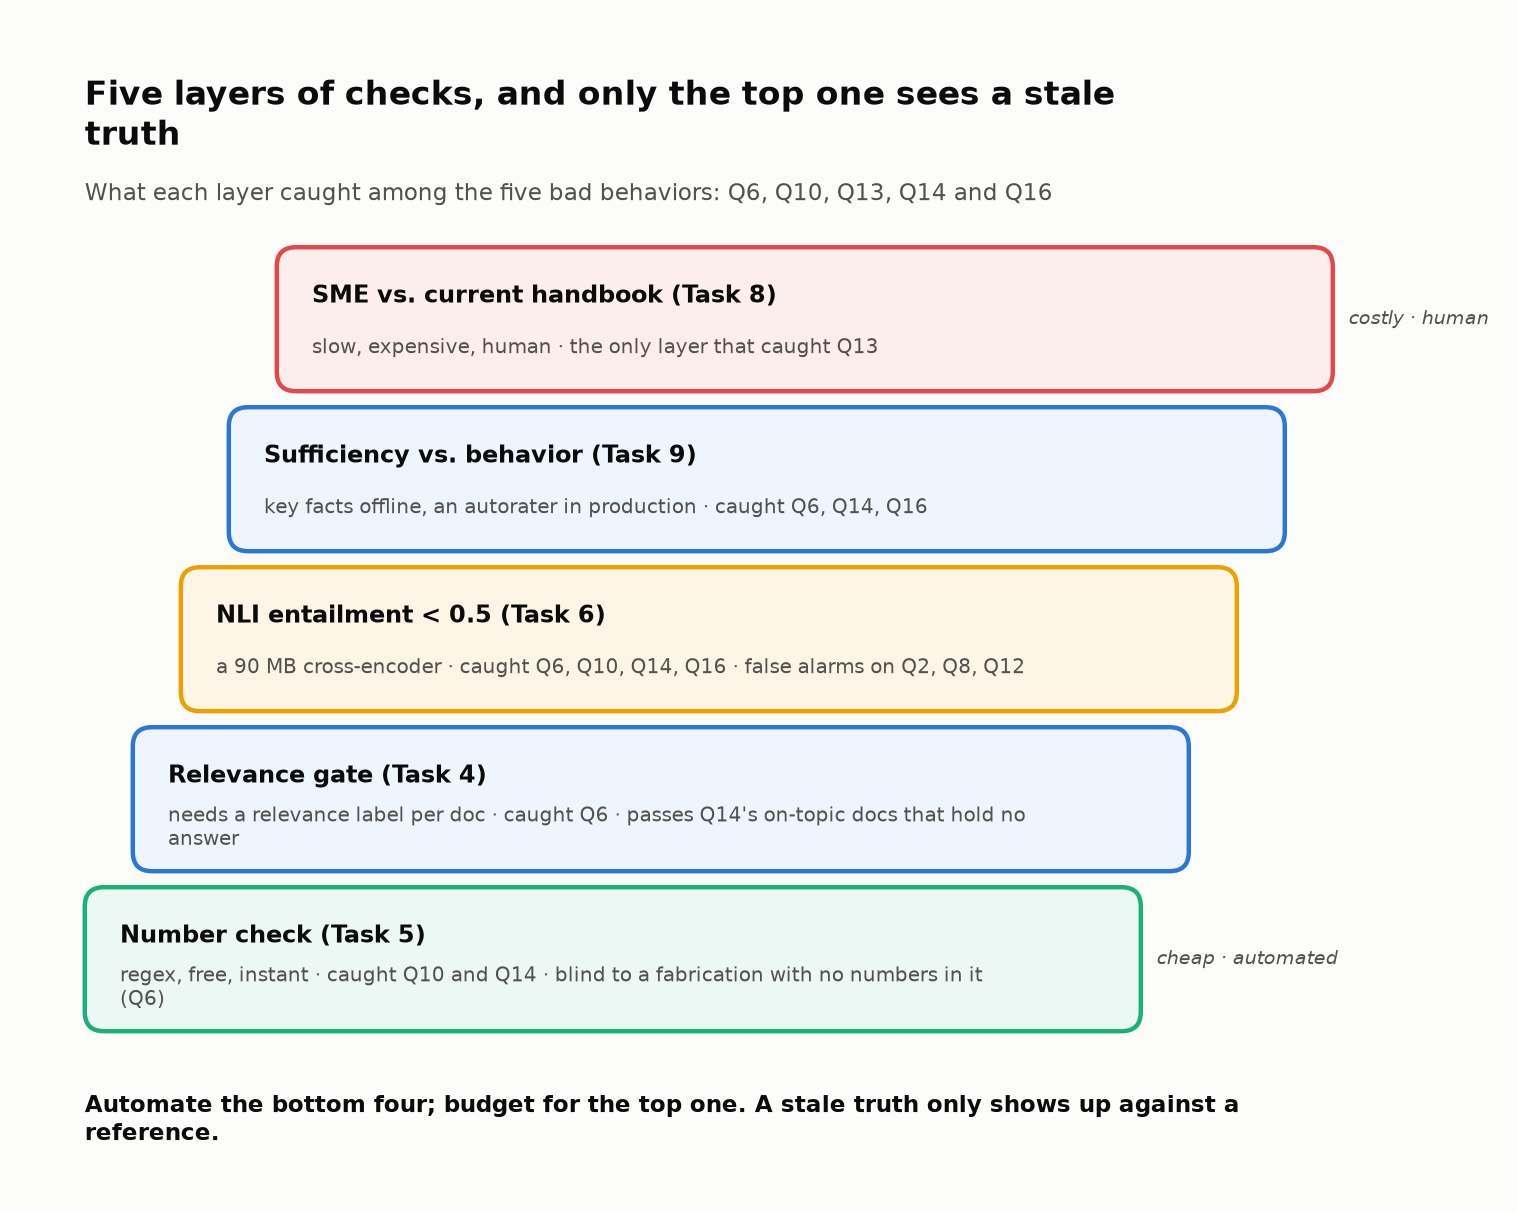
<sub>🖼️ *The layers you built, cheapest at the bottom. Only the top one, a person with the current handbook, saw Query 13.*</sub>

### The big ideas
1. 🔀 **Score retrieval and generation separately**, then ask a third question: *was the context sufficient?*
2. ⚖️ **Faithful ≠ correct.** Faithfulness certifies agreement with the context, stale or not.
3. 🧱 **Relevant ≠ sufficient.** On-topic docs without the answer invite confident hallucinations.
4. 🙊 **Measure abstention in both directions**, with coverage and selective accuracy side by side.
5. 🧪 **Evaluate your evaluators.** Every scorer has a miss rate and a false-alarm rate.
6. 🏭 **Doc-derived test sets flatter you.** Use them for A/B regressions, not launch claims.
7. 🔢 **A number is a claim only with its unit, and an answer is only as faithful as its weakest claim** (Challenges 4 and 5).

---

## 👀 What's Next?

- **Lab 04b (supplemental):** build a real RAG pipeline and measure what this lab took as given: chunking (with token-level metrics), hybrid search, reranking, and generation behind a `PROVIDER` switch.
- **Module 05: Evaluating Generative Outputs:** LLM-as-judge with binary verdicts, calibration against human labels (TPR/TNR, κ), and judge biases. Module 05 teaches you to validate judges like the faithfulness and sufficiency judges you sketched here.

---

## 🏋️ Exercises

### Exercise 1 — Beginner: Precision@k
Compute precision@k from retrieved doc **ids** (the form you'll use in Lab 04b), given retrieved doc ids and a set of relevant ids.

<details>
<summary>Show solution</summary>

```python
def precision_at_k_ids(retrieved, relevant, k):
    top = retrieved[:k]
    return sum(d in relevant for d in top) / k
print(precision_at_k_ids(["d1","d2","d3"], {"d1","d3"}, 3))
```
</details>

### Exercise 2 — Applied: MRR
Compute the mean reciprocal rank over several queries.

<details>
<summary>Show solution</summary>

```python
def mrr(runs):  # runs: list of (retrieved_ids, relevant_set)
    total = 0.0
    for retrieved, relevant in runs:
        total += next((1 / r for r, d in enumerate(retrieved, 1) if d in relevant), 0.0)
    return total / len(runs)
print(mrr([(["d2","d1"], {"d1"}), (["d3","d4"], {"d9"})]))  # (0.5 + 0) / 2 = 0.25
```
</details>

### Exercise 3 — Challenge: Selective accuracy
Given `(answered: bool, correct: bool)` pairs, return coverage and selective accuracy.

<details>
<summary>Show solution</summary>

```python
def selective(results):
    answered = [c for a, c in results if a]
    coverage = len(answered) / len(results)
    sel_acc = sum(answered) / len(answered) if answered else float("nan")
    return coverage, sel_acc
print(selective([(True, True), (True, False), (False, False), (True, True)]))  # (0.75, 0.667)
```
</details>

### Exercise 4 — Stretch: Stress test retrieval
Add 3 near-duplicate *distractor* documents (e.g., an archived version of a policy) and re-measure precision, MRR and sufficiency. Which metric moves, and which one stays green while the answer gets worse? (Open-ended.)